# Category-Conditioned Sketch Generation with Variational Autoencoders

**Author:** Ashwin Parthasarathy

This project develops a sketch generator in PyTorch using human-drawn examples from Google Quick, Draw!. Development begins with a one-category feasibility experiment before expanding to category-conditioned generation.

Evaluation will examine randomly generated samples, recognizability, diversity, and similarity to training examples. Model choices and quality claims will be grounded in the experiments recorded in this notebook.

## 1. Environment and reproducibility

In [1]:
import hashlib
import json
import random
import shutil
import sys
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

In [2]:
PROJECT_ROOT = Path.cwd()
SEED = 42

In [3]:
assert (PROJECT_ROOT / ".git").is_dir(), (
    "Open this notebook from the sketch-generation-vae repository root."
)

# Seed the random generators used for data selection and model training.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Project:", PROJECT_ROOT)
print("Python:", sys.version.split()[0])
print("Executable:", sys.executable)
print("PyTorch:", torch.__version__)
print("Device:", device)

Project: /Users/ashlabs/Projects/Masters in AI/github/sketch-generation-vae
Python: 3.14.0
Executable: /Users/ashlabs/Projects/Masters in AI/github/sketch-generation-vae/.venv/bin/python
PyTorch: 2.15.0
Device: mps


## 2. Dataset acquisition and initial inspection

The project uses human-drawn sketches from [Google Quick, Draw!](https://github.com/googlecreativelab/quickdraw-dataset), released under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

The initial feasibility experiment uses the apple category. The supplied NumPy file contains flattened 28 × 28 grayscale images rendered from simplified human drawings. Rasterization is preprocessing; these are not AI-generated training examples.

The bitmap file does not retain contributor identifiers, country information, or recognition flags. Consequently, it does not support contributor-independent splitting or demographic analysis.

This section inspects the downloaded data. Training, validation, and test partitions will be created separately before model development.

In [4]:
DATA_URL = (
    "https://storage.googleapis.com/"
    "quickdraw_dataset/full/numpy_bitmap/apple.npy"
)
DATA_PATH = PROJECT_ROOT / "data/raw/apple.npy"
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    temporary_path = DATA_PATH.with_suffix(".npy.partial")
    print("Downloading apple sketches...", flush=True)

    # Publish the file only after the download finishes.
    with urlopen(DATA_URL, timeout=60) as response:
        expected_bytes = response.headers.get("Content-Length")
        with temporary_path.open("wb") as destination:
            shutil.copyfileobj(response, destination)

    if expected_bytes is not None:
        assert temporary_path.stat().st_size == int(expected_bytes), (
            "Download size mismatch; do not use this file."
        )

    temporary_path.replace(DATA_PATH)

In [5]:
# Memory mapping avoids loading the entire category into RAM.
apple_images = np.load(DATA_PATH, mmap_mode="r", allow_pickle=False)

assert apple_images.ndim == 2 and apple_images.shape[1] == 28 * 28
assert apple_images.dtype == np.uint8
assert len(apple_images) >= 30000

In [6]:
file_hash = hashlib.sha256()
with DATA_PATH.open("rb") as handle:
    for chunk in iter(lambda: handle.read(1024 * 1024), b""):
        file_hash.update(chunk)

source_record = {
    "dataset": "Google Quick, Draw!",
    "category": "apple",
    "url": DATA_URL,
    "license": "CC BY 4.0",
    "verified_at_utc": datetime.now(timezone.utc).isoformat(),
    "sha256": file_hash.hexdigest(),
    "bytes": DATA_PATH.stat().st_size,
    "shape": list(apple_images.shape),
    "dtype": str(apple_images.dtype)
}

(PROJECT_ROOT / "reports").mkdir(exist_ok=True)
with (PROJECT_ROOT / "reports/apple_source.json").open("w") as handle:
    json.dump(source_record, handle, indent=2)

print("Images:", len(apple_images))
print("Image dimensions: 28 × 28")
print("Data type:", apple_images.dtype)
print(f"File size: {DATA_PATH.stat().st_size / 1024**2:.1f} MiB")
print("SHA-256:", source_record["sha256"])

Images: 144722
Image dimensions: 28 × 28
Data type: uint8
File size: 108.2 MiB
SHA-256: a70df0030c146cfe4aa9a17aa2a320d5f64ac166fdc3d2cfb439b8322fd8bb0d


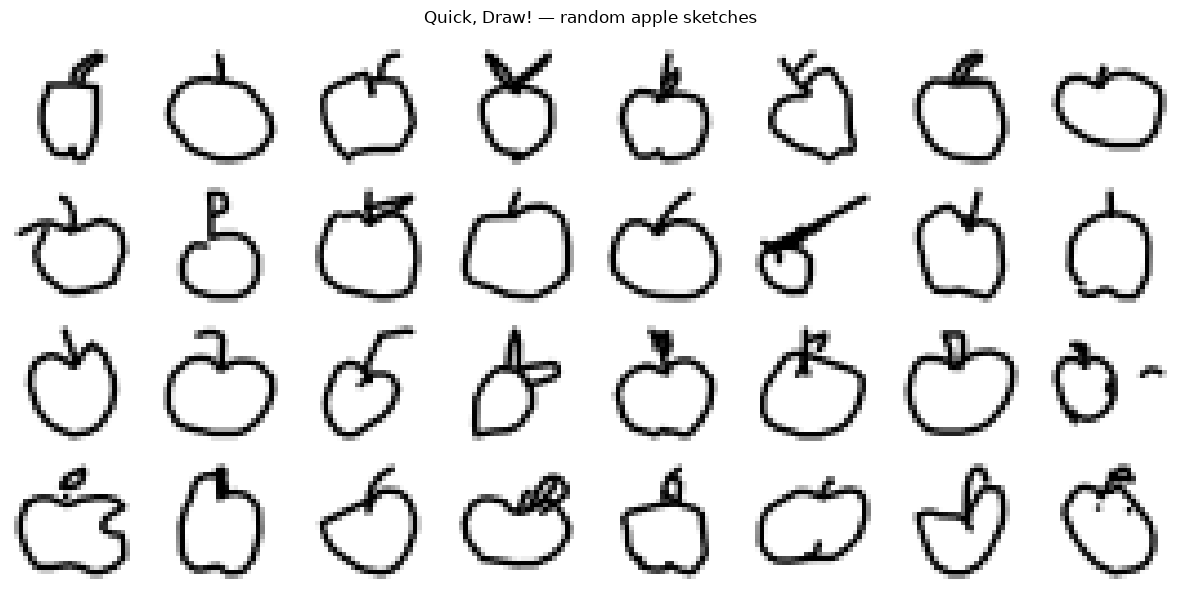

In [7]:
preview_rng = np.random.default_rng(SEED)
preview_indices = preview_rng.choice(len(apple_images), size=32, replace=False)

fig, axes = plt.subplots(4, 8, figsize=(12, 6))

for axis, index in zip(axes.flat, preview_indices):
    axis.imshow(
        apple_images[index].reshape(28, 28),
        cmap="gray_r",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )
    axis.axis("off")

fig.suptitle("Quick, Draw! — random apple sketches")
fig.tight_layout()
plt.savefig("figures/random_apple_sketches.png")
plt.show()
plt.close(fig)

## 3. Automated audit and reproducible data splits

Blank images and exact pixel duplicates are excluded automatically. Duplicate detection uses SHA-256 hashes of the original 28 × 28 pixel arrays; it does not detect near duplicates or identify individual contributors.

A seeded random sample of 30,000 unique, nonblank sketches forms the feasibility dataset: 24,000 training, 3,000 validation, and 3,000 test images.

The manifest records each image's row index in the downloaded NumPy file and its pixel hash. Combined with the source file's SHA-256 checksum, this allows the same selection to be reconstructed without committing the raw images.

Validation guides model development. Test images remain unused until the final evaluation. No subjective filtering is applied to drawing quality.

In [8]:
# Audit all images before selecting the experiment subset.
unique_rows = []
seen_hashes = set()
blank_count = 0
duplicate_count = 0

for source_index in range(len(apple_images)):
    pixels = apple_images[source_index]

    # Quick, Draw! bitmaps use zero for background and larger values for ink.
    if not np.any(pixels):
        blank_count += 1
        continue

    pixel_hash = hashlib.sha256(pixels.tobytes()).hexdigest()

    if pixel_hash in seen_hashes:
        duplicate_count += 1
        continue

    seen_hashes.add(pixel_hash)
    unique_rows.append({
        "source_index": source_index,
        "category": "apple",
        "pixel_sha256": pixel_hash,
    })

unique_inventory = pd.DataFrame(unique_rows)
assert len(unique_inventory) >= 30000

# Shuffle once, reproducibly, then assign nonoverlapping partitions.
split_rng = np.random.default_rng(SEED)
selected_positions = split_rng.choice(len(unique_inventory), size=30000, replace=False)

apple_manifest = unique_inventory.iloc[selected_positions].reset_index(drop=True)

apple_manifest["split"] = (
    ["train"] * 24_000
    + ["validation"] * 3000
    + ["test"] * 3000
)

assert apple_manifest["source_index"].is_unique
assert apple_manifest["pixel_sha256"].is_unique

processed_dir = PROJECT_ROOT / "data/processed"
processed_dir.mkdir(parents=True, exist_ok=True)
apple_manifest.to_csv(processed_dir / "apple_split_manifest.csv", index=False)

audit_record = {
    "source_file_sha256": source_record["sha256"],
    "source_images": len(apple_images),
    "blank_images_excluded": blank_count,
    "duplicate_images_excluded": duplicate_count,
    "unique_nonblank_images": len(unique_inventory),
    "selected_images": len(apple_manifest),
    "seed": SEED,
    "split_counts": {
        split: int(count)
        for split, count in apple_manifest["split"].value_counts().items()
    }
}

with (PROJECT_ROOT / "reports/apple_data_audit.json").open("w") as handle:
    json.dump(audit_record, handle, indent=2)

print("Blank images excluded:", blank_count)
print("Exact duplicate images excluded:", duplicate_count)
print("Unique nonblank images:", len(unique_inventory))
print("\nSelected split counts:")
print(apple_manifest["split"].value_counts())

# Release the temporary audit structures; keep the selected manifest.
del seen_hashes, unique_rows

Blank images excluded: 0
Exact duplicate images excluded: 1
Unique nonblank images: 144721

Selected split counts:
split
train         24000
validation     3000
test           3000
Name: count, dtype: int64


## 4. Image preprocessing and data loading

The feasibility model uses the original 28 × 28 grayscale bitmaps. Pixel intensities are divided by 255, producing floating-point tensors in [0, 1]. Zero represents background and one represents maximum stroke intensity.

No augmentation is applied in the initial experiment. This establishes a baseline before introducing additional preprocessing choices.

Training examples are shuffled using a seeded random generator. Validation examples retain a fixed order. Test data is reserved for final evaluation, and no test loader is created at this stage.

Each tensor has shape (1, 28, 28), where the first dimension is the grayscale channel. Data loading uses num_workers=0 for straightforward execution in Jupyter on the local Mac.

In [9]:
from torch.utils.data import DataLoader, Dataset

In [10]:
BATCH_SIZE = 128

class SketchDataset(Dataset):
    """Read selected sketches from the downloaded bitmap array.

    Parameters
    ----------
    images : numpy.ndarray
        Original uint8 bitmap array shaped (number_of_images, 784).
    manifest : pandas.DataFrame
        Rows containing source_index for the desired split.
    """

    def __init__(self, images, manifest):
        self.images = images
        self.source_indices = manifest["source_index"].to_numpy(
            dtype=np.int64, copy=True
        )

    def __len__(self):
        """Return the number of selected sketches."""
        return len(self.source_indices)

    def __getitem__(self, index):
        """Return one normalized grayscale sketch.

        Parameters
        ----------
        index : int
            Position within this dataset's selected rows.

        Returns
        -------
        torch.Tensor
            Float32 image shaped (1, 28, 28), with values in [0, 1].
        """
        source_index = self.source_indices[index]

        # Copy the read-only memory-mapped row into writable float32 memory.
        pixels = np.array(self.images[source_index], dtype=np.float32, copy=True).reshape(1, 28, 28)
        pixels /= 255.0

        return torch.from_numpy(pixels)


train_dataset = SketchDataset(apple_images, apple_manifest.loc[apple_manifest["split"].eq("train")])
validation_dataset = SketchDataset(apple_images, apple_manifest.loc[apple_manifest["split"].eq("validation")])

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Check dataset entries directly without advancing the training shuffle.
example_batch = torch.stack([train_dataset[index] for index in range(8)])

assert example_batch.shape == (8, 1, 28, 28)
assert example_batch.dtype == torch.float32
assert torch.isfinite(example_batch).all()
assert example_batch.min() >= 0 and example_batch.max() <= 1

print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Training batches per epoch:", len(train_loader))
print("Example batch shape:", tuple(example_batch.shape))
print(
    "Pixel range:",
    f"[{example_batch.min().item():.3f}, "
    f"{example_batch.max().item():.3f}]"
)

Training images: 24000
Validation images: 3000
Training batches per epoch: 188
Example batch shape: (8, 1, 28, 28)
Pixel range: [0.000, 1.000]


## 5. Variational autoencoder architecture

The encoder reduces each 28 × 28 sketch to a feature representation, then predicts the mean and log variance of a 16-dimensional diagonal Gaussian distribution.

During training, the reparameterization step samples a latent vector:

z = mean + standard deviation × random noise

This allows reconstruction gradients to reach the encoder while retaining stochastic sampling. The decoder maps the latent vector back to a 28 × 28 image. It returns logits; applying sigmoid converts these into pixel values in [0, 1].

The decoder uses nearest-neighbor upsampling followed by convolution. Its dimensions progress from 7 × 7 to 14 × 14 and then 28 × 28.

The model supports two distinct evaluations:

- Reconstruction: encode a real sketch and decode its latent representation.
- Generation: sample a latent vector from the standard normal prior and decode it without supplying an input sketch.

Good reconstruction alone does not establish good generation. Both will be inspected separately.

This implementation follows the VAE framework introduced by [Kingma and Welling (2014)](https://arxiv.org/abs/1312.6114).

In [11]:
from torch import nn

LATENT_DIM = 16

class SketchVAE(nn.Module):
    """Encode and generate 28 × 28 grayscale sketches.

    Parameters
    ----------
    latent_dim : int, default=16
        Number of latent dimensions.
    """

    def __init__(self, latent_dim=16):
        super().__init__()
        self.latent_dim = latent_dim

        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU()
        )
        self.mean_head = nn.Linear(128, latent_dim)
        self.log_variance_head = nn.Linear(128, latent_dim)

        self.decoder_input = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64 * 7 * 7),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (64, 7, 7)),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(32, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 1, kernel_size=3, padding=1)
        )

    def encode(self, images):
        """Predict the approximate posterior distribution.

        Parameters
        ----------
        images : torch.Tensor
            Sketches shaped (batch, 1, 28, 28).

        Returns
        -------
        tuple[torch.Tensor, torch.Tensor]
            Mean and log variance, each shaped (batch, latent_dim).
        """
        features = self.encoder(images)
        return self.mean_head(features), self.log_variance_head(features)

    def reparameterize(self, mean, log_variance):
        """Sample latent vectors while preserving the gradient path.

        Parameters
        ----------
        mean : torch.Tensor
            Posterior means shaped (batch, latent_dim).
        log_variance : torch.Tensor
            Posterior log variances with the same shape as mean.

        Returns
        -------
        torch.Tensor
            Sampled latent vectors shaped (batch, latent_dim).
        """
        standard_deviation = torch.exp(0.5 * log_variance)
        noise = torch.randn_like(standard_deviation)
        return mean + standard_deviation * noise

    def decode(self, latent):
        """Decode latent vectors into pixel logits.

        Parameters
        ----------
        latent : torch.Tensor
            Latent vectors shaped (batch, latent_dim).

        Returns
        -------
        torch.Tensor
            Pixel logits shaped (batch, 1, 28, 28).
        """
        return self.decoder(self.decoder_input(latent))

    def forward(self, images, sample=True):
        """Reconstruct images through the latent distribution.

        Parameters
        ----------
        images : torch.Tensor
            Normalized sketches shaped (batch, 1, 28, 28).
        sample : bool, default=True
            Sample the posterior if True; otherwise decode its mean.

        Returns
        -------
        tuple[torch.Tensor, torch.Tensor, torch.Tensor]
            Reconstruction logits, posterior means, and log variances.
        """
        mean, log_variance = self.encode(images)
        latent = (
            self.reparameterize(mean, log_variance)
            if sample else mean
        )
        return self.decode(latent), mean, log_variance


# Reset initialization so earlier notebook inspections do not change it.
torch.manual_seed(SEED)
vae = SketchVAE(latent_dim=LATENT_DIM).to(device)

# This shape check performs no optimization or posterior sampling.
vae.eval()
with torch.no_grad():
    logits, mean, log_variance = vae(
        example_batch.to(device), sample=False
    )

assert logits.shape == (8, 1, 28, 28)
assert mean.shape == log_variance.shape == (8, LATENT_DIM)
for tensor in (logits, mean, log_variance):
    assert torch.isfinite(tensor).all().item()

print("Parameters:", f"{sum(p.numel() for p in vae.parameters()):,}")
print("Reconstruction logits:", tuple(logits.shape))
print("Posterior mean:", tuple(mean.shape))
print("Posterior log variance:", tuple(log_variance.shape))

Parameters: 854,433
Reconstruction logits: (8, 1, 28, 28)
Posterior mean: (8, 16)
Posterior log variance: (8, 16)


## 6. Reconstruction loss and latent regularization

The VAE balances two objectives:

1. **Reconstruction:** binary cross-entropy compares the decoder's pixel logits with the input sketch. Losses are summed across all 784 pixels, then averaged across images. Grayscale intensities are used as soft targets.
2. **KL divergence:** an analytical penalty encourages the encoder's Gaussian distributions to remain close to a standard normal distribution. This supports generation from latent vectors sampled without an input image.

The baseline objective is:

**total loss = reconstruction loss + KL divergence**

Both terms are summed over their feature dimensions and averaged over images. Using these explicit reductions prevents the balance from changing accidentally with batch size.

Training samples latent vectors from the approximate posterior. Validation uses a separate, fixed stream of random noise so repeated evaluations are comparable without changing the training random-number stream.

Posterior-mean reconstructions will be displayed separately as deterministic diagnostics. They are not used as a substitute for sampled validation loss.

A lower loss does not guarantee recognizable or diverse generated sketches.

In [12]:
import torch.nn.functional as F


def vae_loss(logits, targets, mean, log_variance):
    """Calculate the VAE objective with per-image reductions.

    Parameters
    ----------
    logits : torch.Tensor
        Reconstruction logits shaped (batch, 1, 28, 28).
    targets : torch.Tensor
        Input intensities in [0, 1], with the same shape as logits.
    mean : torch.Tensor
        Posterior means shaped (batch, latent_dim).
    log_variance : torch.Tensor
        Posterior log variances with the same shape as mean.

    Returns
    -------
    tuple[torch.Tensor, torch.Tensor, torch.Tensor]
        Batch-average total, reconstruction, and KL losses.
    """
    reconstruction = F.binary_cross_entropy_with_logits(
        logits, targets, reduction="none"
    ).flatten(1).sum(dim=1).mean()

    kl = -0.5 * (
        1 + log_variance - mean.square() - log_variance.exp()
    ).sum(dim=1).mean()

    return reconstruction + kl, reconstruction, kl


def train_vae_epoch(model, loader, optimizer, device):
    """Train for one complete pass through the training loader.

    Parameters
    ----------
    model : SketchVAE
        VAE to update.
    loader : torch.utils.data.DataLoader
        Training image batches.
    optimizer : torch.optim.Optimizer
        Optimizer for model parameters.
    device : torch.device
        Device used for training.

    Returns
    -------
    dict[str, float]
        Image-weighted average total, reconstruction, and KL losses.
    """
    model.train()
    totals = np.zeros(3, dtype=np.float64)
    image_count = 0

    for images in loader:
        images = images.to(device)
        optimizer.zero_grad(set_to_none=True)

        logits, mean, log_variance = model(images, sample=True)
        losses = vae_loss(logits, images, mean, log_variance)

        if not all(torch.isfinite(loss).item() for loss in losses):
            raise FloatingPointError("Non-finite VAE training loss.")

        losses[0].backward()
        optimizer.step()

        count = images.shape[0]
        totals += np.array(
            [loss.detach().item() for loss in losses]
        ) * count
        image_count += count

    return dict(zip(
        ("total", "reconstruction", "kl"),
        (totals / image_count).tolist()
    ))


@torch.no_grad()
def evaluate_vae(model, loader, device, seed=12345):
    """Evaluate using reproducible posterior samples.

    Parameters
    ----------
    model : SketchVAE
        VAE to evaluate.
    loader : torch.utils.data.DataLoader
        Validation image batches in a fixed order.
    device : torch.device
        Device used for inference.
    seed : int, default=12345
        Seed for a separate CPU noise generator.

    Returns
    -------
    dict[str, float]
        Image-weighted average total, reconstruction, and KL losses.
    """
    model.eval()
    noise_generator = torch.Generator().manual_seed(seed)
    totals = np.zeros(3, dtype=np.float64)
    image_count = 0

    for images in loader:
        images = images.to(device)
        mean, log_variance = model.encode(images)

        # CPU-generated noise supports the same evaluation logic on MPS,
        # CUDA, or CPU without resetting the training RNG.
        noise = torch.randn(
            mean.shape, generator=noise_generator, dtype=mean.dtype
        ).to(device)

        latent = mean + torch.exp(0.5 * log_variance) * noise
        logits = model.decode(latent)
        losses = vae_loss(logits, images, mean, log_variance)

        if not all(torch.isfinite(loss).item() for loss in losses):
            raise FloatingPointError("Non-finite VAE validation loss.")

        count = images.shape[0]
        totals += np.array([loss.item() for loss in losses]) * count
        image_count += count

    return dict(zip(
        ("total", "reconstruction", "kl"),
        (totals / image_count).tolist()
    ))

## 7. Five-epoch feasibility experiment

The initial pilot trains the apple VAE for five epochs using Adam with a learning rate of 0.001. This short run checks training behavior, execution time, and whether sampling from the standard normal prior produces recognizable sketches.

Two fixed displays support interpretation:

- Validation inputs and reconstructions decoded from posterior means.
- Generated images decoded from fixed standard-normal latent vectors.

The generated samples are not selected for visual quality. The same latent vectors are reused each epoch to make changes easier to inspect.

Training and validation losses are recorded separately. Checkpoints include model parameters, optimizer state, configuration, history, and random-number states. The lowest validation objective determines the saved best checkpoint, but visual quality is assessed separately.

This is a feasibility experiment, not the final model evaluation. The test set remains untouched.

In [13]:
PILOT_EPOCHS = 5
LEARNING_RATE = 0.001

pilot_config = {
    "model": "single_category_convolutional_vae",
    "category": "apple",
    "latent_dim": LATENT_DIM,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs": PILOT_EPOCHS,
    "seed": SEED,
    "validation_noise_seed": 12345,
    "source_sha256": source_record["sha256"]
}

run_id = datetime.now(timezone.utc).strftime("apple_vae_pilot_%Y%m%dT%H%M%S_%fZ")
pilot_run_dir = PROJECT_ROOT / "runs" / run_id

for folder in ("figures", "reports", "checkpoints"):
    (pilot_run_dir / folder).mkdir(parents=True, exist_ok=False)

with (pilot_run_dir / "reports/config.json").open("w") as handle:
    json.dump(pilot_config, handle, indent=2)

apple_manifest.to_csv(pilot_run_dir / "reports/split_manifest.csv", index=False)

# Initialize a fresh model and reset the training shuffle for this run.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
train_loader.generator.manual_seed(SEED)

vae = SketchVAE(latent_dim=LATENT_DIM).to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=LEARNING_RATE)

# Fixed validation inputs; no training examples are used for reconstructions.
fixed_validation = torch.stack([validation_dataset[index] for index in range(8)]).to(device)

sample_generator = torch.Generator().manual_seed(SEED + 1)
fixed_latent = torch.randn(32, LATENT_DIM, generator=sample_generator).to(device)

torch.save(
    {
        "validation_images": fixed_validation.cpu(),
        "prior_latent": fixed_latent.cpu(),
    },
    pilot_run_dir / "checkpoints/fixed_display_inputs.pt"
)

pilot_history = []
best_validation = float("inf")

print("Run directory:", pilot_run_dir)
print("Prepared fresh model; training has not started.")

Run directory: /Users/ashlabs/Projects/Masters in AI/github/sketch-generation-vae/runs/apple_vae_pilot_20261109T190506_582028Z
Prepared fresh model; training has not started.


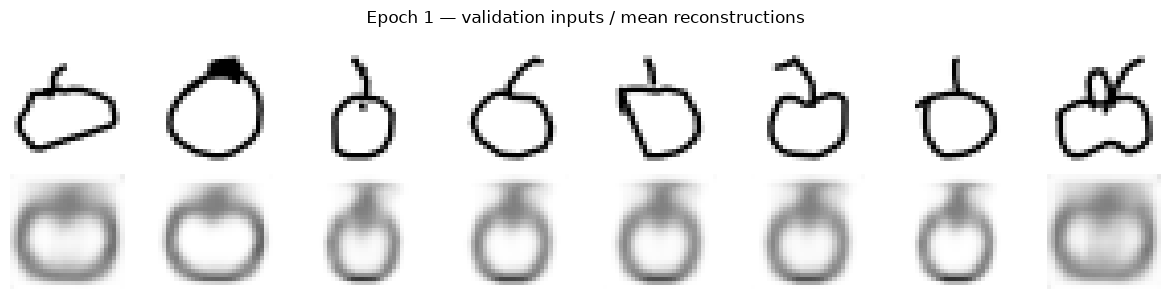

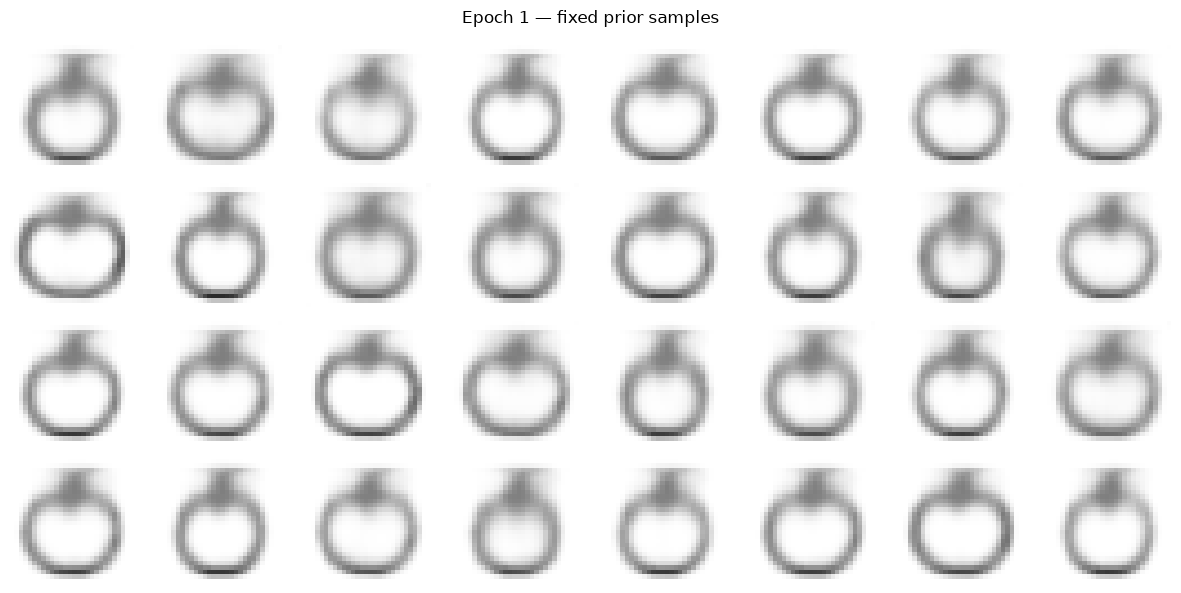

Epoch 1/5 | Train: 270.05 | Validation: 229.83 | Reconstruction: 225.16 | KL: 4.67 | Time: 1.9s


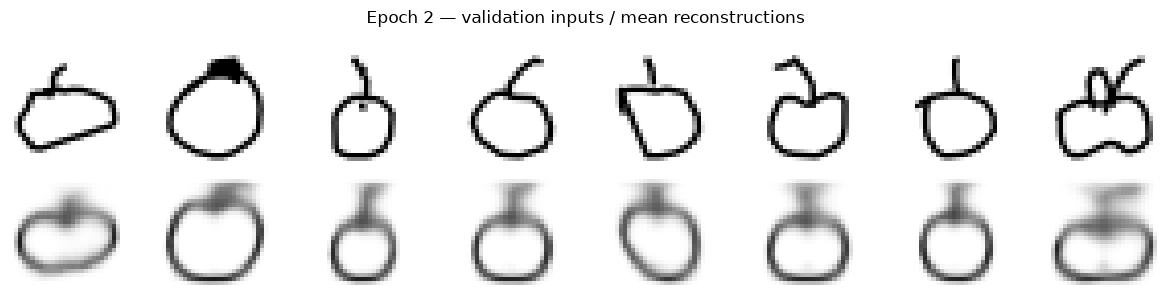

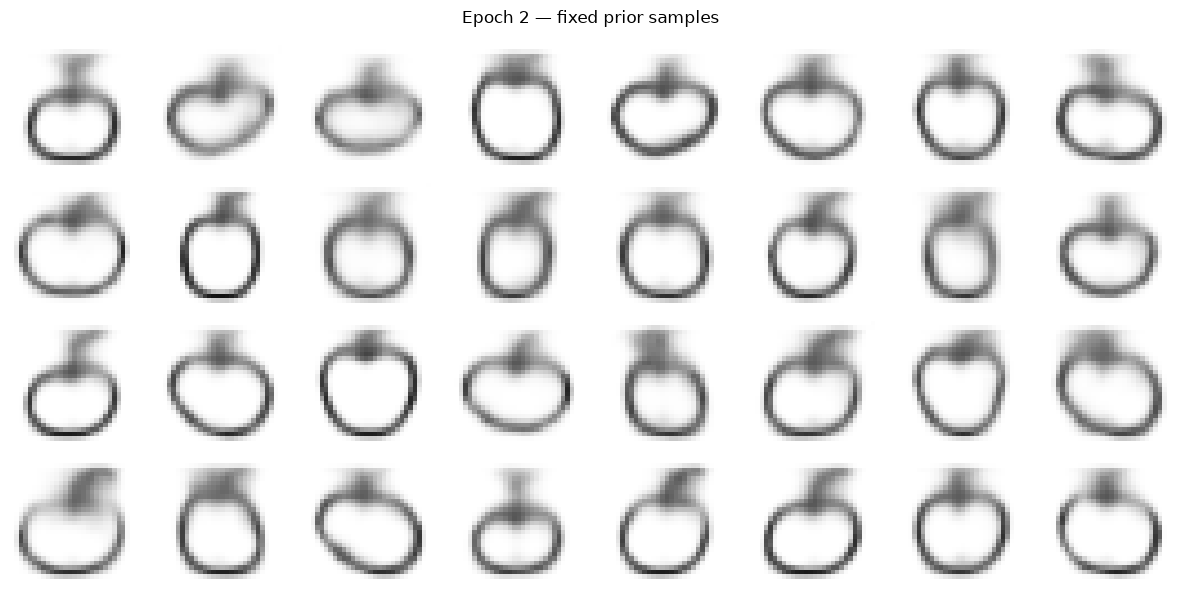

Epoch 2/5 | Train: 213.64 | Validation: 195.87 | Reconstruction: 184.54 | KL: 11.33 | Time: 1.7s


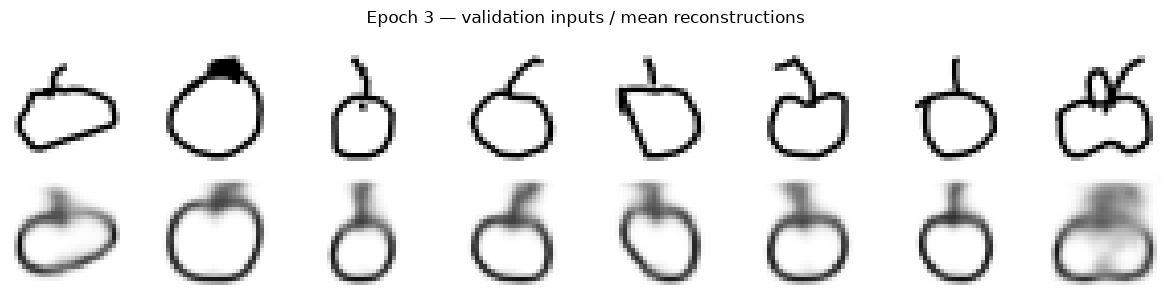

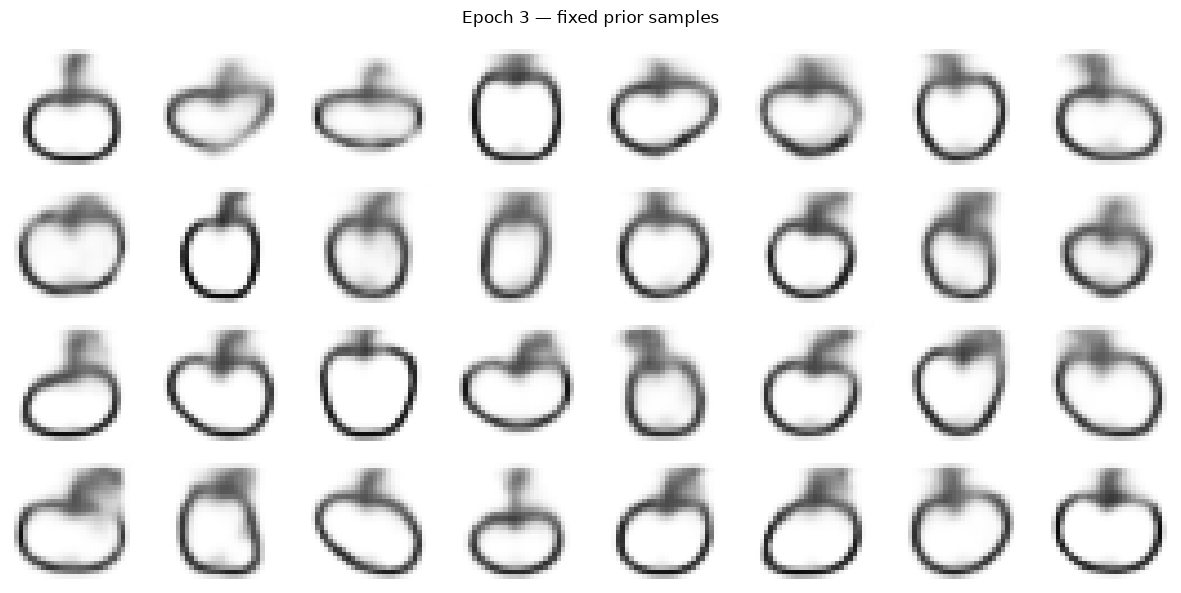

Epoch 3/5 | Train: 187.44 | Validation: 181.26 | Reconstruction: 167.29 | KL: 13.97 | Time: 1.7s


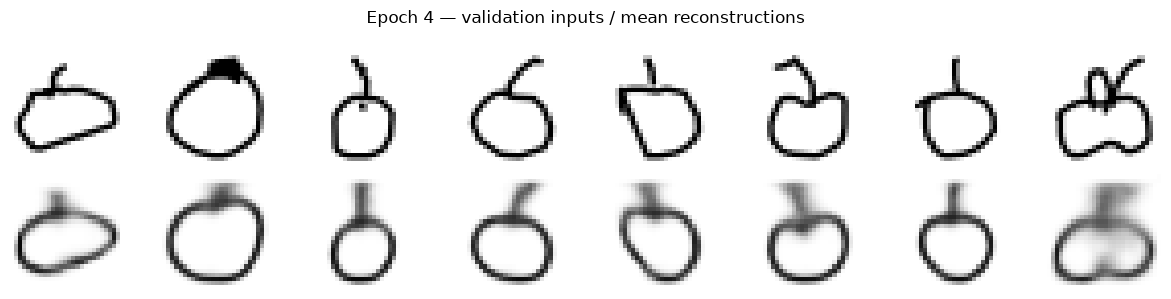

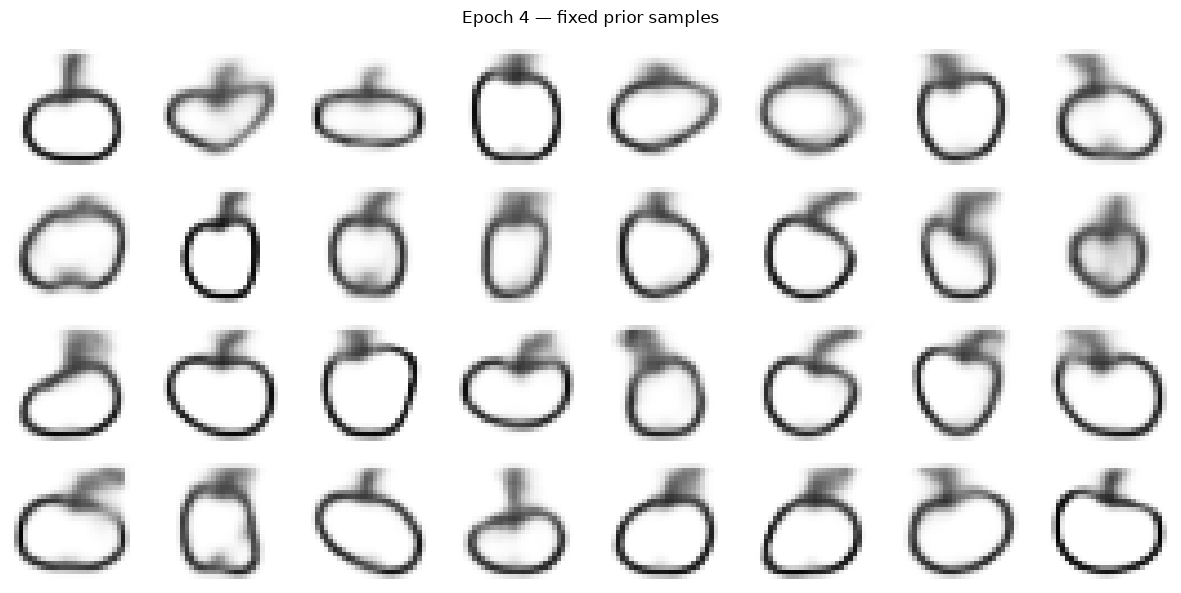

Epoch 4/5 | Train: 175.94 | Validation: 170.14 | Reconstruction: 154.16 | KL: 15.98 | Time: 1.7s


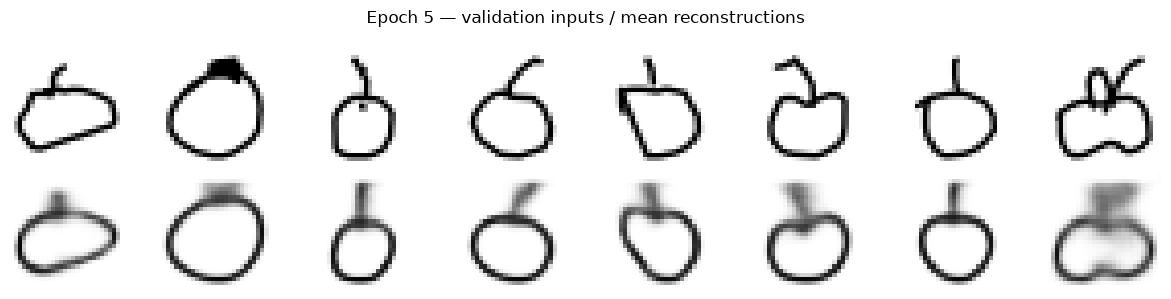

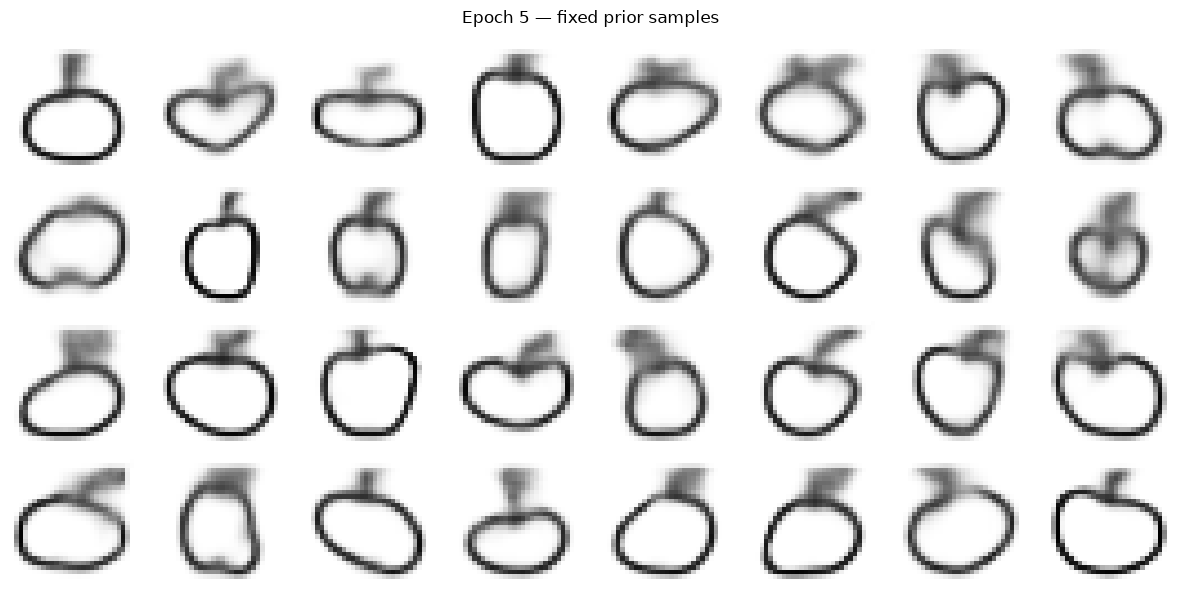

Epoch 5/5 | Train: 167.66 | Validation: 165.52 | Reconstruction: 147.66 | KL: 17.86 | Time: 1.7s


In [14]:
# Prevent accidental extra training if this cell is executed again.
if pilot_history or (pilot_run_dir / "checkpoints/latest.pt").exists():
    raise RuntimeError(
        "This run already has training progress. Resume from its checkpoint "
        "rather than rerunning this cell."
    )

for epoch in range(1, PILOT_EPOCHS + 1):
    started = perf_counter()

    train_metrics = train_vae_epoch(vae, train_loader, optimizer, device)
    validation_metrics = evaluate_vae(
        vae,
        validation_loader,
        device,
        seed=pilot_config["validation_noise_seed"]
    )

    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()

    pilot_history.append({
        "epoch": epoch,
        "seconds": perf_counter() - started,
        **{f"train_{key}": value for key, value in train_metrics.items()},
        **{
            f"validation_{key}": value
            for key, value in validation_metrics.items()
        }
    })

    improved = validation_metrics["total"] < best_validation
    best_validation = min(best_validation, validation_metrics["total"])

    checkpoint = {
        "epoch": epoch,
        "model": vae.state_dict(),
        "optimizer": optimizer.state_dict(),
        "config": pilot_config,
        "history": pilot_history,
        "best_validation": best_validation,
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "loader_rng": train_loader.generator.get_state()
    }
    if device.type == "mps":
        checkpoint["mps_rng"] = torch.mps.get_rng_state()
    elif device.type == "cuda":
        checkpoint["cuda_rng"] = torch.cuda.get_rng_state_all()

    latest_path = pilot_run_dir / "checkpoints/latest.pt"
    temporary_path = latest_path.with_suffix(".tmp")
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(latest_path)

    if improved:
        shutil.copy2(latest_path, pilot_run_dir / "checkpoints/best.pt")

    pd.DataFrame(pilot_history).to_csv(pilot_run_dir / "reports/training_history.csv", index=False)

    vae.eval()
    with torch.no_grad():
        reconstruction_logits, _, _ = vae(
            fixed_validation, sample=False
        )
        reconstructions = reconstruction_logits.sigmoid().cpu()
        generations = vae.decode(fixed_latent).sigmoid().cpu()

    # Reconstructions and prior generations answer different questions.
    fig, axes = plt.subplots(2, 8, figsize=(12, 3))
    for index in range(8):
        axes[0, index].imshow(
            fixed_validation[index, 0].cpu(),
            cmap="gray_r", vmin=0, vmax=1
        )
        axes[1, index].imshow(
            reconstructions[index, 0],
            cmap="gray_r", vmin=0, vmax=1
        )
    for axis in axes.flat:
        axis.axis("off")
    fig.suptitle(
        f"Epoch {epoch} — validation inputs / mean reconstructions"
    )
    fig.tight_layout()
    fig.savefig(
        pilot_run_dir / f"figures/reconstructions_{epoch:02d}.png",
        dpi=120, bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    fig, axes = plt.subplots(4, 8, figsize=(12, 6))
    for axis, generated in zip(axes.flat, generations):
        axis.imshow(
            generated[0],
            cmap="gray_r", vmin=0, vmax=1,
            interpolation="nearest"
        )
        axis.axis("off")
    fig.suptitle(f"Epoch {epoch} — fixed prior samples")
    fig.tight_layout()
    fig.savefig(
        pilot_run_dir / f"figures/generations_{epoch:02d}.png",
        dpi=120, bbox_inches="tight"
    )
    plt.savefig(f"figures/epoch_{epoch}_fixed_prior_samples")
    plt.show()
    plt.close(fig)

    print(
        f"Epoch {epoch}/{PILOT_EPOCHS} | "
        f"Train: {train_metrics['total']:.2f} | "
        f"Validation: {validation_metrics['total']:.2f} | "
        f"Reconstruction: {validation_metrics['reconstruction']:.2f} | "
        f"KL: {validation_metrics['kl']:.2f} | "
        f"Time: {pilot_history[-1]['seconds']:.1f}s",
        flush=True
    )

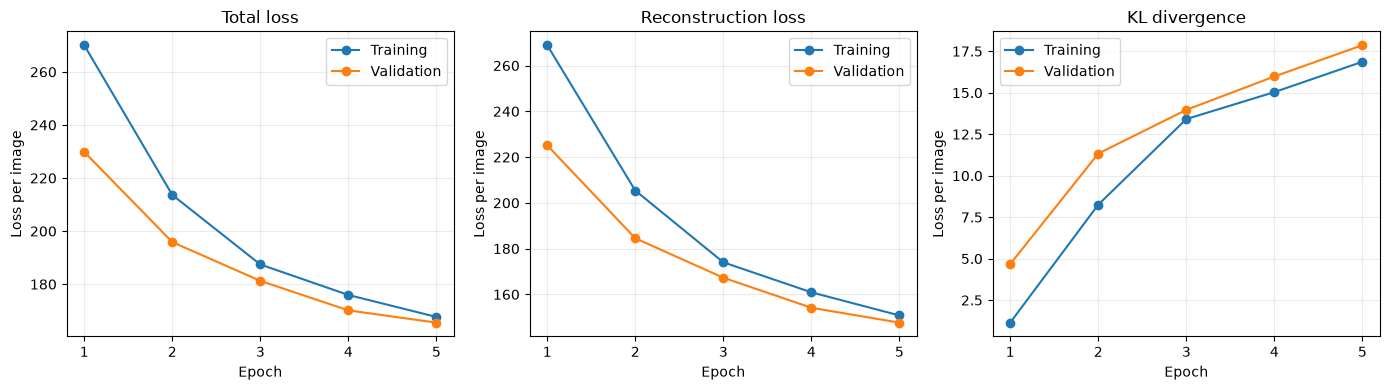

In [15]:
history_df = pd.DataFrame(pilot_history)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, metric, title in zip(
    axes,
    ["total", "reconstruction", "kl"],
    ["Total loss", "Reconstruction loss", "KL divergence"]
):
    for prefix, label in [
        ("train", "Training"),
        ("validation", "Validation")
    ]:
        ax.plot(
            history_df["epoch"],
            history_df[f"{prefix}_{metric}"],
            marker="o",
            label=label
        )

    ax.set(title=title, xlabel="Epoch", ylabel="Loss per image")
    ax.set_xticks(history_df["epoch"])
    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()
fig.savefig(
    pilot_run_dir / "figures" / "training_curves.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## 8. Extended apple baseline: 20 total epochs

Continue from the five-epoch pilot using the same architecture, optimizer settings, and data splits. Preserve the pilot results in their original run directory and save continuation results separately.

Use the same fixed validation inputs and prior latent vectors to compare reconstruction quality and generated sketches across training stages. The test set remains unused during model development.

In [16]:
import copy

# Check that the completed pilot is still available in this kernel.
assert len(pilot_history) == 5, "Expected the completed five-epoch pilot."
assert pilot_history[-1]["epoch"] == 5

TOTAL_EPOCHS = 20

# Copy the trained model and Adam state so the pilot objects remain intact.
extended_vae = copy.deepcopy(vae)
extended_optimizer = torch.optim.Adam(extended_vae.parameters(), lr=LEARNING_RATE)
extended_optimizer.load_state_dict(copy.deepcopy(optimizer.state_dict()))

# Retain epochs 1–5 so the extended history covers the complete experiment.
extended_history = copy.deepcopy(pilot_history)
extended_best_validation = min(
    row["validation_total"] for row in extended_history
)

run_id = datetime.now(timezone.utc).strftime("apple_vae_extended_%Y%m%dT%H%M%S_%fZ")
extended_run_dir = PROJECT_ROOT / "runs" / run_id

for folder in ["figures", "reports", "checkpoints"]:
    (extended_run_dir / folder).mkdir(parents=True, exist_ok=False)

extended_config = {
    **pilot_config,
    "epochs": TOTAL_EPOCHS,
    "continued_from_run": pilot_run_dir.name,
    "continued_from_epoch": 5
}

(extended_run_dir / "reports" / "config.json").write_text(json.dumps(extended_config, indent=2), encoding="utf-8")

apple_manifest.to_csv(extended_run_dir / "reports" / "split_manifest.csv", index=False)

# Reuse the exact display inputs without drawing new random samples.
torch.save(
    {
        "validation_images": fixed_validation.cpu(),
        "prior_latent": fixed_latent.cpu()
    },
    extended_run_dir / "checkpoints" / "fixed_display_inputs.pt"
)

pd.DataFrame(extended_history).to_csv(extended_run_dir / "reports" / "training_history.csv", index=False)

print("Run directory:", extended_run_dir)
print("Completed epochs:", extended_history[-1]["epoch"])
print("Additional epochs:", TOTAL_EPOCHS - extended_history[-1]["epoch"])
print("Prepared trained model and optimizer; no new updates performed.")

Run directory: /Users/ashlabs/Projects/Masters in AI/github/sketch-generation-vae/runs/apple_vae_extended_20261109T191530_728371Z
Completed epochs: 5
Additional epochs: 15
Prepared trained model and optimizer; no new updates performed.


Epoch 6/20 | Train: 163.18 | Validation: 161.27 | Reconstruction: 142.94 | KL: 18.32 | Time: 1.8s
Epoch 7/20 | Train: 160.28 | Validation: 158.99 | Reconstruction: 140.10 | KL: 18.89 | Time: 1.7s
Epoch 8/20 | Train: 158.33 | Validation: 157.24 | Reconstruction: 138.34 | KL: 18.90 | Time: 1.7s
Epoch 9/20 | Train: 156.86 | Validation: 156.39 | Reconstruction: 136.80 | KL: 19.59 | Time: 1.7s
Epoch 10/20 | Train: 155.83 | Validation: 155.69 | Reconstruction: 136.54 | KL: 19.15 | Time: 1.7s


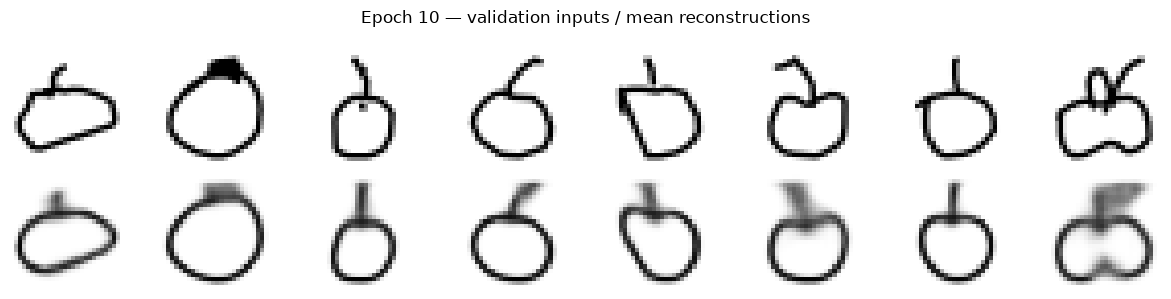

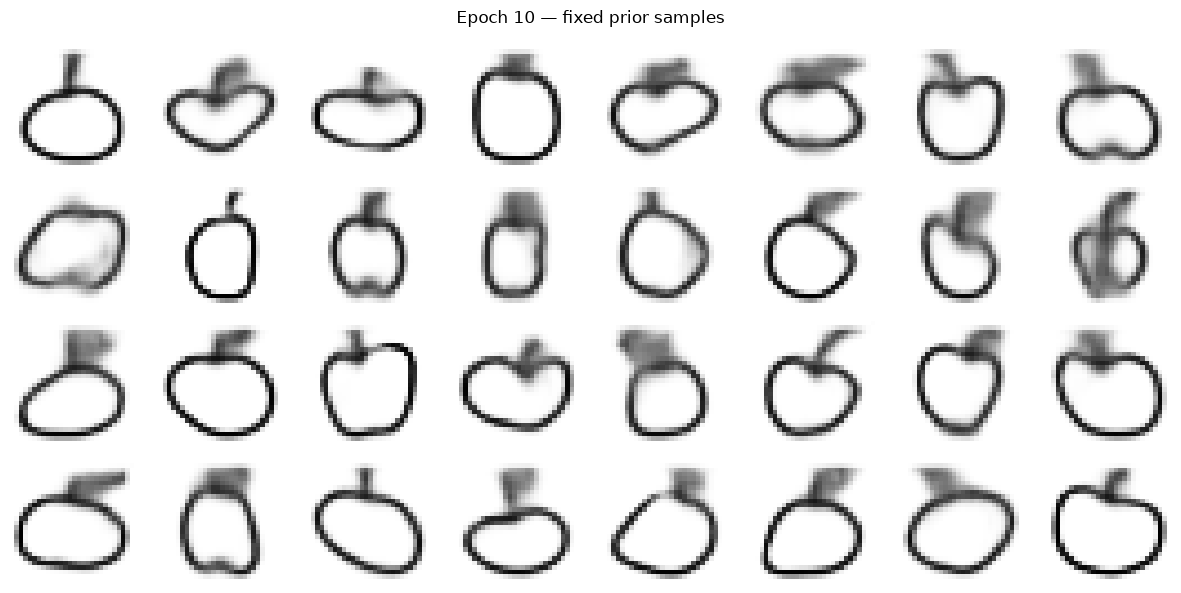

Epoch 11/20 | Train: 154.99 | Validation: 154.56 | Reconstruction: 134.96 | KL: 19.59 | Time: 1.7s
Epoch 12/20 | Train: 154.24 | Validation: 154.89 | Reconstruction: 135.49 | KL: 19.40 | Time: 1.7s
Epoch 13/20 | Train: 153.61 | Validation: 154.01 | Reconstruction: 134.51 | KL: 19.50 | Time: 1.7s
Epoch 14/20 | Train: 153.27 | Validation: 153.23 | Reconstruction: 133.68 | KL: 19.55 | Time: 1.7s
Epoch 15/20 | Train: 152.60 | Validation: 152.74 | Reconstruction: 132.84 | KL: 19.90 | Time: 1.7s


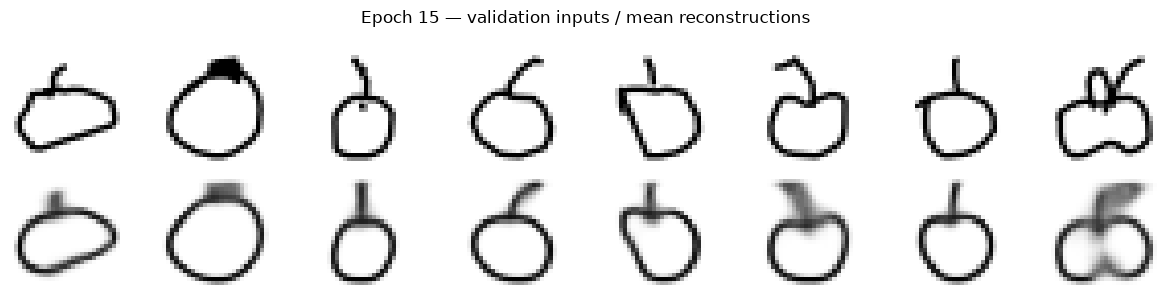

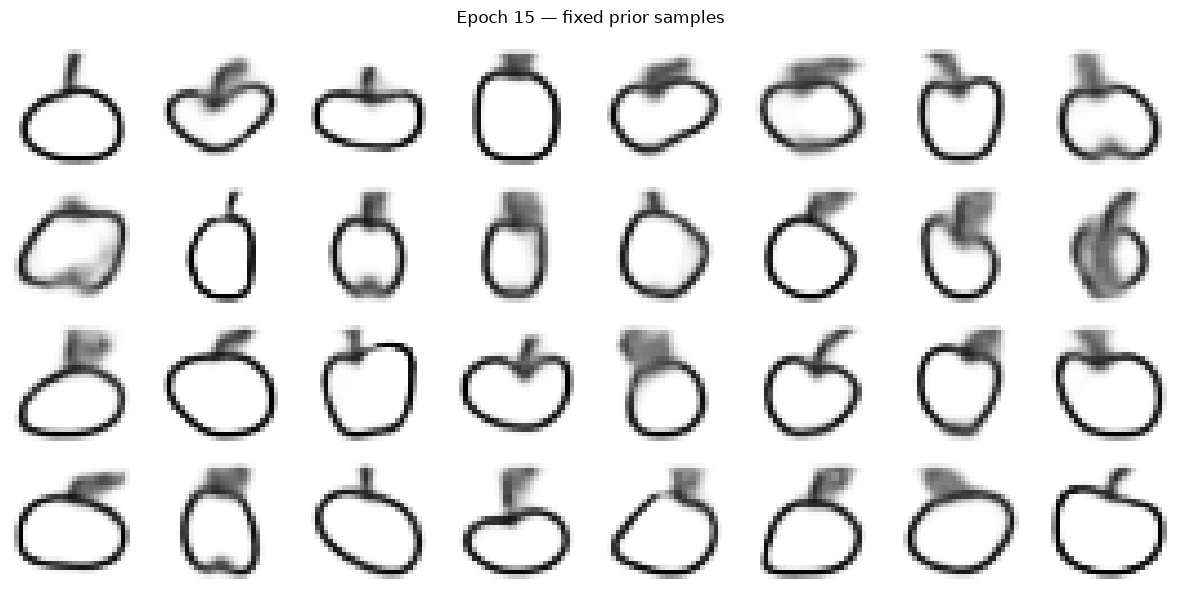

Epoch 16/20 | Train: 152.13 | Validation: 152.29 | Reconstruction: 131.83 | KL: 20.46 | Time: 1.7s
Epoch 17/20 | Train: 151.58 | Validation: 152.20 | Reconstruction: 131.90 | KL: 20.30 | Time: 1.7s
Epoch 18/20 | Train: 151.29 | Validation: 151.86 | Reconstruction: 131.12 | KL: 20.74 | Time: 1.7s
Epoch 19/20 | Train: 150.69 | Validation: 151.35 | Reconstruction: 130.44 | KL: 20.92 | Time: 1.7s
Epoch 20/20 | Train: 150.40 | Validation: 150.95 | Reconstruction: 130.00 | KL: 20.95 | Time: 1.7s


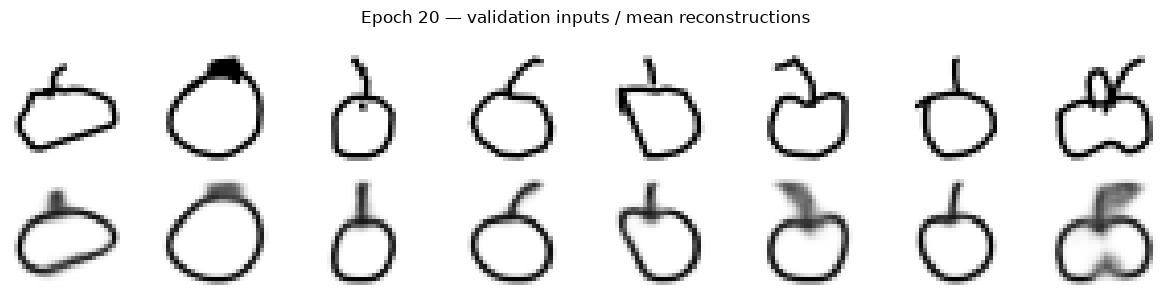

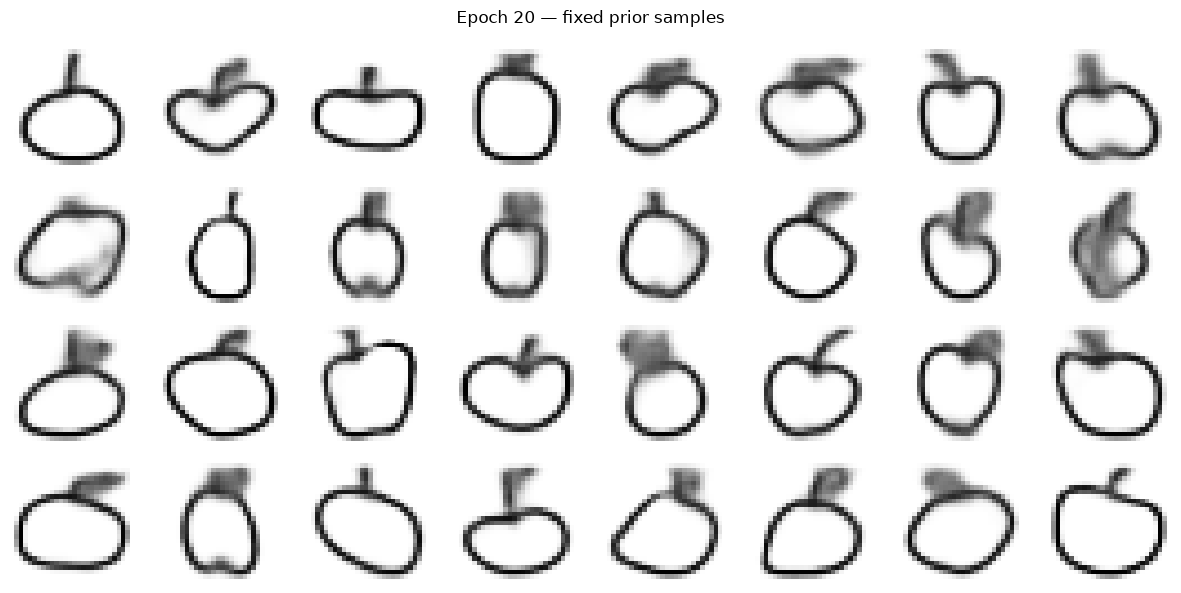

In [17]:
from time import perf_counter

latest_path = extended_run_dir / "checkpoints" / "latest.pt"
best_path = extended_run_dir / "checkpoints" / "best.pt"

# Prevent accidentally repeating updates by rerunning this cell.
if latest_path.exists() or extended_history[-1]["epoch"] != 5:
    raise RuntimeError(
        "Continuation has already started. Resume from a checkpoint "
        "instead of rerunning this cell."
    )

# Track the best checkpoint among the additional epochs.
best_continuation_validation = float("inf")

for epoch in range(6, TOTAL_EPOCHS + 1):
    started = perf_counter()

    train_metrics = train_vae_epoch(extended_vae, train_loader, extended_optimizer, device)
    validation_metrics = evaluate_vae(extended_vae, validation_loader, device)

    # Wait for GPU work before recording elapsed time.
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()

    row = {
        "epoch": epoch,
        "seconds": perf_counter() - started,
        "train_total": train_metrics["total"],
        "train_reconstruction": train_metrics["reconstruction"],
        "train_kl": train_metrics["kl"],
        "validation_total": validation_metrics["total"],
        "validation_reconstruction": validation_metrics["reconstruction"],
        "validation_kl": validation_metrics["kl"]
    }
    extended_history.append(row)

    improved = row["validation_total"] < best_continuation_validation
    if improved:
        best_continuation_validation = row["validation_total"]

    # Save model, optimizer, history, and random states for later resumption.
    checkpoint = {
        "epoch": epoch,
        "model": extended_vae.state_dict(),
        "optimizer": extended_optimizer.state_dict(),
        "config": extended_config,
        "history": extended_history,
        "best_validation": best_continuation_validation,
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "loader_rng": train_loader.generator.get_state()
    }

    if device.type == "mps":
        checkpoint["mps_rng"] = torch.mps.get_rng_state()
    elif device.type == "cuda":
        checkpoint["cuda_rng"] = torch.cuda.get_rng_state_all()

    # Replace the checkpoint only after writing finishes successfully.
    temporary_path = latest_path.with_suffix(".pt.partial")
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(latest_path)

    if improved:
        shutil.copy2(latest_path, best_path)

    pd.DataFrame(extended_history).to_csv(extended_run_dir / "reports" / "training_history.csv", index=False)

    print(
        f"Epoch {epoch}/{TOTAL_EPOCHS} | "
        f"Train: {row['train_total']:.2f} | "
        f"Validation: {row['validation_total']:.2f} | "
        f"Reconstruction: {row['validation_reconstruction']:.2f} | "
        f"KL: {row['validation_kl']:.2f} | "
        f"Time: {row['seconds']:.1f}s"
    )

    if epoch % 5 == 0:
        extended_vae.eval()
        with torch.no_grad():
            # Posterior means make reconstruction comparisons deterministic.
            reconstruction_logits, _, _ = extended_vae(fixed_validation, sample=False)
            reconstructions = reconstruction_logits.sigmoid().cpu()
            generations = extended_vae.decode(fixed_latent).sigmoid().cpu()

        fig, axes = plt.subplots(2, 8, figsize=(12, 3))
        for index in range(8):
            axes[0, index].imshow(
                fixed_validation[index, 0].cpu(),
                cmap="gray_r",
                vmin=0,
                vmax=1
            )
            axes[1, index].imshow(
                reconstructions[index, 0],
                cmap="gray_r", vmin=0, vmax=1
            )
            axes[0, index].axis("off")
            axes[1, index].axis("off")

        fig.suptitle(f"Epoch {epoch} — validation inputs / mean reconstructions")
        fig.tight_layout()
        fig.savefig(
            extended_run_dir / "figures" / f"reconstructions_{epoch:02d}.png",
            dpi=120,
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

        fig, axes = plt.subplots(4, 8, figsize=(12, 6))
        for ax, image in zip(axes.flat, generations):
            ax.imshow(
                image[0],
                cmap="gray_r",
                vmin=0,
                vmax=1,
                interpolation="nearest"
            )
            ax.axis("off")

        fig.suptitle(f"Epoch {epoch} — fixed prior samples")
        fig.tight_layout()
        fig.savefig(
            extended_run_dir / "figures" / f"generations_{epoch:02d}.png",
            dpi=120,
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

## 9. Multi-category dataset preparation

Extend the dataset to three Quick, Draw! categories: apple, mushroom, and umbrella. These categories provide distinct visual structures for
evaluating category-controlled generation.

Reuse the existing apple split. Audit the additional categories for blank images and exact duplicates before selecting 24,000 training, 3,000 validation, and 3,000 test images per category. Check exact duplicate overlap across categories and splits before training.

The conditional VAE will receive a category label alongside each image during training and alongside a sampled latent vector during generation.

In [18]:
CATEGORIES = ("apple", "mushroom", "umbrella")
CATEGORY_TO_ID = {
    category: index for index, category in enumerate(CATEGORIES)
}

category_images = {}
category_source_records = []

for category in CATEGORIES:
    url = (
        "https://storage.googleapis.com/"
        f"quickdraw_dataset/full/numpy_bitmap/{category}.npy"
    )
    path = PROJECT_ROOT / "data" / "raw" / f"{category}.npy"

    if not path.is_file():
        temporary_path = path.with_suffix(".npy.partial")

        # Publish the local file only after the download finishes.
        with urlopen(url, timeout=60) as response:
            expected_size = response.headers.get("Content-Length")
            with temporary_path.open("wb") as output:
                shutil.copyfileobj(response, output)

        if (
            expected_size is not None
            and temporary_path.stat().st_size != int(expected_size)
        ):
            raise RuntimeError(f"Incomplete download: {category}")

        temporary_path.replace(path)

    # Memory mapping avoids loading every category fully into RAM.
    images = np.load(path, mmap_mode="r", allow_pickle=False)
    assert images.ndim == 2 and images.shape[1] == 784
    assert images.dtype == np.uint8

    digest = hashlib.sha256()
    with path.open("rb") as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b""):
            digest.update(chunk)

    category_images[category] = images
    category_source_records.append({
        "category": category,
        "category_id": CATEGORY_TO_ID[category],
        "url": url,
        "license": "CC BY 4.0",
        "sha256": digest.hexdigest(),
        "bytes": path.stat().st_size,
        "shape": list(images.shape),
        "dtype": str(images.dtype),
        "verified_at_utc": datetime.now(timezone.utc).isoformat()
    })

    print(
        f"{category}: {len(images):,} images | "
        f"{path.stat().st_size / 1024**2:.1f} MiB"
    )

# Confirm that the apple file matches the baseline's recorded source.
apple_source = next(
    record for record in category_source_records
    if record["category"] == "apple"
)
assert apple_source["sha256"] == pilot_config["source_sha256"]

source_report_path = PROJECT_ROOT / "reports" / "multicategory_sources.json"
source_report_path.write_text(
    json.dumps(category_source_records, indent=2),
    encoding="utf-8"
)

print("Category mapping:", CATEGORY_TO_ID)

apple: 144,722 images | 108.2 MiB
mushroom: 142,167 images | 106.3 MiB
umbrella: 124,084 images | 92.8 MiB
Category mapping: {'apple': 0, 'mushroom': 1, 'umbrella': 2}


In [19]:
# Process apple first so its existing split takes priority.
seen_hashes = set()
manifest_parts = []
audit_records = []

for category in CATEGORIES:
    images = category_images[category]
    unique_rows = []
    blank_count = 0
    duplicate_count = 0

    for source_index, pixels in enumerate(images):
        if not np.any(pixels):
            blank_count += 1
            continue

        pixel_hash = hashlib.sha256(pixels.tobytes()).hexdigest()

        # One shared set prevents exact duplicates across categories too.
        if pixel_hash in seen_hashes:
            duplicate_count += 1
            continue

        seen_hashes.add(pixel_hash)
        unique_rows.append({
            "source_index": source_index,
            "category": category,
            "pixel_sha256": pixel_hash
        })

    inventory = pd.DataFrame(unique_rows)

    if category == "apple":
        # Preserve the baseline's exact image selection and split assignments.
        selected = apple_manifest.copy()

        indexed_hashes = inventory.set_index("source_index")["pixel_sha256"]
        expected_hashes = selected["source_index"].map(indexed_hashes)
        assert expected_hashes.notna().all()
        assert expected_hashes.eq(selected["pixel_sha256"]).all()
    else:
        assert len(inventory) >= 30_000, (
            f"Not enough unique, nonblank images for {category}."
        )

        # Separate deterministic sampling for each additional category.
        rng = np.random.default_rng(SEED + CATEGORY_TO_ID[category])
        positions = rng.choice(
            len(inventory), size=30_000, replace=False
        )
        selected = inventory.iloc[positions].copy().reset_index(drop=True)

        selected["split"] = (
            ["train"] * 24_000
            + ["validation"] * 3_000
            + ["test"] * 3_000
        )

    selected["category_id"] = CATEGORY_TO_ID[category]
    manifest_parts.append(selected)

    audit_records.append({
        "category": category,
        "source_images": len(images),
        "blank_images_excluded": blank_count,
        "exact_duplicates_excluded": duplicate_count,
        "eligible_unique_images": len(inventory),
        "selected_images": len(selected)
    })

    print(
        f"{category}: {blank_count:,} blank | "
        f"{duplicate_count:,} duplicates | "
        f"{len(inventory):,} eligible"
    )

multicategory_manifest = pd.concat(manifest_parts, ignore_index=True)

# Verify uniqueness across the entire selected dataset, including splits.
assert multicategory_manifest["pixel_sha256"].is_unique
assert not multicategory_manifest.duplicated(
    ["category", "source_index"]
).any()

split_counts = pd.crosstab(
    multicategory_manifest["category"],
    multicategory_manifest["split"]
).reindex(index=CATEGORIES, columns=["train", "validation", "test"])

assert (split_counts["train"] == 24_000).all()
assert (split_counts["validation"] == 3_000).all()
assert (split_counts["test"] == 3_000).all()

multicategory_manifest.to_csv(
    PROJECT_ROOT / "data" / "processed" / "multicategory_split_manifest.csv",
    index=False
)

audit_report = {
    "seed": SEED,
    "category_mapping": CATEGORY_TO_ID,
    "apple_split_preserved": True,
    "duplicate_policy": (
        "First occurrence retained in category order: "
        "apple, mushroom, umbrella. All eligible source hashes are "
        "reserved before sampling the next category."
    ),
    "categories": audit_records
}

(PROJECT_ROOT / "reports" / "multicategory_data_audit.json").write_text(
    json.dumps(audit_report, indent=2),
    encoding="utf-8"
)

display(split_counts)
print("Selected images:", len(multicategory_manifest))
print("Exact pixel-hash overlap across selected splits: 0")

apple: 0 blank | 1 duplicates | 144,721 eligible
mushroom: 0 blank | 3 duplicates | 142,164 eligible
umbrella: 0 blank | 3 duplicates | 124,081 eligible


split,train,validation,test
category,,,
apple,24000,3000,3000
mushroom,24000,3000,3000
umbrella,24000,3000,3000


Selected images: 90000
Exact pixel-hash overlap across selected splits: 0


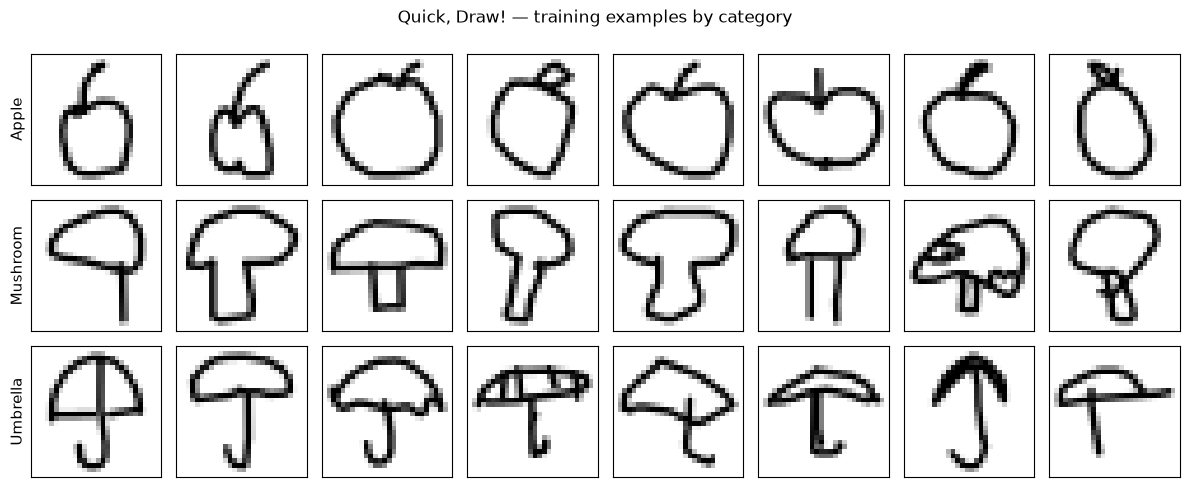

In [20]:
fig, axes = plt.subplots(3, 8, figsize=(12, 5))

for row, category in enumerate(CATEGORIES):
    # Preview training images only; keep the test set untouched.
    candidates = multicategory_manifest.loc[
        (multicategory_manifest["category"] == category)
        & (multicategory_manifest["split"] == "train")
    ]

    rng = np.random.default_rng(SEED + CATEGORY_TO_ID[category])
    positions = rng.choice(len(candidates), size=8, replace=False)
    selected = candidates.iloc[positions]

    for column, source_index in enumerate(selected["source_index"]):
        ax = axes[row, column]
        ax.imshow(
            category_images[category][int(source_index)].reshape(28, 28),
            cmap="gray_r",
            vmin=0,
            vmax=255,
            interpolation="nearest",
        )
        ax.set_xticks([])
        ax.set_yticks([])

        if column == 0:
            ax.set_ylabel(category.capitalize(), fontsize=11)

fig.suptitle("Quick, Draw! — training examples by category")
fig.tight_layout()
fig.savefig(
    PROJECT_ROOT / "figures" / "multicategory_training_examples.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

## 10. Labeled image loading

Each example contains a grayscale image with shape (1, 28, 28) and an integer category label: apple = 0, mushroom = 1, umbrella = 2.

Pixel values are scaled to [0, 1], using the same preprocessing as the apple baseline. Training examples are shuffled across categories. Validation uses a fixed order and no random augmentation. The test partition remains reserved for final evaluation.

In [21]:
from torch.utils.data import Dataset, DataLoader


class ConditionalSketchDataset(Dataset):
    """Load sketch images and category labels from a split manifest.

    Parameters
    ----------
    images_by_category : dict
        Mapping from category names to arrays of flattened uint8 images.
    manifest : pandas.DataFrame
        Selected records containing category, source_index, and category_id.
    """

    def __init__(self, images_by_category, manifest):
        self.images_by_category = images_by_category
        self.categories = manifest["category"].to_numpy(copy=True)
        self.source_indices = manifest["source_index"].to_numpy(
            dtype=np.int64, copy=True
        )
        self.category_ids = manifest["category_id"].to_numpy(
            dtype=np.int64, copy=True
        )

    def __len__(self):
        """Return the number of selected images."""
        return len(self.source_indices)

    def __getitem__(self, index):
        """Return one normalized image and its category ID.

        Parameters
        ----------
        index : int
            Position within this dataset.

        Returns
        -------
        tuple[torch.Tensor, int]
            Float32 image with shape (1, 28, 28) and integer category ID.
        """
        category = self.categories[index]
        source_index = int(self.source_indices[index])

        # Copy the memory-mapped row before converting it to a tensor.
        pixels = np.array(
            self.images_by_category[category][source_index],
            dtype=np.float32,
            copy=True,
        ).reshape(1, 28, 28)
        pixels /= 255.0

        return torch.from_numpy(pixels), int(self.category_ids[index])


conditional_train_dataset = ConditionalSketchDataset(
    category_images,
    multicategory_manifest.loc[
        multicategory_manifest["split"] == "train"
    ],
)

conditional_validation_dataset = ConditionalSketchDataset(
    category_images,
    multicategory_manifest.loc[
        multicategory_manifest["split"] == "validation"
    ],
)

conditional_shuffle_generator = torch.Generator().manual_seed(SEED)

conditional_train_loader = DataLoader(
    conditional_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=conditional_shuffle_generator,
)

conditional_validation_loader = DataLoader(
    conditional_validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED + 1),
)

# Inspect examples from every category without advancing the training loader.
preview_images = []
preview_labels = []

for category in CATEGORIES:
    records = multicategory_manifest.loc[
        (multicategory_manifest["category"] == category)
        & (multicategory_manifest["split"] == "train")
    ].head(2)

    preview_dataset = ConditionalSketchDataset(category_images, records)
    for index in range(len(preview_dataset)):
        image, label = preview_dataset[index]
        preview_images.append(image)
        preview_labels.append(label)

conditional_example_images = torch.stack(preview_images)
conditional_example_labels = torch.tensor(
    preview_labels, dtype=torch.long
)

assert conditional_example_images.shape == (6, 1, 28, 28)
assert torch.isfinite(conditional_example_images).all()
assert 0 <= conditional_example_images.min().item()
assert conditional_example_images.max().item() <= 1
assert set(conditional_example_labels.tolist()) == {0, 1, 2}

print("Training images:", len(conditional_train_dataset))
print("Validation images:", len(conditional_validation_dataset))
print("Training batches per epoch:", len(conditional_train_loader))
print("Example image shape:", tuple(conditional_example_images.shape))
print("Example labels:", conditional_example_labels.tolist())
print("Label dtype:", conditional_example_labels.dtype)

Training images: 72000
Validation images: 9000
Training batches per epoch: 563
Example image shape: (6, 1, 28, 28)
Example labels: [0, 0, 1, 1, 2, 2]
Label dtype: torch.int64


## 11. Conditional VAE architecture

The encoder combines image features with a one-hot category label to estimate the latent mean and log variance. The decoder combines a latent vector with the same category label to produce reconstruction logits.

The latent representation has 16 dimensions. Category labels are represented separately, allowing generation to specify apple, mushroom, or umbrella while sampling variation from a standard normal prior.

The convolution widths and upsampling approach follow the apple baseline. The model is trained from scratch. Supplying labels makes category control possible; whether the model follows them must be evaluated after training.

In [22]:
from torch import nn
from torch.nn import functional as F


class ConditionalSketchVAE(nn.Module):
    """Convolutional VAE conditioned on sketch category.

    Parameters
    ----------
    latent_dim : int
        Number of latent dimensions.
    num_categories : int
        Number of supported category labels.
    """

    def __init__(self, latent_dim=16, num_categories=3):
        super().__init__()
        self.latent_dim = latent_dim
        self.num_categories = num_categories

        self.encoder_features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten()
        )

        # Append the category after extracting spatial image features.
        self.encoder_hidden = nn.Sequential(
            nn.Linear(64 * 7 * 7 + num_categories, 128),
            nn.ReLU()
        )
        self.mean_head = nn.Linear(128, latent_dim)
        self.log_variance_head = nn.Linear(128, latent_dim)

        self.decoder_input = nn.Sequential(
            nn.Linear(latent_dim + num_categories, 128),
            nn.ReLU(),
            nn.Linear(128, 64 * 7 * 7),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (64, 7, 7)),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(32, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            # Return logits for numerically stable BCE loss.
            nn.Conv2d(16, 1, kernel_size=3, padding=1)
        )

    def encode(self, images, labels):
        """Estimate the conditional posterior parameters.

        Parameters
        ----------
        images : torch.Tensor
            Images with shape (batch, 1, 28, 28).
        labels : torch.Tensor
            Int64 category IDs with shape (batch,), on the image device.

        Returns
        -------
        tuple[torch.Tensor, torch.Tensor]
            Mean and log variance, each with shape (batch, latent_dim).
        """
        features = self.encoder_features(images)
        category_vectors = F.one_hot(labels, num_classes=self.num_categories).to(dtype=features.dtype)

        hidden = self.encoder_hidden(torch.cat([features, category_vectors], dim=1))
        return self.mean_head(hidden), self.log_variance_head(hidden)

    def reparameterize(self, mean, log_variance):
        """Sample a latent vector while preserving gradient flow.

        Parameters
        ----------
        mean : torch.Tensor
            Posterior means with shape (batch, latent_dim).
        log_variance : torch.Tensor
            Posterior log variances with the same shape.

        Returns
        -------
        torch.Tensor
            Sampled latent vectors with shape (batch, latent_dim).
        """
        standard_deviation = torch.exp(0.5 * log_variance)
        return mean + standard_deviation * torch.randn_like(mean)

    def decode(self, latent, labels):
        """Decode latent vectors for the requested categories.

        Parameters
        ----------
        latent : torch.Tensor
            Latent vectors with shape (batch, latent_dim).
        labels : torch.Tensor
            Int64 category IDs with shape (batch,), on the latent device.

        Returns
        -------
        torch.Tensor
            Pixel logits with shape (batch, 1, 28, 28).
        """
        category_vectors = F.one_hot(labels, num_classes=self.num_categories).to(dtype=latent.dtype)

        hidden = self.decoder_input(torch.cat([latent, category_vectors], dim=1))
        return self.decoder(hidden)

    def forward(self, images, labels, sample=True):
        """Reconstruct images using their category labels.

        Parameters
        ----------
        images : torch.Tensor
            Images with shape (batch, 1, 28, 28).
        labels : torch.Tensor
            Int64 category IDs with shape (batch,).
        sample : bool
            Sample the posterior when True; otherwise use its mean.

        Returns
        -------
        tuple[torch.Tensor, torch.Tensor, torch.Tensor]
            Reconstruction logits, posterior means, and log variances.
        """
        mean, log_variance = self.encode(images, labels)
        latent = (
            self.reparameterize(mean, log_variance)
            if sample else mean
        )
        return self.decode(latent, labels), mean, log_variance


torch.manual_seed(SEED)
conditional_vae = ConditionalSketchVAE(latent_dim=LATENT_DIM, num_categories=len(CATEGORIES)).to(device)

conditional_vae.eval()
with torch.no_grad():
    logits, mean, log_variance = conditional_vae(
        conditional_example_images.to(device),
        conditional_example_labels.to(device),
        sample=False
    )

assert logits.shape == conditional_example_images.shape
assert mean.shape == (6, LATENT_DIM)
assert log_variance.shape == mean.shape
assert all(
    torch.isfinite(value).all().item()
    for value in (logits, mean, log_variance)
)

print(
    "Parameters:",
    f"{sum(p.numel() for p in conditional_vae.parameters()):,}"
)
print("Reconstruction logits:", tuple(logits.shape))
print("Posterior mean:", tuple(mean.shape))
print("Posterior log variance:", tuple(log_variance.shape))
print("Architecture shape checks passed.")

Parameters: 855,201
Reconstruction logits: (6, 1, 28, 28)
Posterior mean: (6, 16)
Posterior log variance: (6, 16)
Architecture shape checks passed.


In [23]:
def run_conditional_epoch(model, loader, device, optimizer=None):
    """Train or evaluate the conditional VAE for one epoch.

    Parameters
    ----------
    model : ConditionalSketchVAE
        Model to train or evaluate.
    loader : torch.utils.data.DataLoader
        Loader yielding image batches and integer category labels.
    device : torch.device
        Device used for model computation.
    optimizer : torch.optim.Optimizer or None
        Update model parameters when provided. Otherwise evaluate without
        gradients using reproducible posterior noise.

    Returns
    -------
    dict
        Image-averaged total, reconstruction, and KL losses, plus a
        per_category dictionary containing the same metrics and counts.
    """
    training = optimizer is not None
    model.train(training)

    # Each row accumulates total, reconstruction, and KL loss for one class.
    sums = np.zeros((model.num_categories, 3), dtype=np.float64)
    counts = np.zeros(model.num_categories, dtype=np.int64)

    # Evaluation noise is repeatable and does not advance training's RNG.
    noise_generator = torch.Generator().manual_seed(12345)

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)
                logits, mean, log_variance = model(
                    images, labels, sample=True
                )
            else:
                mean, log_variance = model.encode(images, labels)
                noise = torch.randn(
                    mean.shape,
                    generator=noise_generator,
                    dtype=mean.dtype,
                ).to(device)
                latent = mean + torch.exp(0.5 * log_variance) * noise
                logits = model.decode(latent, labels)

            # Sum over pixels or latent dimensions, retaining each image's loss.
            reconstruction = F.binary_cross_entropy_with_logits(
                logits, images, reduction="none"
            ).flatten(1).sum(1)

            kl = -0.5 * (
                1 + log_variance - mean.square() - log_variance.exp()
            ).sum(1)

            total = reconstruction + kl
            losses = torch.stack([total, reconstruction, kl], dim=1)

            if not torch.isfinite(losses).all().item():
                raise RuntimeError("Encountered a nonfinite conditional VAE loss.")

            if training:
                total.mean().backward()
                optimizer.step()

            # Detach logging values so they retain no computation graph.
            batch_losses = losses.detach().cpu().numpy()
            batch_labels = labels.detach().cpu().numpy()

            for category_id in range(model.num_categories):
                mask = batch_labels == category_id
                sums[category_id] += batch_losses[mask].sum(axis=0)
                counts[category_id] += int(mask.sum())

    if counts.sum() == 0:
        raise ValueError("The data loader yielded no images.")

    metric_names = ("total", "reconstruction", "kl")
    overall = sums.sum(axis=0) / counts.sum()
    result = dict(zip(metric_names, overall.tolist()))
    result["per_category"] = {}

    for category, category_id in CATEGORY_TO_ID.items():
        if counts[category_id] > 0:
            averages = sums[category_id] / counts[category_id]
            result["per_category"][category] = {
                **dict(zip(metric_names, averages.tolist())),
                "count": int(counts[category_id]),
            }

    return result


# Verify that the conditional objective produces finite gradients.
# No optimizer step is taken, so model weights remain unchanged.
conditional_vae.train()
conditional_vae.zero_grad(set_to_none=True)

check_images = conditional_example_images.to(device)
check_labels = conditional_example_labels.to(device)

check_logits, check_mean, check_log_variance = conditional_vae(
    check_images, check_labels
)
check_total, check_reconstruction, check_kl = vae_loss(
    check_logits, check_images, check_mean, check_log_variance
)
check_total.backward()

assert all(
    parameter.grad is not None
    and torch.isfinite(parameter.grad).all().item()
    for parameter in conditional_vae.parameters()
    if parameter.requires_grad
)

conditional_vae.zero_grad(set_to_none=True)

print(f"Diagnostic total loss: {check_total.item():.2f}")
print(f"Reconstruction: {check_reconstruction.item():.2f}")
print(f"KL: {check_kl.item():.2f}")
print("Finite gradients verified; no training updates performed.")

Diagnostic total loss: 531.29
Reconstruction: 531.25
KL: 0.05
Finite gradients verified; no training updates performed.


In [24]:
CONDITIONAL_EPOCHS = 20
CONDITIONAL_LEARNING_RATE = 0.001

# Reset initialization and training shuffle for a reproducible fresh run.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
conditional_shuffle_generator.manual_seed(SEED)

conditional_vae = ConditionalSketchVAE(
    latent_dim=LATENT_DIM,
    num_categories=len(CATEGORIES),
).to(device)

conditional_optimizer = torch.optim.Adam(
    conditional_vae.parameters(),
    lr=CONDITIONAL_LEARNING_RATE,
)

run_id = datetime.now(timezone.utc).strftime(
    "conditional_vae_%Y%m%dT%H%M%S_%fZ"
)
conditional_run_dir = PROJECT_ROOT / "runs" / run_id

for folder in ["figures", "reports", "checkpoints"]:
    (conditional_run_dir / folder).mkdir(parents=True, exist_ok=False)

conditional_config = {
    "model": "conditional_convolutional_vae",
    "categories": list(CATEGORIES),
    "category_mapping": CATEGORY_TO_ID,
    "latent_dim": LATENT_DIM,
    "batch_size": BATCH_SIZE,
    "learning_rate": CONDITIONAL_LEARNING_RATE,
    "epochs": CONDITIONAL_EPOCHS,
    "kl_weight": 1.0,
    "seed": SEED,
    "validation_noise_seed": 12345,
    "source_sha256": {
        record["category"]: record["sha256"]
        for record in category_source_records
    },
}

(conditional_run_dir / "reports" / "config.json").write_text(
    json.dumps(conditional_config, indent=2),
    encoding="utf-8",
)
multicategory_manifest.to_csv(
    conditional_run_dir / "reports" / "split_manifest.csv",
    index=False,
)

# Select eight validation examples per category in manifest order.
fixed_images = []
fixed_labels = []
fixed_records = []

for category in CATEGORIES:
    records = multicategory_manifest.loc[
        (multicategory_manifest["category"] == category)
        & (multicategory_manifest["split"] == "validation")
    ].head(8)

    preview_dataset = ConditionalSketchDataset(category_images, records)
    for index in range(len(preview_dataset)):
        image, label = preview_dataset[index]
        fixed_images.append(image)
        fixed_labels.append(label)

    fixed_records.append(records)

conditional_fixed_images = torch.stack(fixed_images).to(device)
conditional_fixed_labels = torch.tensor(
    fixed_labels, dtype=torch.long, device=device
)

# Repeat the same eight latent vectors for every category.
# This makes the effect of changing the category label easier to inspect.
prior_generator = torch.Generator().manual_seed(SEED + 1)
shared_latent = torch.randn(
    8, LATENT_DIM, generator=prior_generator
)
conditional_fixed_latent = shared_latent.repeat(
    len(CATEGORIES), 1
).to(device)

torch.save(
    {
        "validation_images": conditional_fixed_images.cpu(),
        "validation_labels": conditional_fixed_labels.cpu(),
        "prior_latent": conditional_fixed_latent.cpu(),
        "prior_labels": conditional_fixed_labels.cpu(),
    },
    conditional_run_dir / "checkpoints" / "fixed_display_inputs.pt",
)

pd.concat(fixed_records, ignore_index=True).to_csv(
    conditional_run_dir / "reports" / "fixed_validation_samples.csv",
    index=False,
)

conditional_history = []
conditional_category_history = []
conditional_best_validation = float("inf")

print("Run directory:", conditional_run_dir)
print("Epochs:", CONDITIONAL_EPOCHS)
print("Fixed validation images:", tuple(conditional_fixed_images.shape))
print("Fixed prior latent vectors:", tuple(conditional_fixed_latent.shape))
print("Prepared fresh model and optimizer; no training updates performed.")

Run directory: /Users/ashlabs/Projects/Masters in AI/github/sketch-generation-vae/runs/conditional_vae_20261109T200212_282317Z
Epochs: 20
Fixed validation images: (24, 1, 28, 28)
Fixed prior latent vectors: (24, 16)
Prepared fresh model and optimizer; no training updates performed.


Epoch 01/20 | Train: 240.50 | Validation: 193.12 | Reconstruction: 175.00 | KL: 18.13 | Time: 5.4s


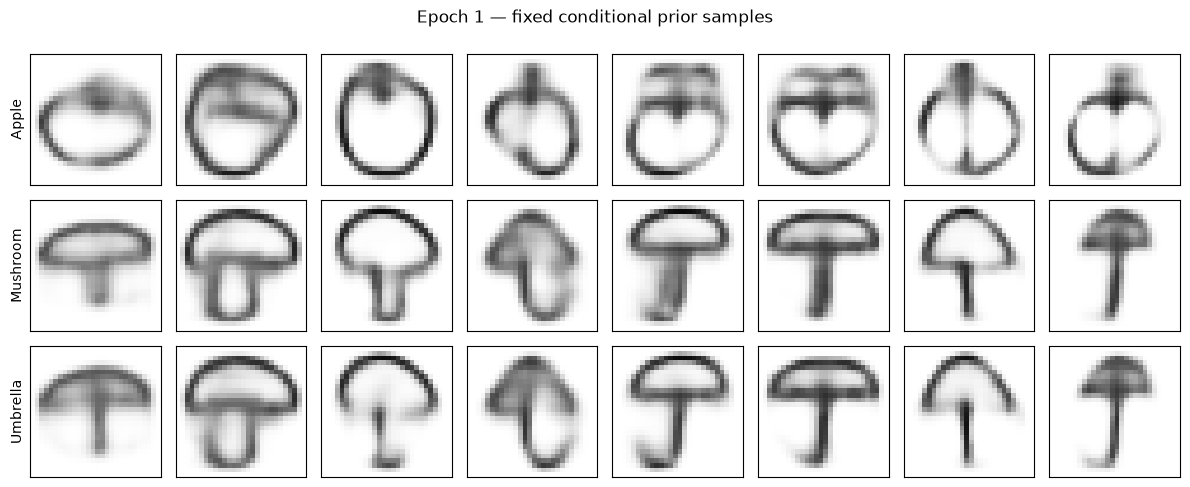

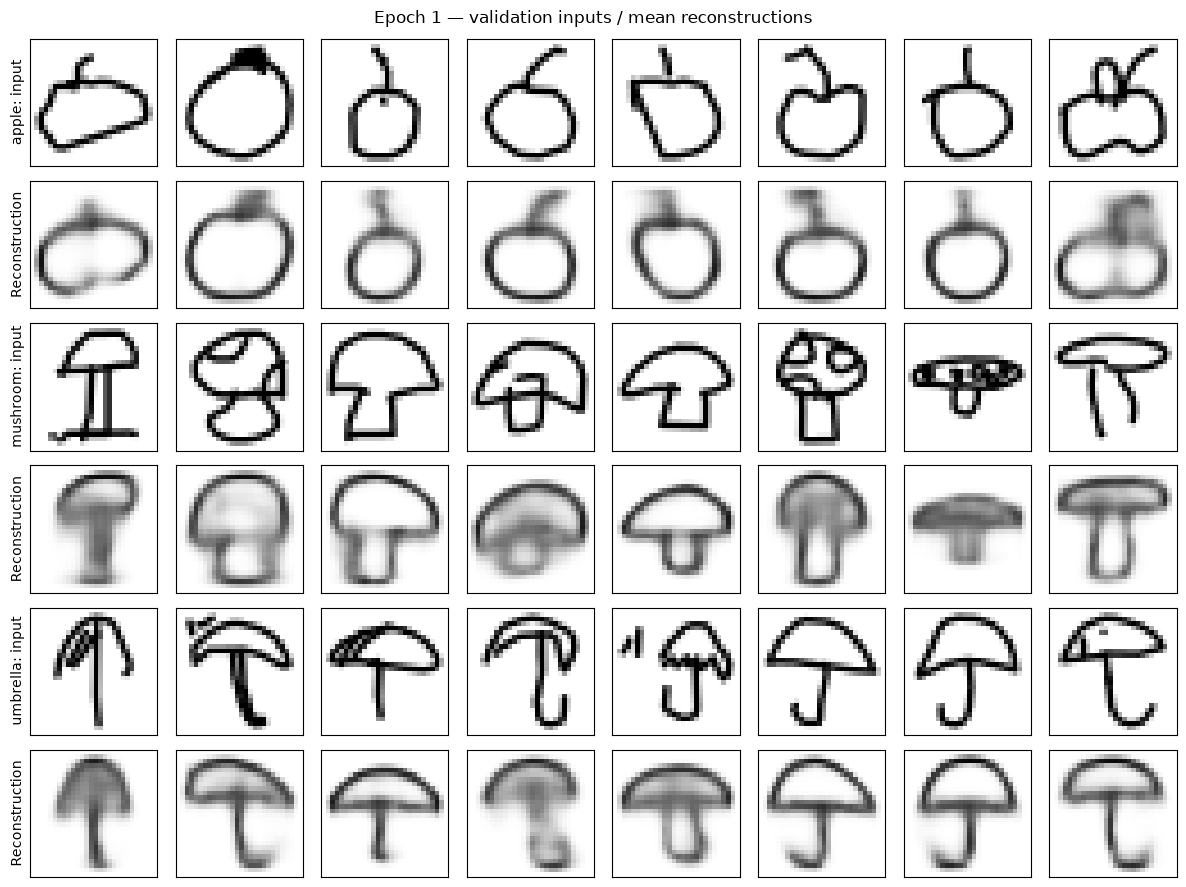

Epoch 02/20 | Train: 183.72 | Validation: 177.84 | Reconstruction: 158.40 | KL: 19.44 | Time: 5.1s
Epoch 03/20 | Train: 174.08 | Validation: 172.58 | Reconstruction: 152.12 | KL: 20.47 | Time: 5.0s
Epoch 04/20 | Train: 170.03 | Validation: 169.18 | Reconstruction: 148.05 | KL: 21.13 | Time: 5.0s
Epoch 05/20 | Train: 167.78 | Validation: 167.81 | Reconstruction: 146.42 | KL: 21.39 | Time: 5.0s


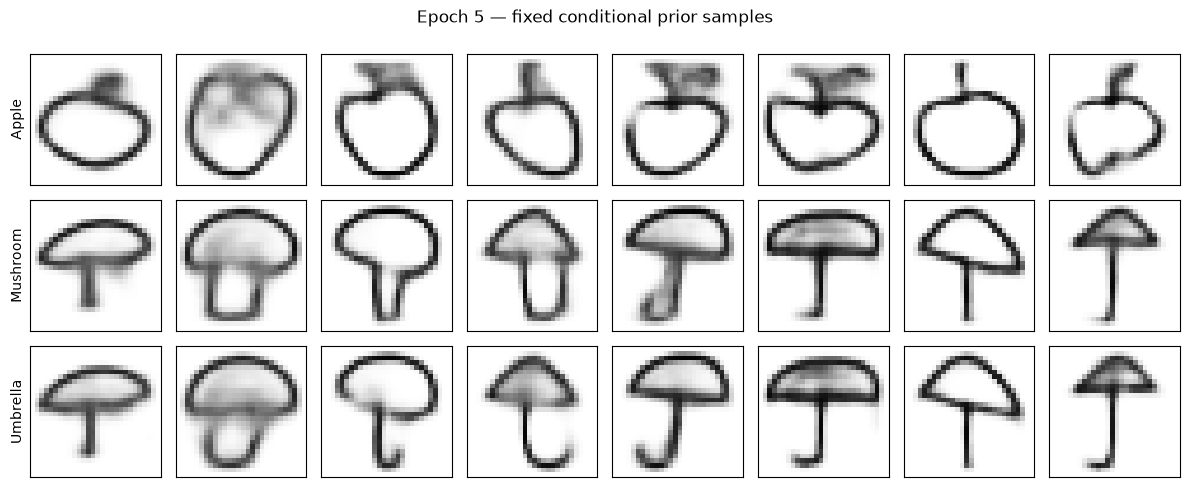

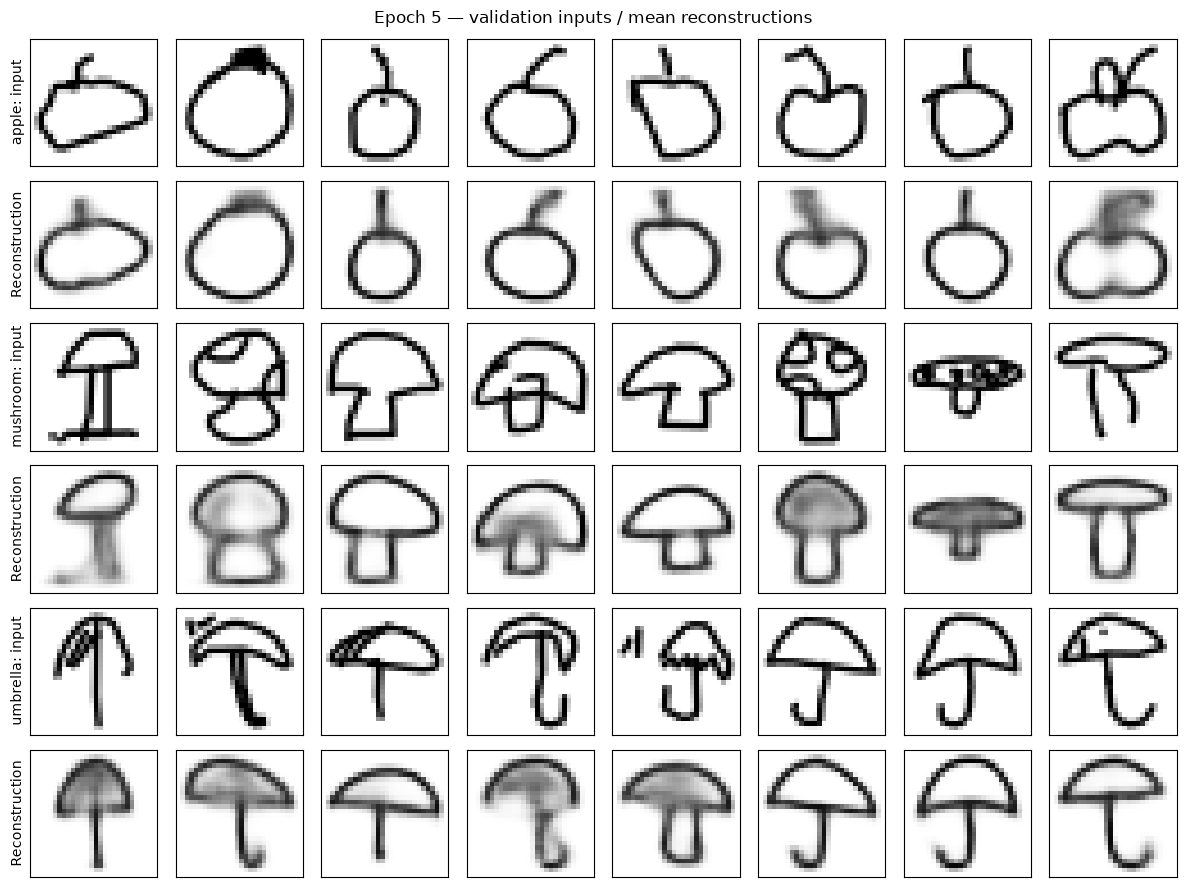

Epoch 06/20 | Train: 166.55 | Validation: 166.72 | Reconstruction: 144.62 | KL: 22.11 | Time: 5.0s
Epoch 07/20 | Train: 165.50 | Validation: 166.04 | Reconstruction: 144.31 | KL: 21.73 | Time: 5.0s
Epoch 08/20 | Train: 164.70 | Validation: 166.07 | Reconstruction: 143.78 | KL: 22.30 | Time: 5.0s
Epoch 09/20 | Train: 164.10 | Validation: 164.86 | Reconstruction: 142.88 | KL: 21.98 | Time: 5.0s
Epoch 10/20 | Train: 163.64 | Validation: 164.66 | Reconstruction: 142.26 | KL: 22.40 | Time: 5.0s


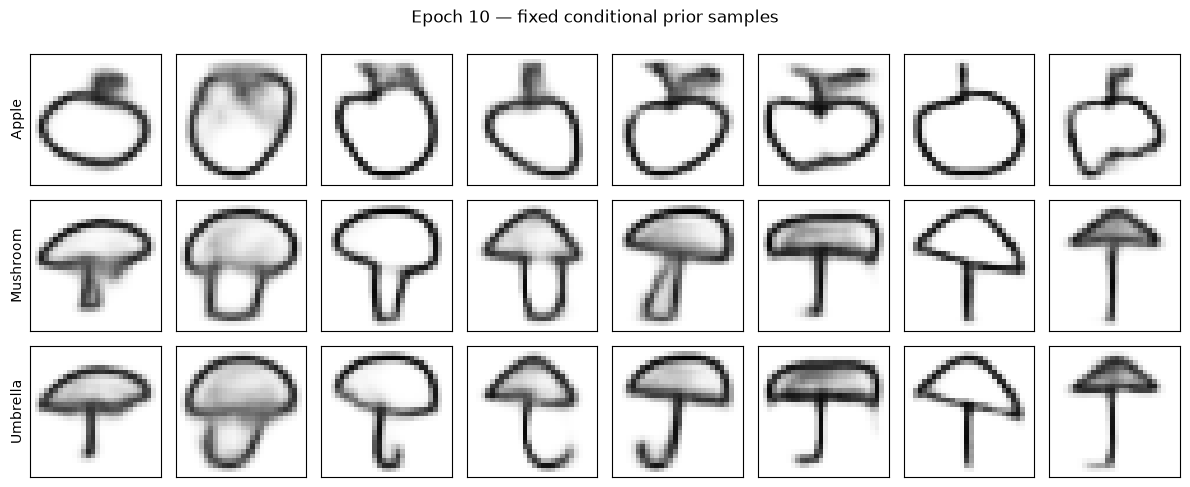

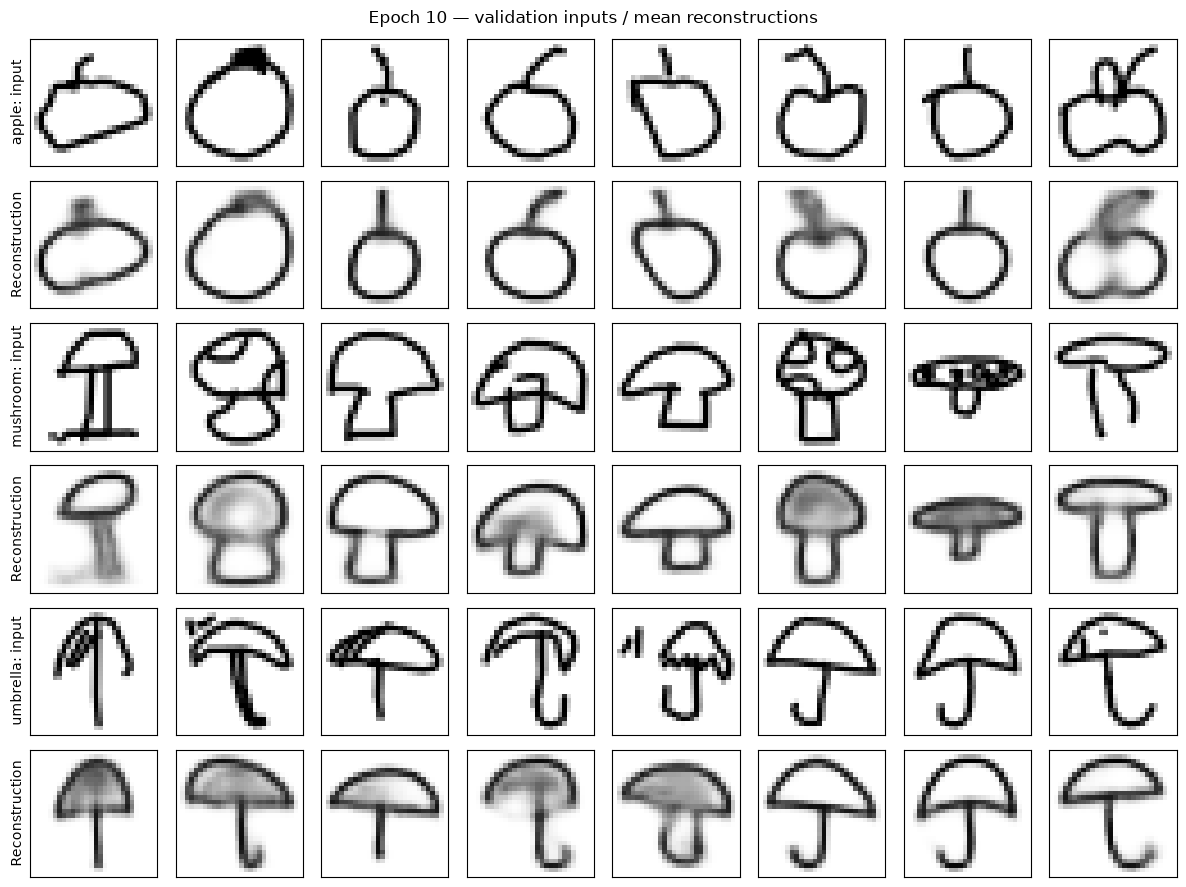

Epoch 11/20 | Train: 163.08 | Validation: 164.31 | Reconstruction: 141.99 | KL: 22.32 | Time: 5.0s
Epoch 12/20 | Train: 162.65 | Validation: 163.61 | Reconstruction: 141.59 | KL: 22.02 | Time: 5.0s
Epoch 13/20 | Train: 162.38 | Validation: 163.92 | Reconstruction: 141.99 | KL: 21.93 | Time: 5.0s
Epoch 14/20 | Train: 162.06 | Validation: 163.39 | Reconstruction: 141.13 | KL: 22.27 | Time: 5.0s
Epoch 15/20 | Train: 161.66 | Validation: 163.52 | Reconstruction: 141.36 | KL: 22.17 | Time: 5.0s


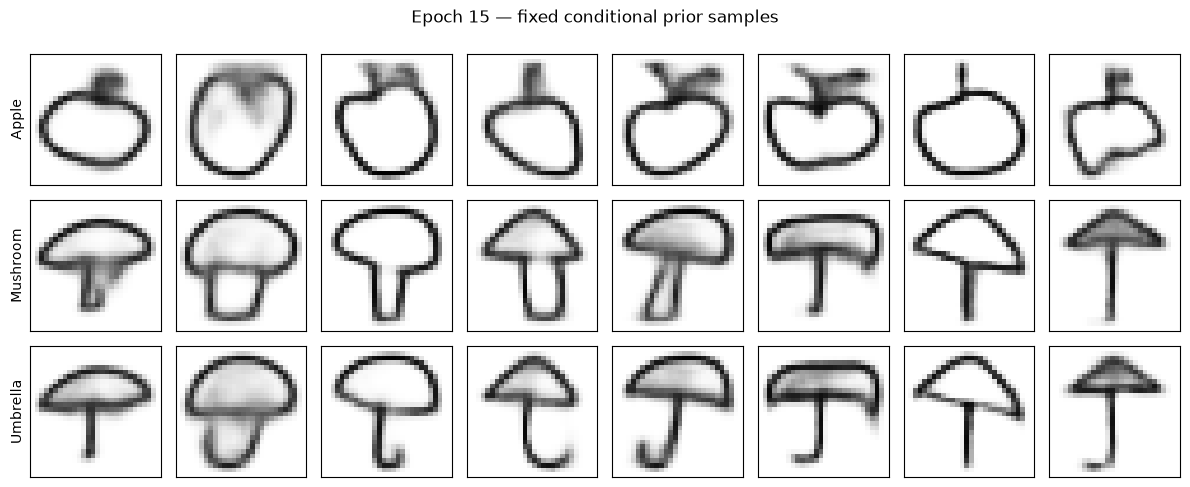

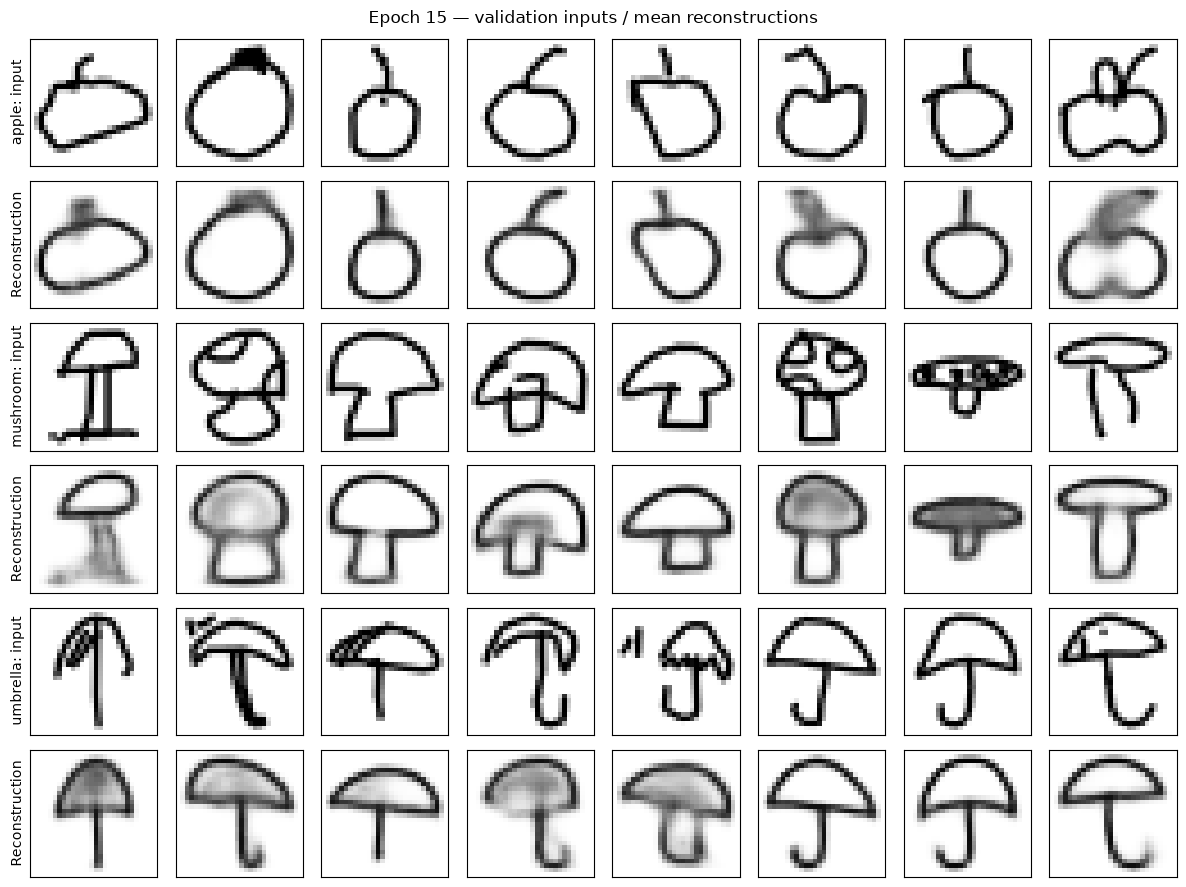

Epoch 16/20 | Train: 161.45 | Validation: 163.61 | Reconstruction: 141.90 | KL: 21.71 | Time: 5.0s
Epoch 17/20 | Train: 161.24 | Validation: 162.97 | Reconstruction: 140.49 | KL: 22.48 | Time: 5.0s
Epoch 18/20 | Train: 161.00 | Validation: 162.41 | Reconstruction: 140.12 | KL: 22.29 | Time: 5.0s
Epoch 19/20 | Train: 160.81 | Validation: 162.43 | Reconstruction: 140.02 | KL: 22.41 | Time: 5.0s
Epoch 20/20 | Train: 160.55 | Validation: 162.71 | Reconstruction: 140.63 | KL: 22.08 | Time: 5.0s


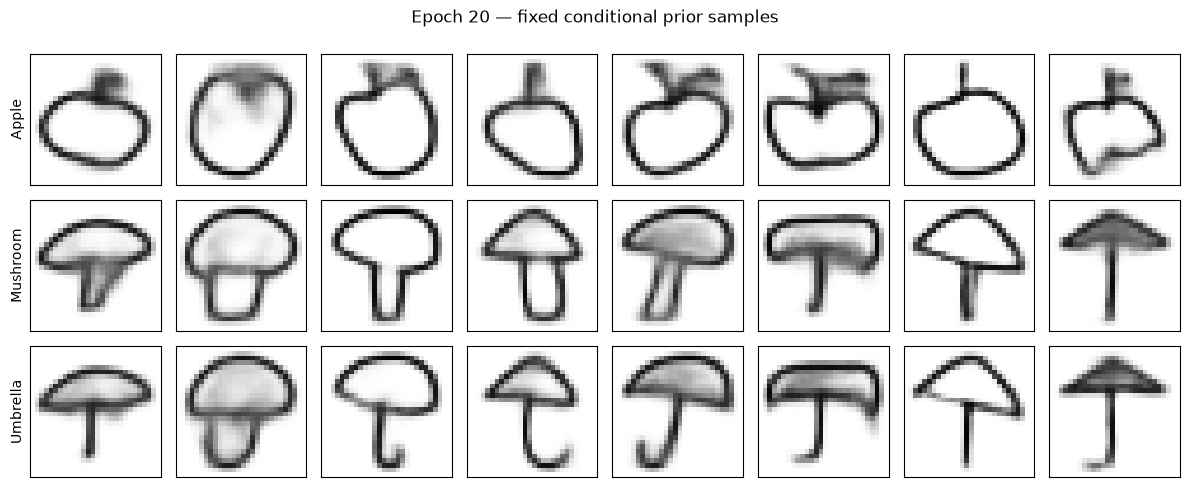

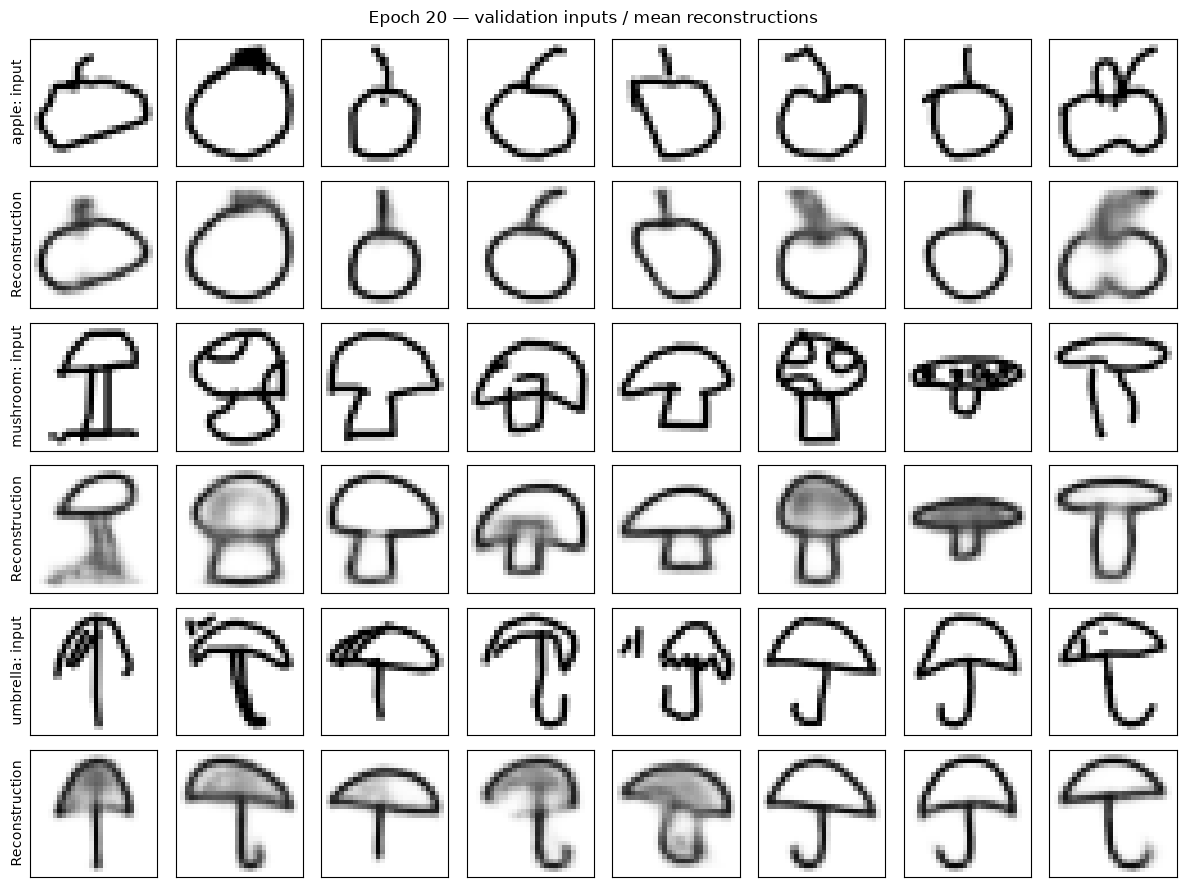

In [25]:
from time import perf_counter

conditional_latest_path = (
    conditional_run_dir / "checkpoints" / "latest.pt"
)
conditional_best_path = (
    conditional_run_dir / "checkpoints" / "best.pt"
)

if conditional_history or conditional_latest_path.exists():
    raise RuntimeError(
        "This run has already started. Resume from its checkpoint "
        "instead of rerunning this cell."
    )

for epoch in range(1, CONDITIONAL_EPOCHS + 1):
    started = perf_counter()

    train_metrics = run_conditional_epoch(
        conditional_vae,
        conditional_train_loader,
        device,
        optimizer=conditional_optimizer,
    )
    validation_metrics = run_conditional_epoch(
        conditional_vae,
        conditional_validation_loader,
        device,
    )

    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()

    row = {
        "epoch": epoch,
        "seconds": perf_counter() - started,
        **{
            f"train_{metric}": train_metrics[metric]
            for metric in ("total", "reconstruction", "kl")
        },
        **{
            f"validation_{metric}": validation_metrics[metric]
            for metric in ("total", "reconstruction", "kl")
        },
    }
    conditional_history.append(row)

    # Retain separate category results so an overall average cannot hide
    # weak performance on one category.
    for split, metrics in [
        ("train", train_metrics),
        ("validation", validation_metrics),
    ]:
        for category, values in metrics["per_category"].items():
            conditional_category_history.append({
                "epoch": epoch,
                "split": split,
                "category": category,
                **values,
            })

    improved = row["validation_total"] < conditional_best_validation
    if improved:
        conditional_best_validation = row["validation_total"]

    checkpoint = {
        "epoch": epoch,
        "model": conditional_vae.state_dict(),
        "optimizer": conditional_optimizer.state_dict(),
        "config": conditional_config,
        "history": conditional_history,
        "category_history": conditional_category_history,
        "best_validation": conditional_best_validation,
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "loader_rng": conditional_shuffle_generator.get_state(),
        "validation_loader_rng": (
            conditional_validation_loader.generator.get_state()
        ),
    }

    if device.type == "mps":
        checkpoint["mps_rng"] = torch.mps.get_rng_state()
    elif device.type == "cuda":
        checkpoint["cuda_rng"] = torch.cuda.get_rng_state_all()

    temporary_path = conditional_latest_path.with_suffix(".pt.partial")
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(conditional_latest_path)

    if improved:
        shutil.copy2(conditional_latest_path, conditional_best_path)

    pd.DataFrame(conditional_history).to_csv(
        conditional_run_dir / "reports" / "training_history.csv",
        index=False,
    )
    pd.DataFrame(conditional_category_history).to_csv(
        conditional_run_dir / "reports" / "category_history.csv",
        index=False,
    )

    print(
        f"Epoch {epoch:02d}/{CONDITIONAL_EPOCHS} | "
        f"Train: {row['train_total']:.2f} | "
        f"Validation: {row['validation_total']:.2f} | "
        f"Reconstruction: {row['validation_reconstruction']:.2f} | "
        f"KL: {row['validation_kl']:.2f} | "
        f"Time: {row['seconds']:.1f}s"
    )

    if epoch == 1 or epoch % 5 == 0:
        conditional_vae.eval()
        with torch.no_grad():
            logits, _, _ = conditional_vae(
                conditional_fixed_images,
                conditional_fixed_labels,
                sample=False,
            )
            reconstructions = logits.sigmoid().cpu()

            generations = conditional_vae.decode(
                conditional_fixed_latent,
                conditional_fixed_labels,
            ).sigmoid().cpu()

        # Each row changes the category; each column keeps the same latent.
        fig, axes = plt.subplots(
            len(CATEGORIES), 8, figsize=(12, 5)
        )
        for category_id, category in enumerate(CATEGORIES):
            for column in range(8):
                index = category_id * 8 + column
                ax = axes[category_id, column]
                ax.imshow(
                    generations[index, 0],
                    cmap="gray_r", vmin=0, vmax=1,
                    interpolation="nearest",
                )
                ax.set_xticks([])
                ax.set_yticks([])
                if column == 0:
                    ax.set_ylabel(category.capitalize())

        fig.suptitle(f"Epoch {epoch} — fixed conditional prior samples")
        fig.tight_layout()
        fig.savefig(
            conditional_run_dir / "figures"
            / f"generations_{epoch:02d}.png",
            dpi=150,
            bbox_inches="tight",
        )
        plt.show()
        plt.close(fig)

        # Two rows per category: validation inputs, then reconstructions.
        fig, axes = plt.subplots(
            2 * len(CATEGORIES), 8, figsize=(12, 9)
        )
        for category_id, category in enumerate(CATEGORIES):
            for column in range(8):
                index = category_id * 8 + column

                for offset, images, label in [
                    (0, conditional_fixed_images, f"{category}: input"),
                    (1, reconstructions, "Reconstruction"),
                ]:
                    ax = axes[2 * category_id + offset, column]
                    ax.imshow(
                        images[index, 0].cpu(),
                        cmap="gray_r", vmin=0, vmax=1,
                        interpolation="nearest",
                    )
                    ax.set_xticks([])
                    ax.set_yticks([])
                    if column == 0:
                        ax.set_ylabel(label)

        fig.suptitle(
            f"Epoch {epoch} — validation inputs / mean reconstructions"
        )
        fig.tight_layout()
        fig.savefig(
            conditional_run_dir / "figures"
            / f"reconstructions_{epoch:02d}.png",
            dpi=150,
            bbox_inches="tight",
        )
        plt.show()
        plt.close(fig)

In [26]:
history_df = pd.DataFrame(conditional_history)
category_history_df = pd.DataFrame(conditional_category_history)

best_row = history_df.loc[history_df["validation_total"].idxmin()]
best_epoch = int(best_row["epoch"])

print("Best validation epoch:", best_epoch)
print(f"Best validation total: {best_row['validation_total']:.2f}")

display(
    category_history_df.loc[
        (category_history_df["epoch"] == best_epoch)
        & (category_history_df["split"] == "validation"),
        ["category", "count", "total", "reconstruction", "kl"],
    ].round(2)
)

Best validation epoch: 18
Best validation total: 162.41


,category,count,total,reconstruction,kl
105,apple,3000,154.51,132.75,21.76
106,mushroom,3000,169.53,146.48,23.05
107,umbrella,3000,163.19,141.13,22.07


## 12. Experiment: increasing latent capacity

Compare the 16-dimensional conditional VAE with a fresh 32-dimensional model. Keep the data splits, convolution widths, batch size, learning rate, loss weights, and 20-epoch training budget unchanged.

The additional latent dimensions may help preserve drawing details, but may also increase the mismatch between encoded images and the standard normal generation prior. Evaluate validation losses alongside reconstructions and generated samples.

Use the same fixed validation images. For generation, retain the baseline's 16 latent coordinates and append 16 independently sampled coordinates. These inputs are reproducible, but matching coordinates does not imply matching visual styles between independently trained models.

In [27]:
CAPACITY_LATENT_DIM = 32
CAPACITY_EPOCHS = 20

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Give this experiment its own shuffle generator and loaders.
capacity_shuffle_generator = torch.Generator().manual_seed(SEED)

capacity_train_loader = DataLoader(
    conditional_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=capacity_shuffle_generator,
)
capacity_validation_loader = DataLoader(
    conditional_validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED + 1),
)

capacity_vae = ConditionalSketchVAE(
    latent_dim=CAPACITY_LATENT_DIM,
    num_categories=len(CATEGORIES),
).to(device)

capacity_optimizer = torch.optim.Adam(
    capacity_vae.parameters(),
    lr=CONDITIONAL_LEARNING_RATE,
)

run_id = datetime.now(timezone.utc).strftime(
    "conditional_vae_latent32_%Y%m%dT%H%M%S_%fZ"
)
capacity_run_dir = PROJECT_ROOT / "runs" / run_id

for folder in ["figures", "reports", "checkpoints"]:
    (capacity_run_dir / folder).mkdir(parents=True, exist_ok=False)

capacity_config = {
    **conditional_config,
    "latent_dim": CAPACITY_LATENT_DIM,
    "epochs": CAPACITY_EPOCHS,
    "comparison_run": conditional_run_dir.name,
    "experiment": "Increase latent dimensions from 16 to 32",
}

(capacity_run_dir / "reports" / "config.json").write_text(
    json.dumps(capacity_config, indent=2),
    encoding="utf-8",
)
multicategory_manifest.to_csv(
    capacity_run_dir / "reports" / "split_manifest.csv",
    index=False,
)

# Reuse the validation inputs and append reproducible prior coordinates.
extra_generator = torch.Generator().manual_seed(SEED + 2)
extra_latent = torch.randn(
    8,
    CAPACITY_LATENT_DIM - conditional_config["latent_dim"],
    generator=extra_generator,
)
capacity_shared_latent = torch.cat(
    [conditional_fixed_latent[:8].cpu(), extra_latent],
    dim=1,
)
capacity_fixed_latent = capacity_shared_latent.repeat(
    len(CATEGORIES), 1
).to(device)

torch.save(
    {
        "validation_images": conditional_fixed_images.cpu(),
        "validation_labels": conditional_fixed_labels.cpu(),
        "prior_latent": capacity_fixed_latent.cpu(),
        "prior_labels": conditional_fixed_labels.cpu(),
    },
    capacity_run_dir / "checkpoints" / "fixed_display_inputs.pt",
)
shutil.copy2(
    conditional_run_dir / "reports" / "fixed_validation_samples.csv",
    capacity_run_dir / "reports" / "fixed_validation_samples.csv",
)

capacity_history = []
capacity_category_history = []
capacity_best_validation = float("inf")

capacity_vae.eval()
with torch.no_grad():
    logits, mean, log_variance = capacity_vae(
        conditional_fixed_images[:6],
        conditional_fixed_labels[:6],
        sample=False,
    )

assert logits.shape == (6, 1, 28, 28)
assert mean.shape == log_variance.shape == (6, CAPACITY_LATENT_DIM)
assert all(
    torch.isfinite(value).all().item()
    for value in (logits, mean, log_variance)
)

print("Run directory:", capacity_run_dir)
print(
    "Parameters:",
    f"{sum(p.numel() for p in capacity_vae.parameters()):,}",
)
print("Posterior shape:", tuple(mean.shape))
print("Fixed prior shape:", tuple(capacity_fixed_latent.shape))
print("Prepared fresh model; no training updates performed.")

Run directory: /Users/ashlabs/Projects/Masters in AI/github/sketch-generation-vae/runs/conditional_vae_latent32_20261109T201733_952454Z
Parameters: 861,377
Posterior shape: (6, 32)
Fixed prior shape: (24, 32)
Prepared fresh model; no training updates performed.


Epoch 01/20 | Train: 261.97 | Validation: 223.49 | Reconstruction: 212.62 | KL: 10.87 | Time: 5.0s


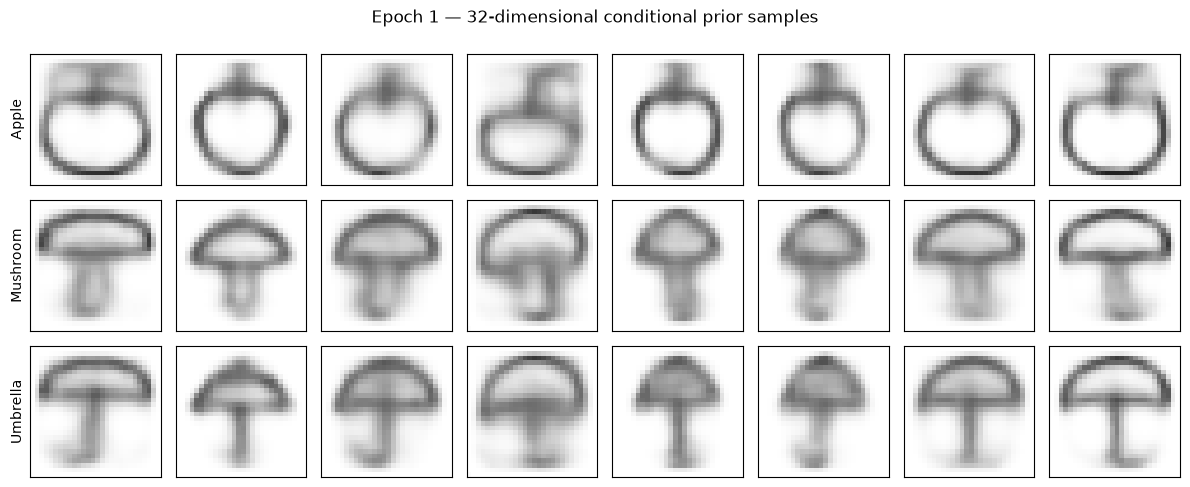

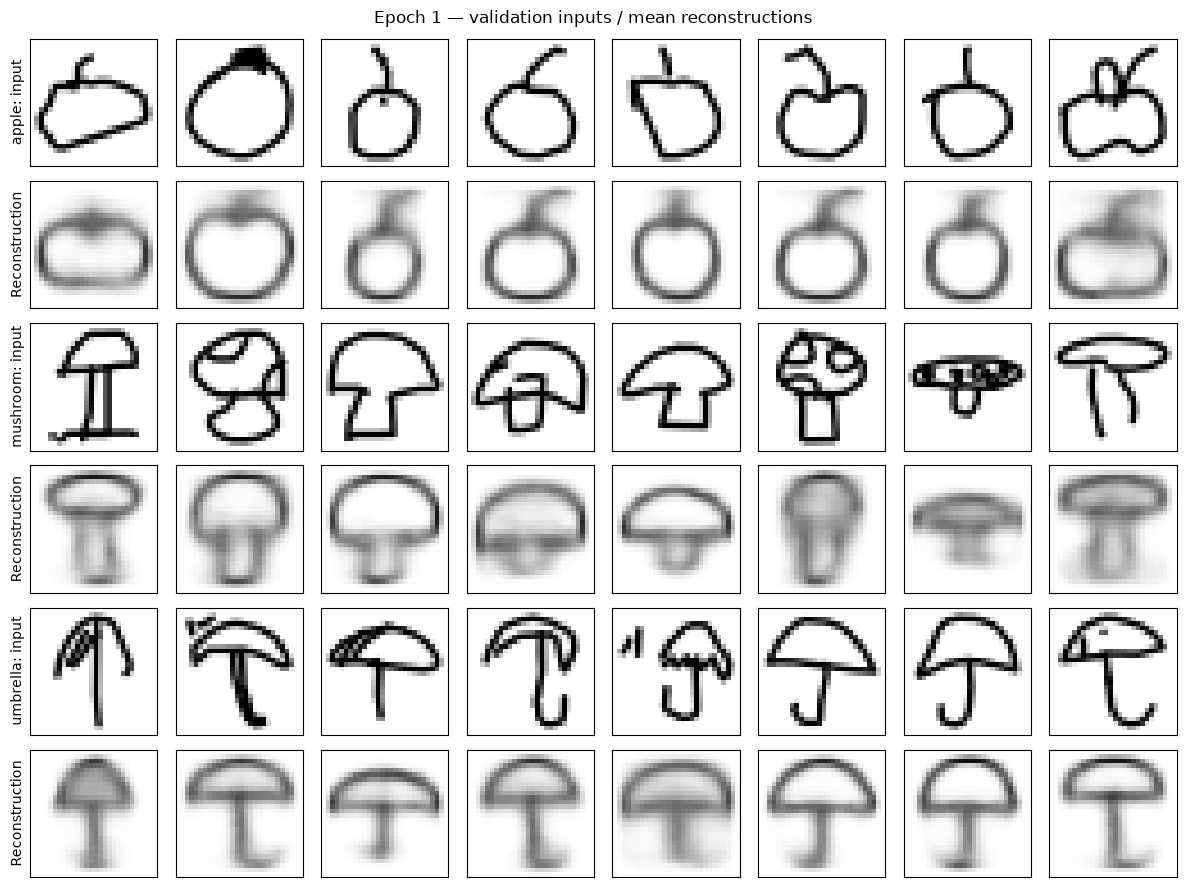

Epoch 02/20 | Train: 205.15 | Validation: 194.97 | Reconstruction: 179.55 | KL: 15.43 | Time: 5.0s
Epoch 03/20 | Train: 188.83 | Validation: 185.17 | Reconstruction: 169.04 | KL: 16.13 | Time: 4.9s
Epoch 04/20 | Train: 181.80 | Validation: 180.00 | Reconstruction: 163.27 | KL: 16.73 | Time: 5.0s
Epoch 05/20 | Train: 177.56 | Validation: 177.74 | Reconstruction: 160.67 | KL: 17.06 | Time: 5.0s


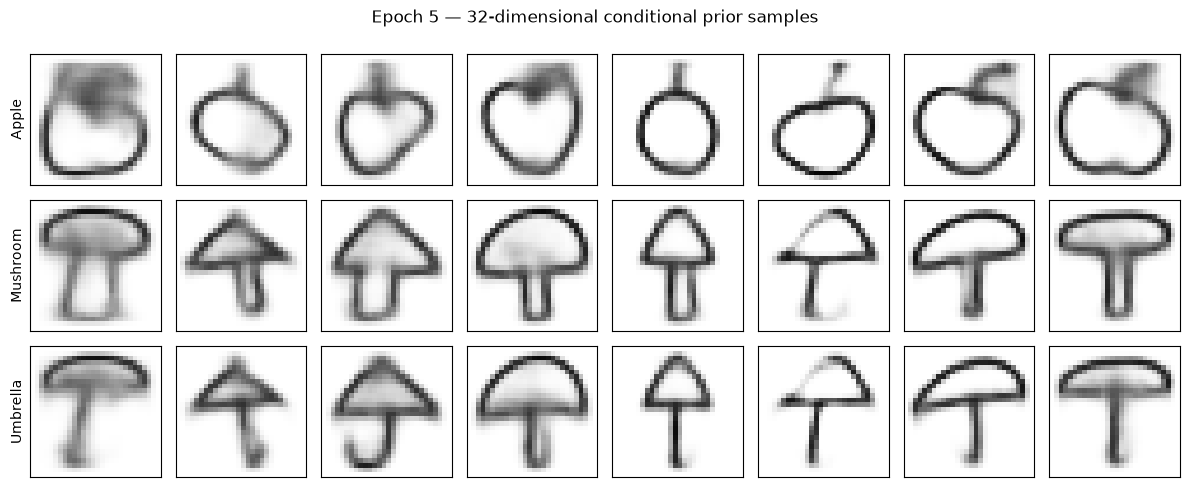

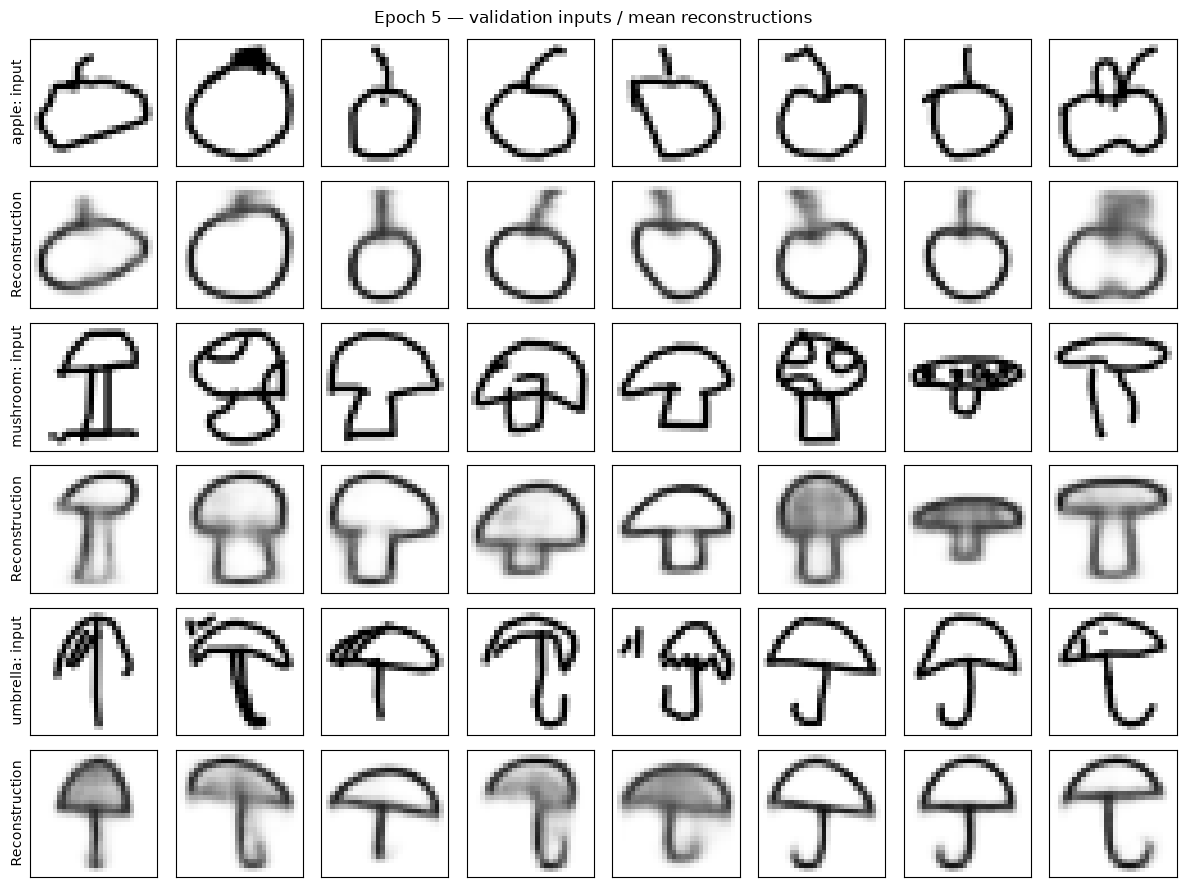

Epoch 06/20 | Train: 175.36 | Validation: 175.60 | Reconstruction: 157.59 | KL: 18.01 | Time: 5.0s
Epoch 07/20 | Train: 172.78 | Validation: 173.06 | Reconstruction: 154.72 | KL: 18.34 | Time: 5.0s
Epoch 08/20 | Train: 171.27 | Validation: 172.37 | Reconstruction: 153.65 | KL: 18.72 | Time: 5.0s
Epoch 09/20 | Train: 170.34 | Validation: 171.31 | Reconstruction: 152.53 | KL: 18.79 | Time: 5.0s
Epoch 10/20 | Train: 169.68 | Validation: 171.04 | Reconstruction: 151.83 | KL: 19.21 | Time: 5.0s


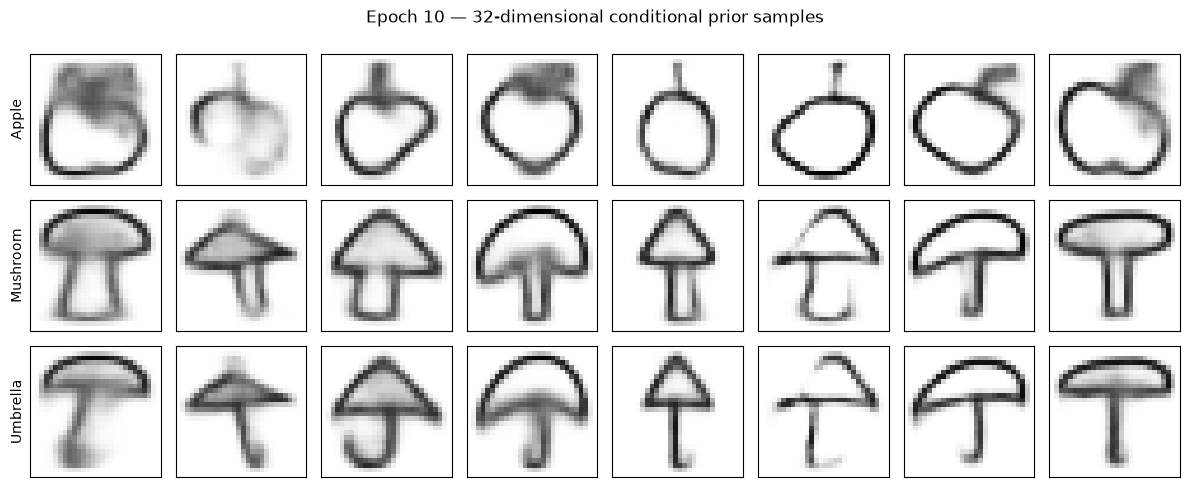

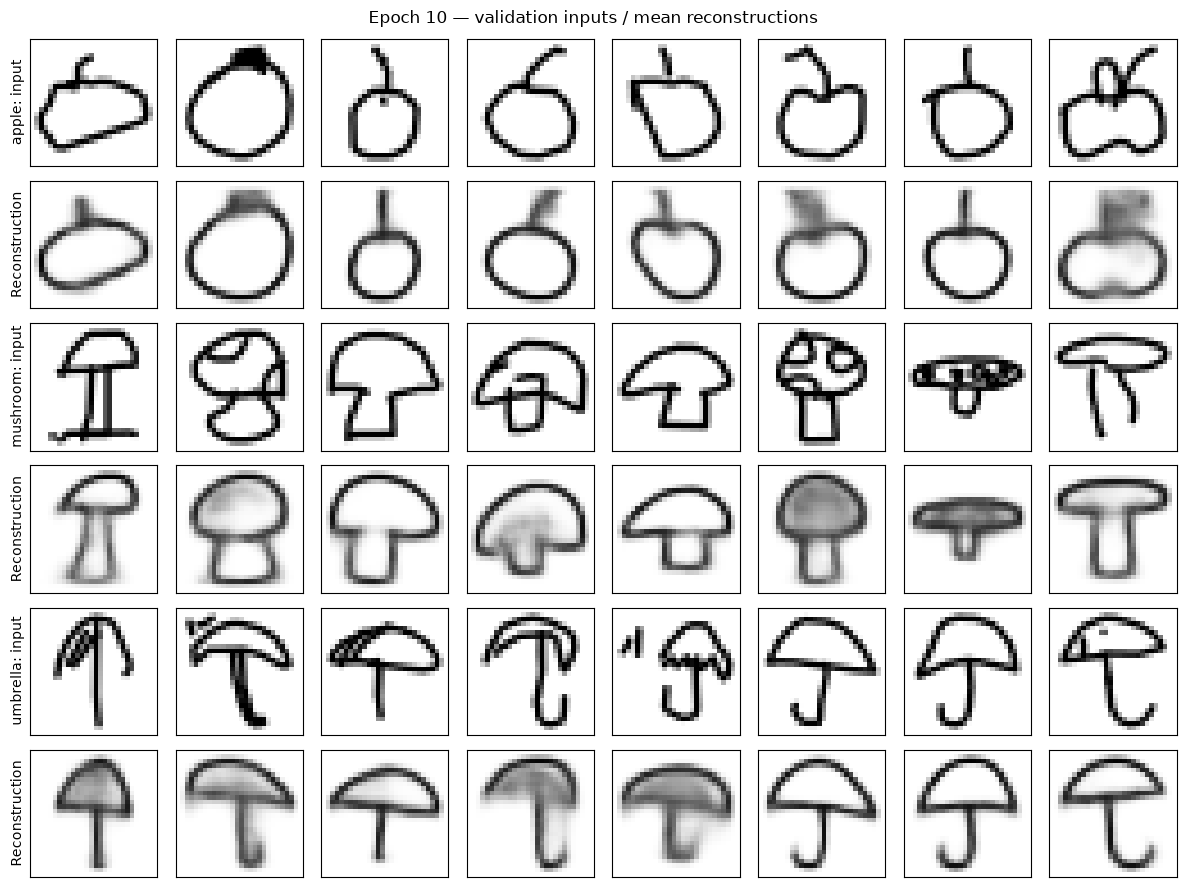

Epoch 11/20 | Train: 169.10 | Validation: 171.11 | Reconstruction: 152.09 | KL: 19.02 | Time: 5.0s
Epoch 12/20 | Train: 168.57 | Validation: 170.21 | Reconstruction: 151.10 | KL: 19.11 | Time: 5.0s
Epoch 13/20 | Train: 168.26 | Validation: 169.59 | Reconstruction: 150.89 | KL: 18.70 | Time: 5.0s
Epoch 14/20 | Train: 167.84 | Validation: 169.39 | Reconstruction: 150.16 | KL: 19.23 | Time: 5.1s
Epoch 15/20 | Train: 167.61 | Validation: 169.12 | Reconstruction: 149.73 | KL: 19.39 | Time: 5.1s


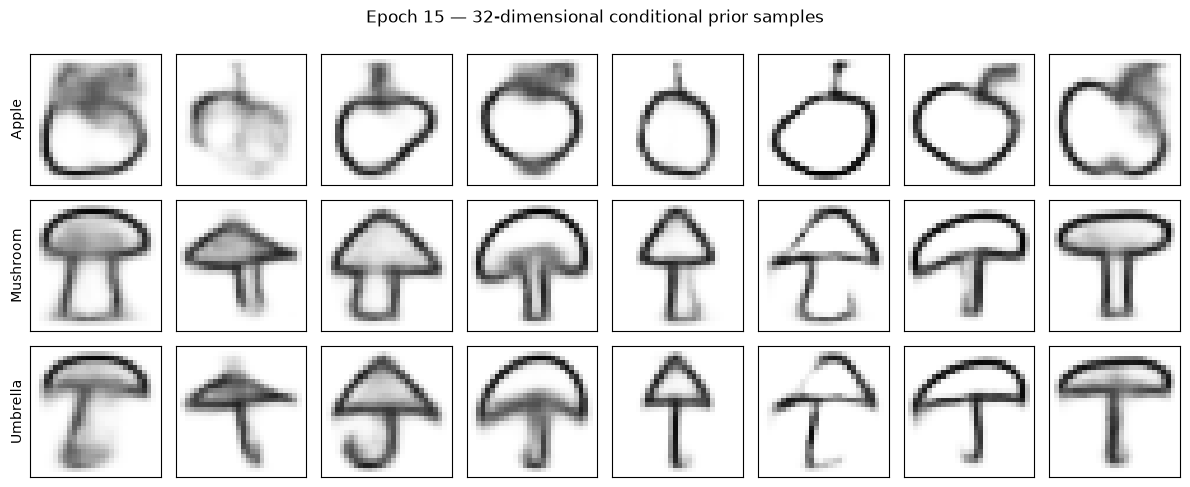

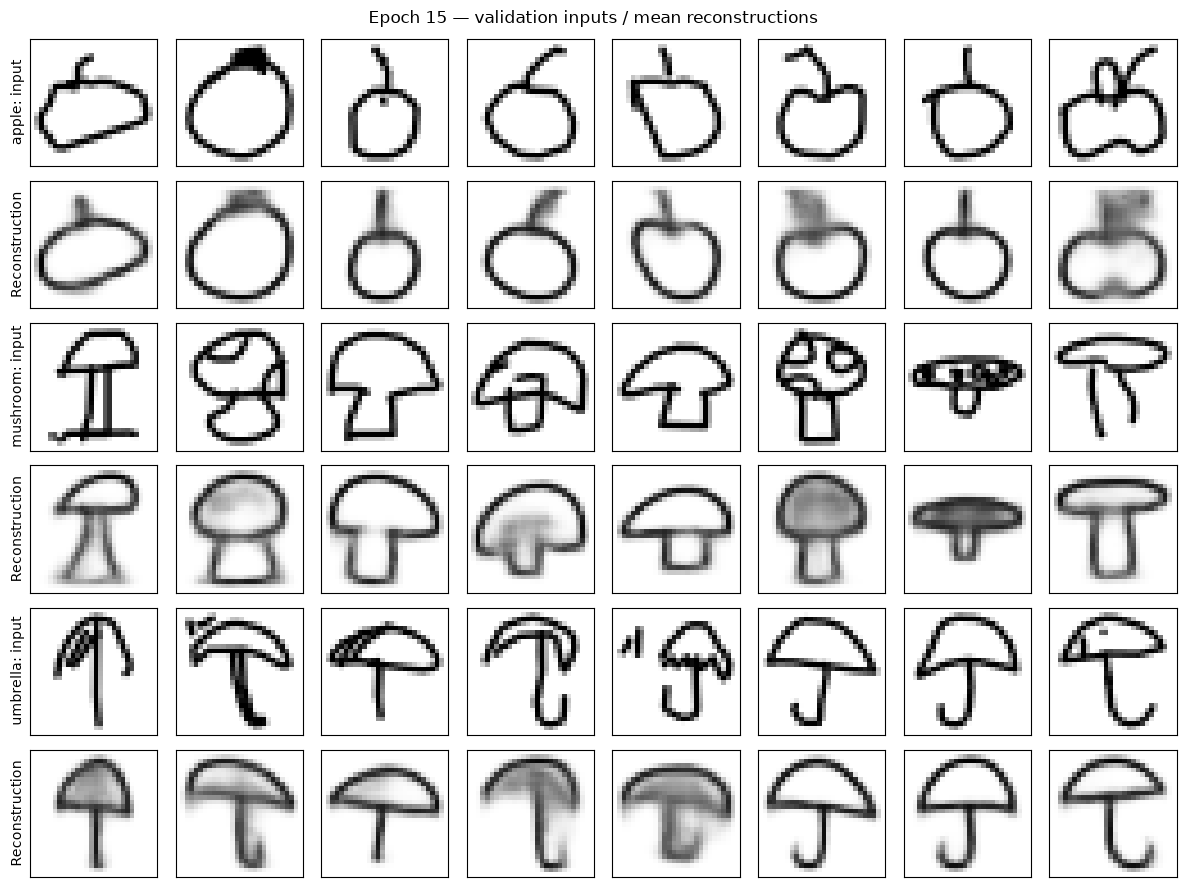

Epoch 16/20 | Train: 167.26 | Validation: 168.95 | Reconstruction: 149.74 | KL: 19.20 | Time: 5.0s
Epoch 17/20 | Train: 167.08 | Validation: 168.88 | Reconstruction: 149.49 | KL: 19.39 | Time: 5.0s
Epoch 18/20 | Train: 166.78 | Validation: 168.87 | Reconstruction: 149.81 | KL: 19.06 | Time: 5.0s
Epoch 19/20 | Train: 166.59 | Validation: 168.46 | Reconstruction: 149.12 | KL: 19.33 | Time: 5.0s
Epoch 20/20 | Train: 166.37 | Validation: 168.32 | Reconstruction: 149.16 | KL: 19.16 | Time: 5.0s


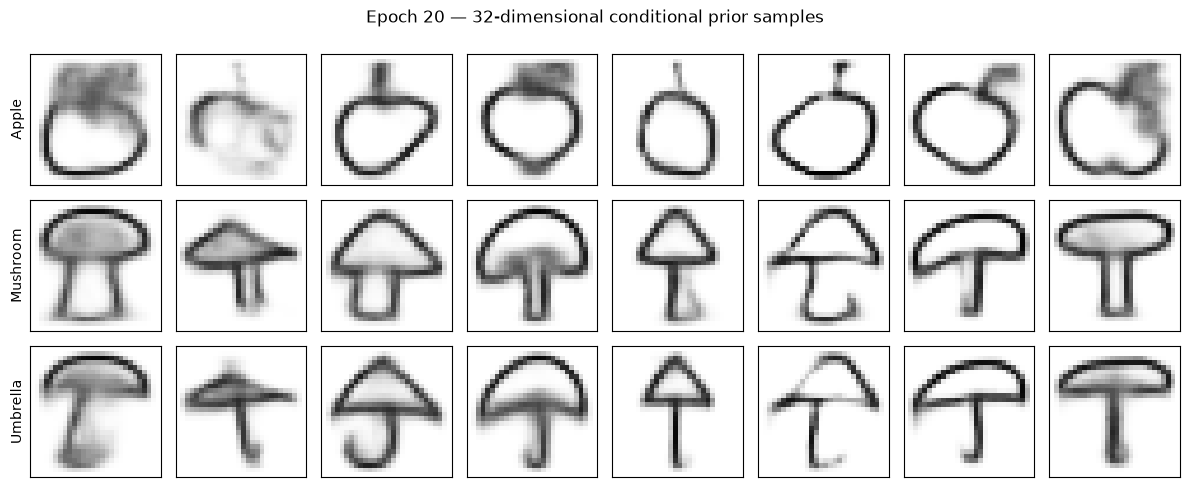

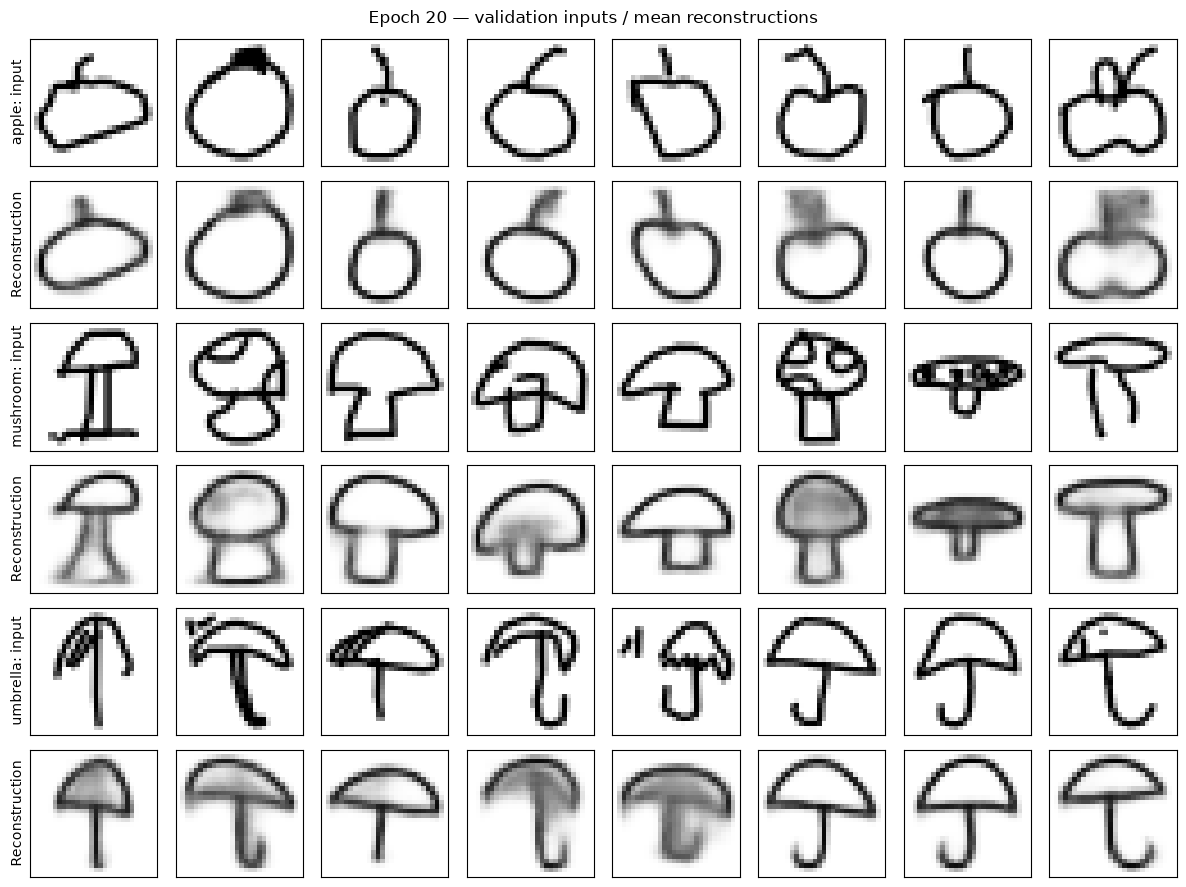

In [28]:
capacity_latest_path = capacity_run_dir / "checkpoints" / "latest.pt"
capacity_best_path = capacity_run_dir / "checkpoints" / "best.pt"

if capacity_history or capacity_latest_path.exists():
    raise RuntimeError(
        "This run has already started. Resume from its checkpoint "
        "instead of rerunning this cell."
    )

for epoch in range(1, CAPACITY_EPOCHS + 1):
    started = perf_counter()

    train_metrics = run_conditional_epoch(
        capacity_vae,
        capacity_train_loader,
        device,
        optimizer=capacity_optimizer,
    )
    validation_metrics = run_conditional_epoch(
        capacity_vae,
        capacity_validation_loader,
        device,
    )

    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()

    row = {
        "epoch": epoch,
        "seconds": perf_counter() - started,
        **{
            f"train_{metric}": train_metrics[metric]
            for metric in ("total", "reconstruction", "kl")
        },
        **{
            f"validation_{metric}": validation_metrics[metric]
            for metric in ("total", "reconstruction", "kl")
        },
    }
    capacity_history.append(row)

    for split, metrics in [
        ("train", train_metrics),
        ("validation", validation_metrics),
    ]:
        for category, values in metrics["per_category"].items():
            capacity_category_history.append({
                "epoch": epoch,
                "split": split,
                "category": category,
                **values,
            })

    improved = row["validation_total"] < capacity_best_validation
    if improved:
        capacity_best_validation = row["validation_total"]

    checkpoint = {
        "epoch": epoch,
        "model": capacity_vae.state_dict(),
        "optimizer": capacity_optimizer.state_dict(),
        "config": capacity_config,
        "history": capacity_history,
        "category_history": capacity_category_history,
        "best_validation": capacity_best_validation,
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "loader_rng": capacity_shuffle_generator.get_state(),
        "validation_loader_rng": (
            capacity_validation_loader.generator.get_state()
        ),
    }

    if device.type == "mps":
        checkpoint["mps_rng"] = torch.mps.get_rng_state()
    elif device.type == "cuda":
        checkpoint["cuda_rng"] = torch.cuda.get_rng_state_all()

    temporary_path = capacity_latest_path.with_suffix(".pt.partial")
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(capacity_latest_path)

    if improved:
        shutil.copy2(capacity_latest_path, capacity_best_path)

    pd.DataFrame(capacity_history).to_csv(
        capacity_run_dir / "reports" / "training_history.csv",
        index=False,
    )
    pd.DataFrame(capacity_category_history).to_csv(
        capacity_run_dir / "reports" / "category_history.csv",
        index=False,
    )

    print(
        f"Epoch {epoch:02d}/{CAPACITY_EPOCHS} | "
        f"Train: {row['train_total']:.2f} | "
        f"Validation: {row['validation_total']:.2f} | "
        f"Reconstruction: {row['validation_reconstruction']:.2f} | "
        f"KL: {row['validation_kl']:.2f} | "
        f"Time: {row['seconds']:.1f}s"
    )

    if epoch == 1 or epoch % 5 == 0:
        capacity_vae.eval()
        with torch.no_grad():
            logits, _, _ = capacity_vae(
                conditional_fixed_images,
                conditional_fixed_labels,
                sample=False,
            )
            reconstructions = logits.sigmoid().cpu()
            generations = capacity_vae.decode(
                capacity_fixed_latent,
                conditional_fixed_labels,
            ).sigmoid().cpu()

        fig, axes = plt.subplots(
            len(CATEGORIES), 8, figsize=(12, 5)
        )
        for category_id, category in enumerate(CATEGORIES):
            for column in range(8):
                index = category_id * 8 + column
                ax = axes[category_id, column]
                ax.imshow(
                    generations[index, 0],
                    cmap="gray_r", vmin=0, vmax=1,
                    interpolation="nearest",
                )
                ax.set_xticks([])
                ax.set_yticks([])
                if column == 0:
                    ax.set_ylabel(category.capitalize())

        fig.suptitle(
            f"Epoch {epoch} — 32-dimensional conditional prior samples"
        )
        fig.tight_layout()
        fig.savefig(
            capacity_run_dir / "figures" / f"generations_{epoch:02d}.png",
            dpi=150,
            bbox_inches="tight",
        )
        plt.show()
        plt.close(fig)

        fig, axes = plt.subplots(
            2 * len(CATEGORIES), 8, figsize=(12, 9)
        )
        for category_id, category in enumerate(CATEGORIES):
            for column in range(8):
                index = category_id * 8 + column
                for offset, images, label in [
                    (0, conditional_fixed_images, f"{category}: input"),
                    (1, reconstructions, "Reconstruction"),
                ]:
                    ax = axes[2 * category_id + offset, column]
                    ax.imshow(
                        images[index, 0].cpu(),
                        cmap="gray_r", vmin=0, vmax=1,
                        interpolation="nearest",
                    )
                    ax.set_xticks([])
                    ax.set_yticks([])
                    if column == 0:
                        ax.set_ylabel(label)

        fig.suptitle(
            f"Epoch {epoch} — validation inputs / mean reconstructions"
        )
        fig.tight_layout()
        fig.savefig(
            capacity_run_dir / "figures"
            / f"reconstructions_{epoch:02d}.png",
            dpi=150,
            bbox_inches="tight",
        )
        plt.show()
        plt.close(fig)

In [29]:
comparison_rows = []

for name, history in [
    ("Conditional VAE — latent 16", conditional_history),
    ("Conditional VAE — latent 32", capacity_history),
]:
    frame = pd.DataFrame(history)
    best = frame.loc[frame["validation_total"].idxmin()]

    comparison_rows.append({
        "model": name,
        "best_epoch": int(best["epoch"]),
        "validation_total": best["validation_total"],
        "validation_reconstruction": best["validation_reconstruction"],
        "validation_kl": best["validation_kl"],
    })

capacity_comparison = pd.DataFrame(comparison_rows)
capacity_comparison.to_csv(
    capacity_run_dir / "reports" / "latent_capacity_comparison.csv",
    index=False,
)
display(capacity_comparison.round(2))

,model,best_epoch,validation_total,validation_reconstruction,validation_kl
0,Conditional VAE — latent 16,18,162.41,140.12,22.29
1,Conditional VAE — latent 32,20,168.32,149.16,19.16


### Latent-capacity experiment results

The 16-dimensional conditional VAE achieved its lowest validation loss at epoch 18 (162.41), compared with 168.32 at epoch 20 for the 32-dimensional model. Reconstruction loss was also lower for the 16-dimensional model: 140.12 versus 149.16.

Increasing latent capacity did not improve this experiment. The inspected 32-dimensional prior samples contained faint or incomplete outlines and continued ambiguity between mushrooms and umbrellas. The 16-dimensional model remains the leading candidate.

These findings apply to the current architecture, training budget, and single random seed. They do not establish that smaller latent spaces are universally better. The test set was not used for this decision.

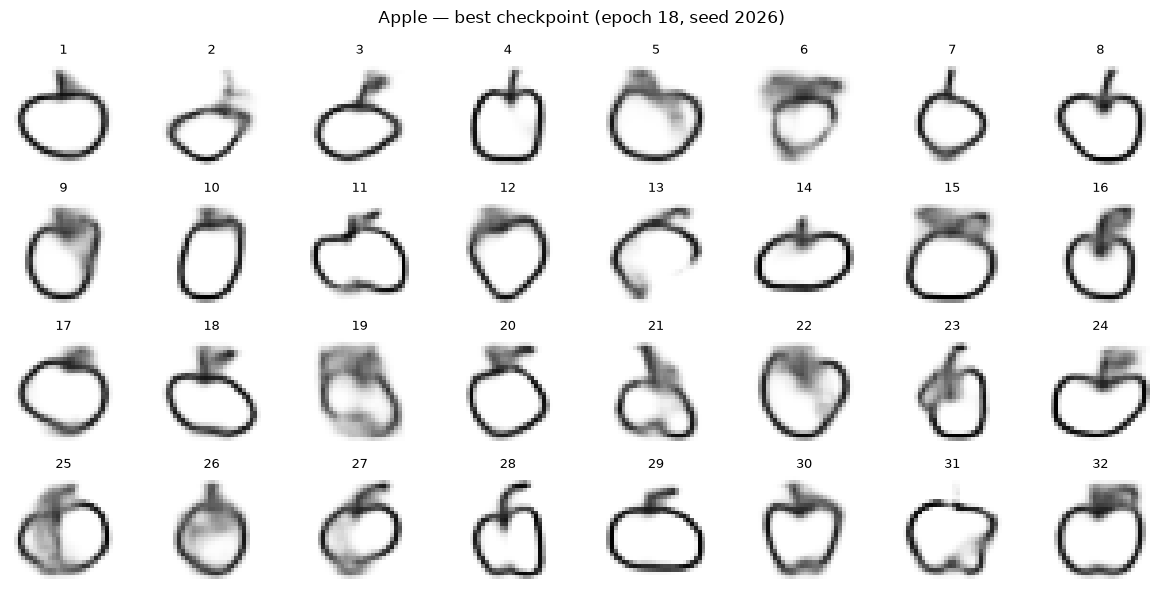

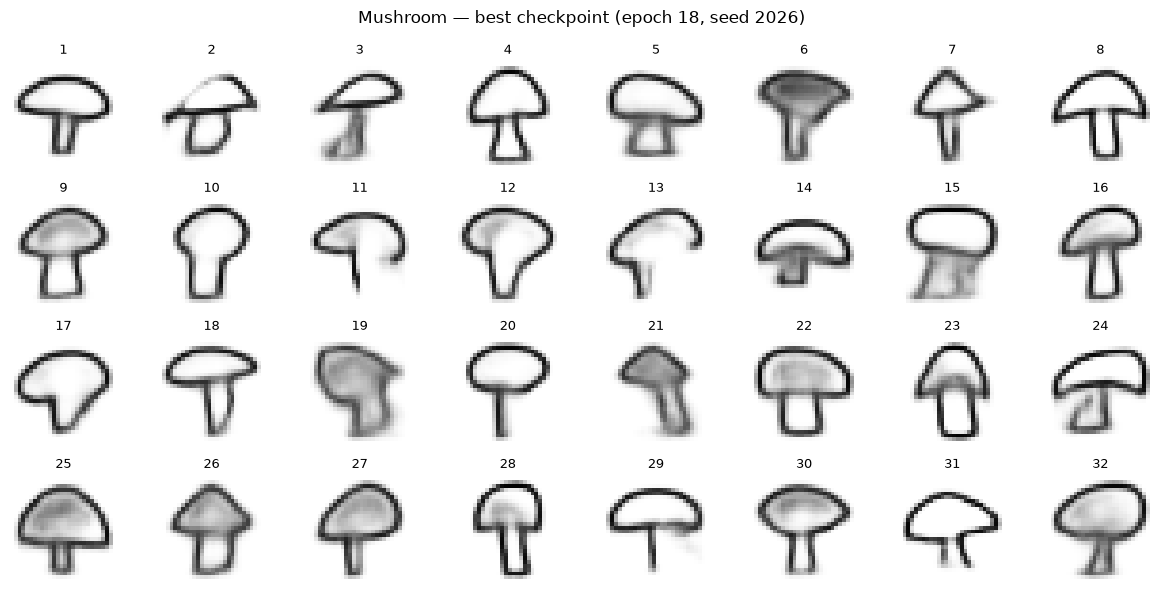

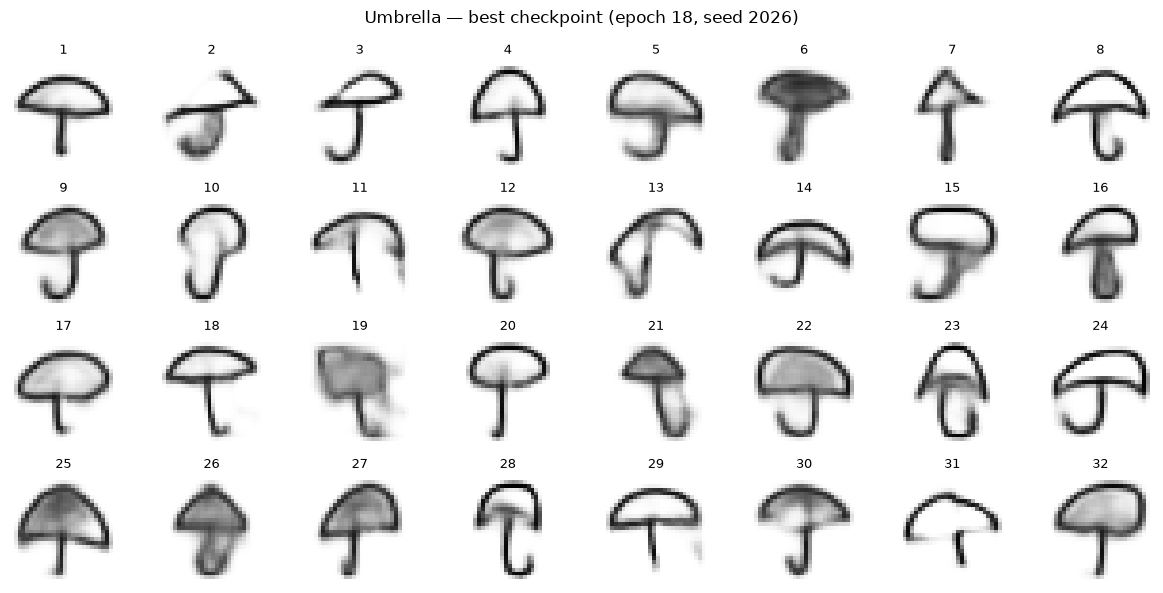

Checkpoint epoch: 18
Generated samples: 96


In [30]:
# Load a checkpoint created locally by this notebook.
# It includes Python/NumPy state, so it requires weights_only=False.
baseline_checkpoint = torch.load(
    conditional_run_dir / "checkpoints" / "best.pt",
    map_location="cpu",
    weights_only=False,
)

baseline_review_model = ConditionalSketchVAE(
    latent_dim=baseline_checkpoint["config"]["latent_dim"],
    num_categories=len(CATEGORIES),
)
baseline_review_model.load_state_dict(baseline_checkpoint["model"])
baseline_review_model = baseline_review_model.to(device).eval()

REVIEW_SEED = 2026
SAMPLES_PER_CATEGORY = 32

review_generator = torch.Generator().manual_seed(REVIEW_SEED)
review_shared_latent = torch.randn(
    SAMPLES_PER_CATEGORY,
    baseline_review_model.latent_dim,
    generator=review_generator,
)

# Reuse each latent vector across categories to inspect label effects.
review_latent = review_shared_latent.repeat(len(CATEGORIES), 1).to(device)
review_labels = torch.arange(
    len(CATEGORIES), dtype=torch.long
).repeat_interleave(SAMPLES_PER_CATEGORY).to(device)

with torch.no_grad():
    review_samples = baseline_review_model.decode(
        review_latent, review_labels
    ).sigmoid().cpu()

for category_id, category in enumerate(CATEGORIES):
    fig, axes = plt.subplots(4, 8, figsize=(12, 6))

    for sample_index, ax in enumerate(axes.flat):
        index = category_id * SAMPLES_PER_CATEGORY + sample_index
        ax.imshow(
            review_samples[index, 0],
            cmap="gray_r",
            vmin=0,
            vmax=1,
            interpolation="nearest",
        )
        # Number every sample so failures can be discussed precisely.
        ax.set_title(str(sample_index + 1), fontsize=9)
        ax.axis("off")

    fig.suptitle(
        f"{category.capitalize()} — best checkpoint "
        f"(epoch {baseline_checkpoint['epoch']}, seed {REVIEW_SEED})"
    )
    fig.tight_layout()
    fig.savefig(
        conditional_run_dir / "figures" / f"prior_review_{category}.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

review_config = {
    "checkpoint": "best.pt",
    "checkpoint_epoch": int(baseline_checkpoint["epoch"]),
    "latent_dim": baseline_review_model.latent_dim,
    "seed": REVIEW_SEED,
    "samples_per_category": SAMPLES_PER_CATEGORY,
    "shared_latent_across_categories": True,
    "sample_selection": "All generated samples displayed without filtering",
}

(conditional_run_dir / "reports" / "prior_review_config.json").write_text(
    json.dumps(review_config, indent=2),
    encoding="utf-8",
)

print("Checkpoint epoch:", baseline_checkpoint["epoch"])
print("Generated samples:", len(review_samples))

## 13. Experiment: category conditioning throughout the decoder

The baseline supplies the category label at the decoder's initial dense layer. This experiment additionally appends one-hot category maps before each decoder convolution, making the requested category available at both spatial resolutions and the output layer.

Keep 16 latent dimensions, the existing encoder, convolution widths, data splits, loss weights, learning rate, and 20-epoch training budget. Train a fresh model and compare its best validation checkpoint with the baseline using the same fixed generation inputs.

The hypothesis is that repeated conditioning improves category-specific features, particularly mushroom stems versus umbrella handles. It may not resolve blurred strokes or broken outlines.

In [31]:
class SpatialConditionalSketchVAE(ConditionalSketchVAE):
    """Conditional VAE with category maps throughout its decoder.

    Parameters
    ----------
    latent_dim : int
        Number of latent dimensions.
    num_categories : int
        Number of supported category labels.
    """

    def __init__(self, latent_dim=16, num_categories=3):
        super().__init__(latent_dim, num_categories)

        # Replace the baseline decoder; retain its widths and resolutions.
        self.decoder = nn.ModuleList([
            nn.Conv2d(64 + num_categories, 32, kernel_size=3, padding=1),
            nn.Conv2d(32 + num_categories, 16, kernel_size=3, padding=1),
            nn.Conv2d(16 + num_categories, 1, kernel_size=3, padding=1),
        ])

    def decode(self, latent, labels):
        """Decode with category labels supplied at each convolution.

        Parameters
        ----------
        latent : torch.Tensor
            Latent vectors with shape (batch, latent_dim).
        labels : torch.Tensor
            Int64 category IDs with shape (batch,), on the latent device.

        Returns
        -------
        torch.Tensor
            Pixel logits with shape (batch, 1, 28, 28).
        """
        category_vectors = F.one_hot(
            labels, num_classes=self.num_categories
        ).to(dtype=latent.dtype)

        hidden = self.decoder_input(
            torch.cat([latent, category_vectors], dim=1)
        ).reshape(-1, 64, 7, 7)

        for index, convolution in enumerate(self.decoder):
            # Match the baseline: upsample before the first two convolutions.
            if index < 2:
                hidden = F.interpolate(
                    hidden, scale_factor=2, mode="nearest"
                )

            # Broadcast each image's category vector across its feature map.
            category_maps = category_vectors[:, :, None, None].expand(
                -1, -1, hidden.shape[2], hidden.shape[3]
            )
            hidden = convolution(
                torch.cat([hidden, category_maps], dim=1)
            )

            if index < 2:
                hidden = F.relu(hidden)

        return hidden


torch.manual_seed(SEED)
spatial_check_model = SpatialConditionalSketchVAE(
    latent_dim=16,
    num_categories=len(CATEGORIES),
).to(device)

check_images = conditional_example_images.to(device)
check_labels = conditional_example_labels.to(device)

check_logits, check_mean, check_log_variance = spatial_check_model(
    check_images, check_labels
)
check_losses = vae_loss(
    check_logits, check_images, check_mean, check_log_variance
)

assert check_logits.shape == (6, 1, 28, 28)
assert check_mean.shape == check_log_variance.shape == (6, 16)
assert all(torch.isfinite(loss).item() for loss in check_losses)

check_losses[0].backward()

assert all(
    parameter.grad is not None
    and torch.isfinite(parameter.grad).all().item()
    for parameter in spatial_check_model.parameters()
    if parameter.requires_grad
)

print(
    "Parameters:",
    f"{sum(p.numel() for p in spatial_check_model.parameters()):,}",
)
print("Reconstruction logits:", tuple(check_logits.shape))
print(f"Diagnostic loss: {check_losses[0].item():.2f}")
print("Shape and finite-gradient checks passed; no optimizer updates.")

# The actual experiment will initialize a separate fresh model.
del spatial_check_model

Parameters: 856,524
Reconstruction logits: (6, 1, 28, 28)
Diagnostic loss: 594.06
Shape and finite-gradient checks passed; no optimizer updates.


In [32]:
SPATIAL_EPOCHS = 20
SPATIAL_LATENT_DIM = 16

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

spatial_shuffle_generator = torch.Generator().manual_seed(SEED)

spatial_train_loader = DataLoader(
    conditional_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=spatial_shuffle_generator,
)
spatial_validation_loader = DataLoader(
    conditional_validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED + 1),
)

spatial_vae = SpatialConditionalSketchVAE(
    latent_dim=SPATIAL_LATENT_DIM,
    num_categories=len(CATEGORIES),
).to(device)

spatial_optimizer = torch.optim.Adam(
    spatial_vae.parameters(),
    lr=CONDITIONAL_LEARNING_RATE,
)

run_id = datetime.now(timezone.utc).strftime(
    "conditional_vae_spatial_%Y%m%dT%H%M%S_%fZ"
)
spatial_run_dir = PROJECT_ROOT / "runs" / run_id

for folder in ["figures", "reports", "checkpoints"]:
    (spatial_run_dir / folder).mkdir(parents=True, exist_ok=False)

spatial_config = {
    **conditional_config,
    "model": "spatial_conditional_convolutional_vae",
    "latent_dim": SPATIAL_LATENT_DIM,
    "epochs": SPATIAL_EPOCHS,
    "comparison_run": conditional_run_dir.name,
    "experiment": "Category maps before every decoder convolution",
}

(spatial_run_dir / "reports" / "config.json").write_text(
    json.dumps(spatial_config, indent=2),
    encoding="utf-8",
)
multicategory_manifest.to_csv(
    spatial_run_dir / "reports" / "split_manifest.csv",
    index=False,
)

# Clone the baseline display inputs without sampling new latent vectors.
spatial_fixed_latent = conditional_fixed_latent.detach().clone()

torch.save(
    {
        "validation_images": conditional_fixed_images.cpu(),
        "validation_labels": conditional_fixed_labels.cpu(),
        "prior_latent": spatial_fixed_latent.cpu(),
        "prior_labels": conditional_fixed_labels.cpu(),
    },
    spatial_run_dir / "checkpoints" / "fixed_display_inputs.pt",
)
shutil.copy2(
    conditional_run_dir / "reports" / "fixed_validation_samples.csv",
    spatial_run_dir / "reports" / "fixed_validation_samples.csv",
)

spatial_history = []
spatial_category_history = []
spatial_best_validation = float("inf")

print("Run directory:", spatial_run_dir)
print("Epochs:", SPATIAL_EPOCHS)
print("Fixed prior shape:", tuple(spatial_fixed_latent.shape))
print("Prepared fresh model and optimizer; no training updates performed.")

Run directory: /Users/ashlabs/Projects/Masters in AI/github/sketch-generation-vae/runs/conditional_vae_spatial_20261109T203254_118047Z
Epochs: 20
Fixed prior shape: (24, 16)
Prepared fresh model and optimizer; no training updates performed.


Epoch 01/20 | Train: 255.85 | Validation: 213.04 | Reconstruction: 200.72 | KL: 12.32 | Time: 6.6s


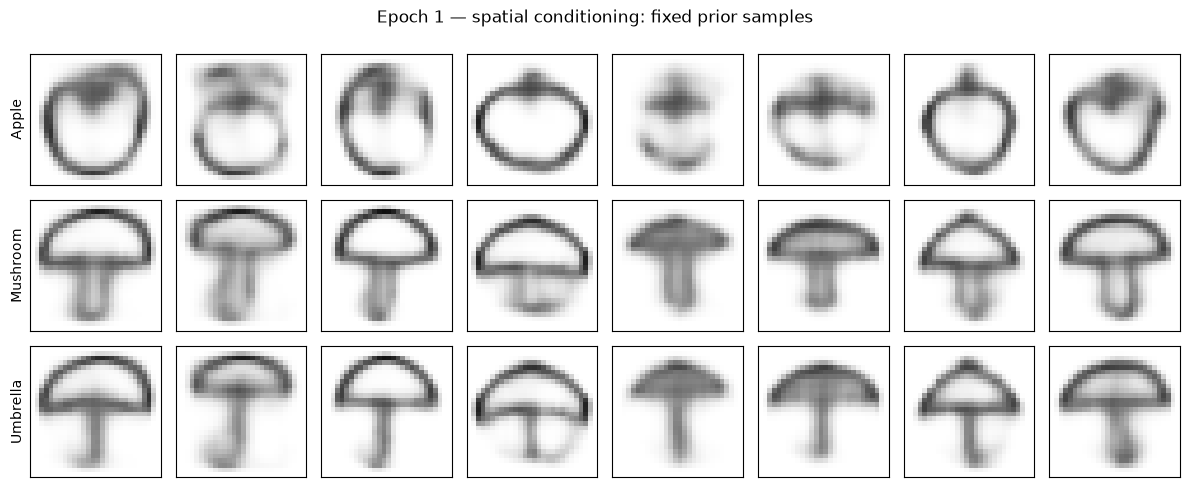

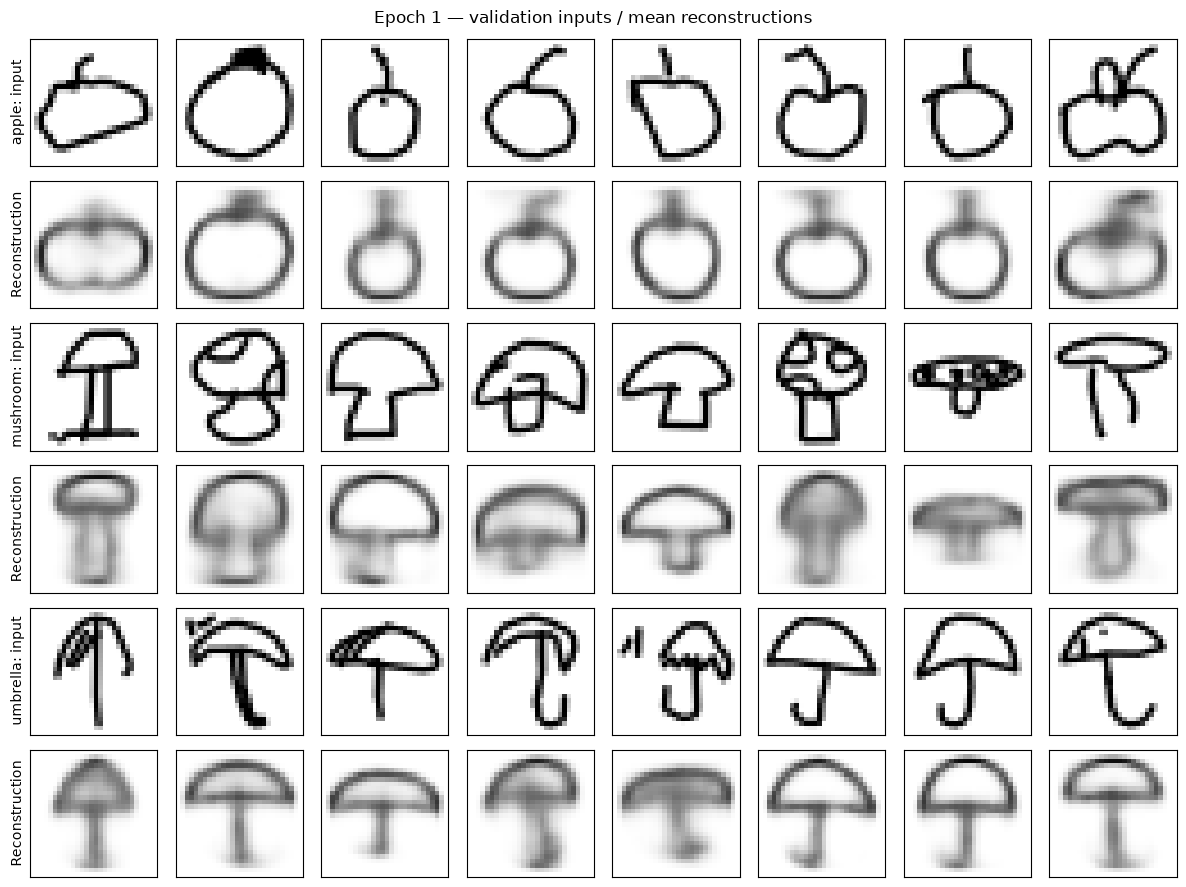

Epoch 02/20 | Train: 193.33 | Validation: 181.90 | Reconstruction: 163.46 | KL: 18.45 | Time: 6.1s
Epoch 03/20 | Train: 176.91 | Validation: 174.53 | Reconstruction: 154.70 | KL: 19.83 | Time: 5.9s
Epoch 04/20 | Train: 172.00 | Validation: 171.16 | Reconstruction: 150.83 | KL: 20.33 | Time: 5.9s
Epoch 05/20 | Train: 169.79 | Validation: 169.61 | Reconstruction: 148.99 | KL: 20.62 | Time: 5.9s


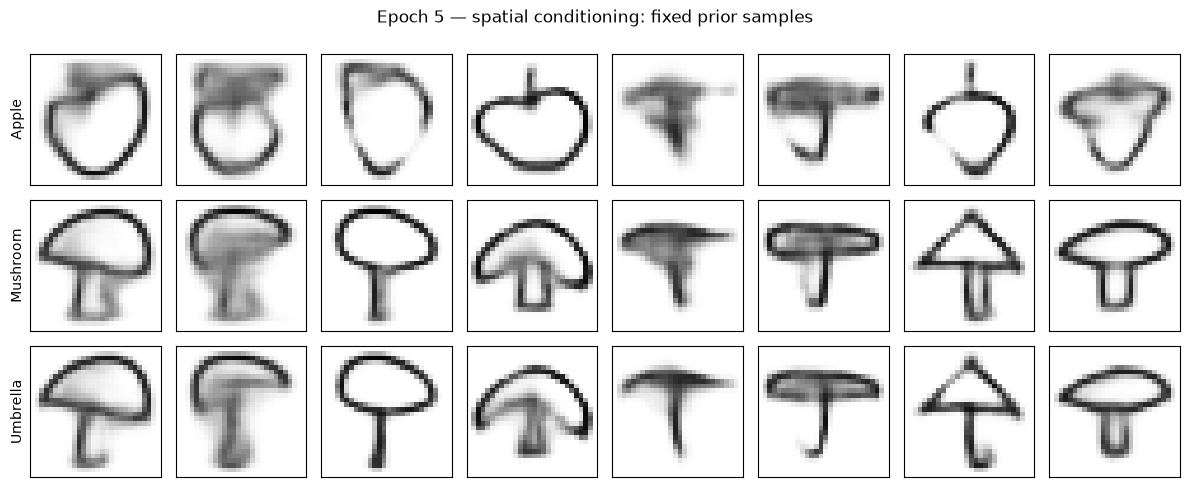

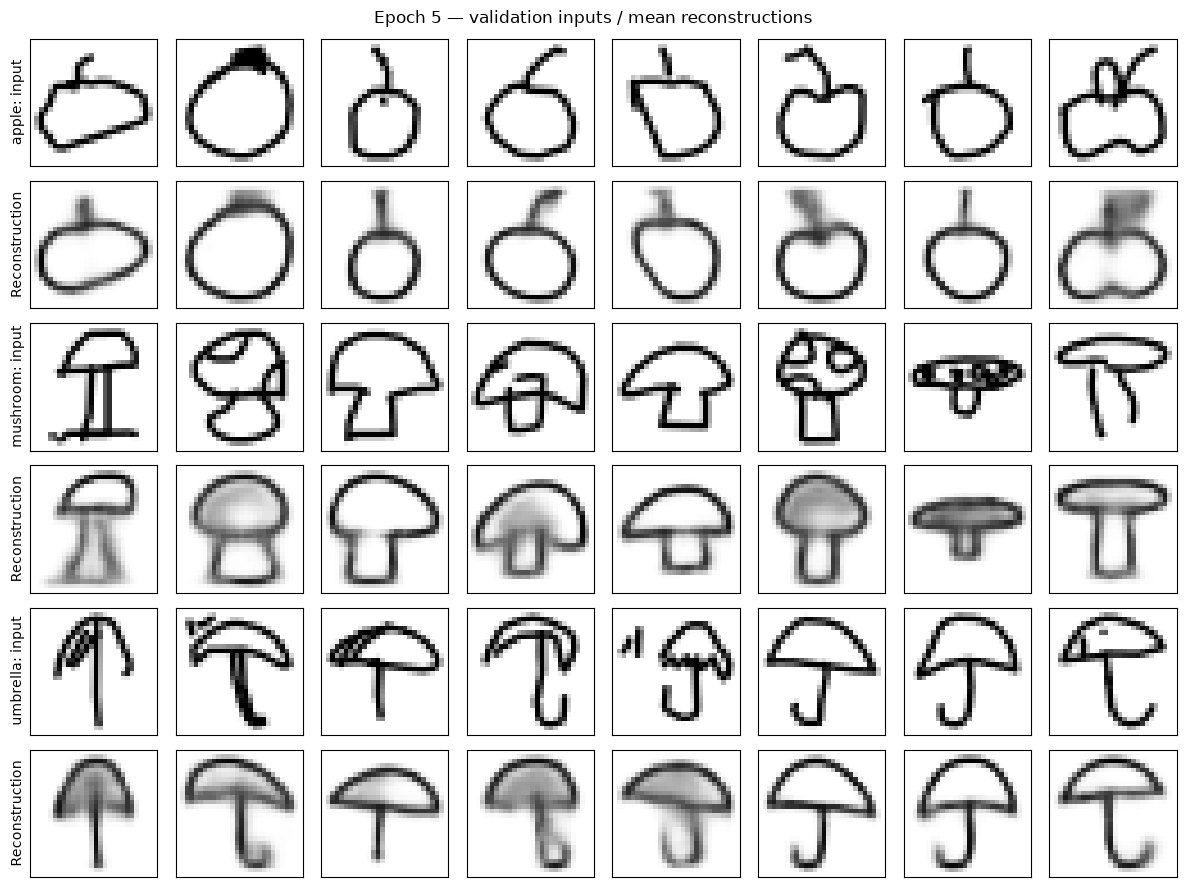

Epoch 06/20 | Train: 168.27 | Validation: 168.86 | Reconstruction: 148.63 | KL: 20.22 | Time: 5.9s
Epoch 07/20 | Train: 167.23 | Validation: 168.17 | Reconstruction: 147.79 | KL: 20.38 | Time: 5.9s
Epoch 08/20 | Train: 166.54 | Validation: 167.08 | Reconstruction: 146.44 | KL: 20.64 | Time: 6.0s
Epoch 09/20 | Train: 165.87 | Validation: 167.08 | Reconstruction: 146.49 | KL: 20.59 | Time: 5.9s
Epoch 10/20 | Train: 165.29 | Validation: 166.30 | Reconstruction: 145.52 | KL: 20.78 | Time: 5.9s


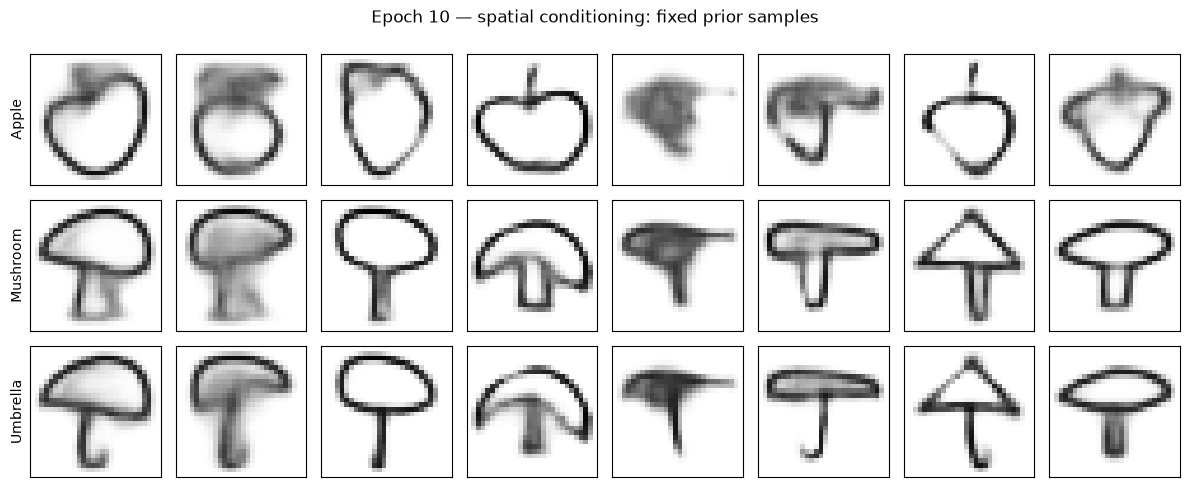

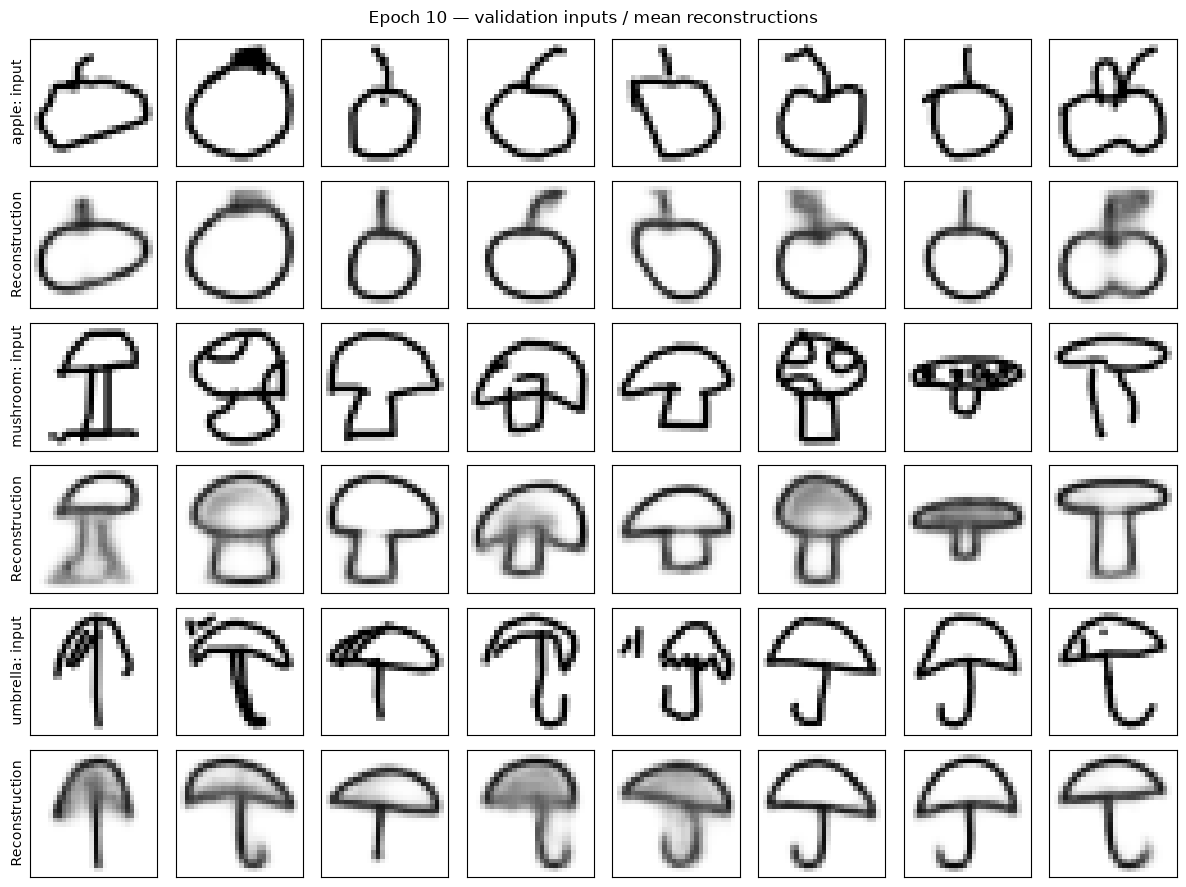

Epoch 11/20 | Train: 164.82 | Validation: 166.34 | Reconstruction: 145.15 | KL: 21.19 | Time: 5.9s
Epoch 12/20 | Train: 164.49 | Validation: 166.27 | Reconstruction: 145.42 | KL: 20.84 | Time: 5.9s
Epoch 13/20 | Train: 164.09 | Validation: 165.35 | Reconstruction: 144.74 | KL: 20.60 | Time: 5.9s
Epoch 14/20 | Train: 163.81 | Validation: 165.43 | Reconstruction: 144.39 | KL: 21.04 | Time: 5.9s
Epoch 15/20 | Train: 163.49 | Validation: 165.29 | Reconstruction: 144.57 | KL: 20.72 | Time: 5.9s


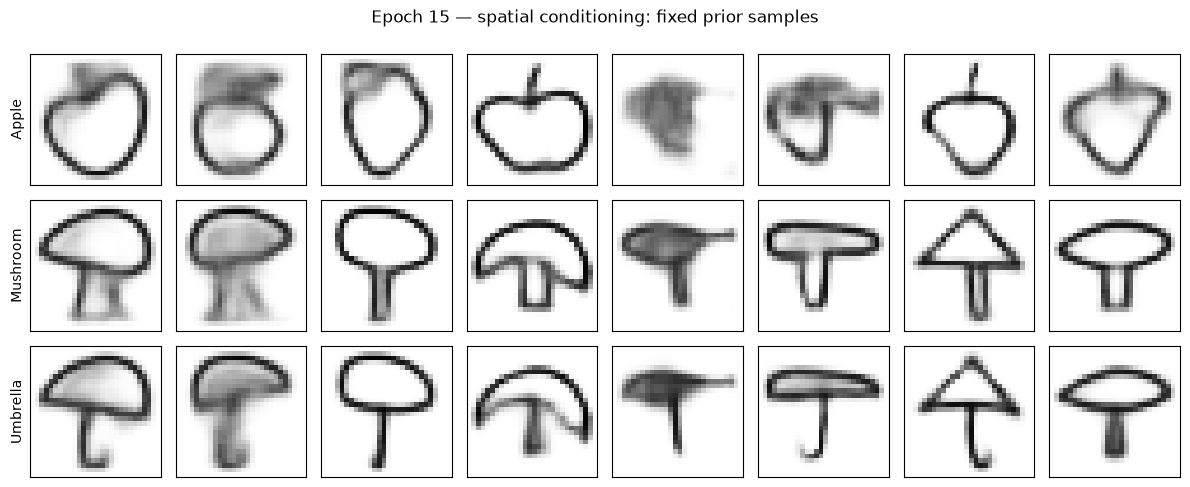

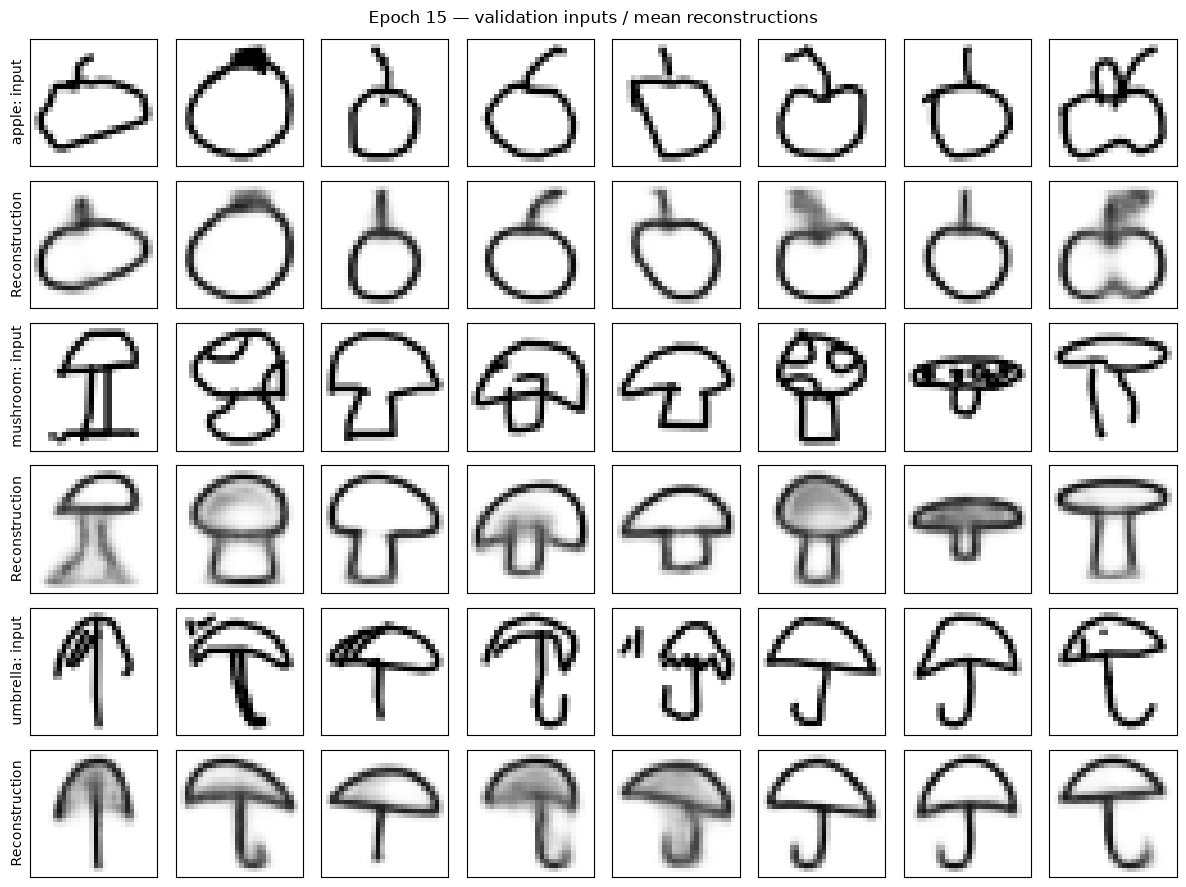

Epoch 16/20 | Train: 163.27 | Validation: 164.70 | Reconstruction: 144.35 | KL: 20.35 | Time: 5.9s
Epoch 17/20 | Train: 163.04 | Validation: 165.12 | Reconstruction: 144.15 | KL: 20.98 | Time: 5.9s
Epoch 18/20 | Train: 162.78 | Validation: 164.43 | Reconstruction: 143.44 | KL: 20.98 | Time: 5.9s
Epoch 19/20 | Train: 162.64 | Validation: 164.29 | Reconstruction: 143.53 | KL: 20.76 | Time: 5.9s
Epoch 20/20 | Train: 162.38 | Validation: 164.25 | Reconstruction: 143.62 | KL: 20.63 | Time: 5.9s


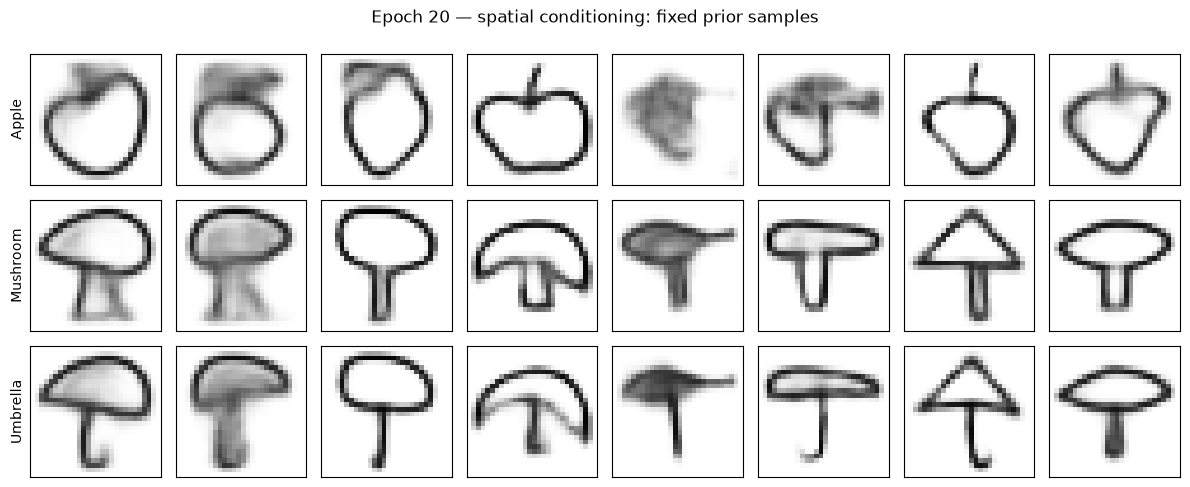

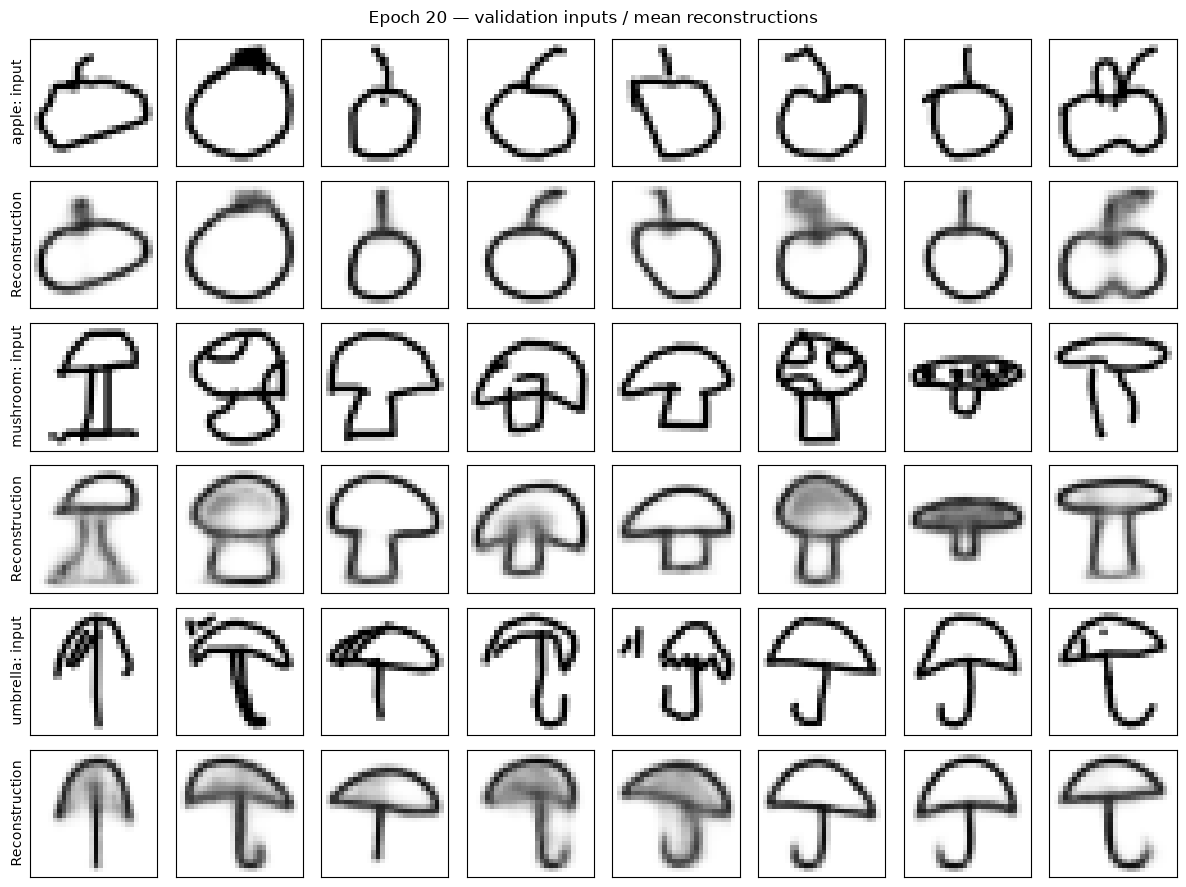

In [33]:
spatial_latest_path = spatial_run_dir / "checkpoints" / "latest.pt"
spatial_best_path = spatial_run_dir / "checkpoints" / "best.pt"

if spatial_history or spatial_latest_path.exists():
    raise RuntimeError(
        "This run has already started. Resume from its checkpoint "
        "instead of rerunning this cell."
    )

for epoch in range(1, SPATIAL_EPOCHS + 1):
    started = perf_counter()

    train_metrics = run_conditional_epoch(
        spatial_vae,
        spatial_train_loader,
        device,
        optimizer=spatial_optimizer,
    )
    validation_metrics = run_conditional_epoch(
        spatial_vae,
        spatial_validation_loader,
        device,
    )

    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()

    row = {
        "epoch": epoch,
        "seconds": perf_counter() - started,
        **{
            f"train_{metric}": train_metrics[metric]
            for metric in ("total", "reconstruction", "kl")
        },
        **{
            f"validation_{metric}": validation_metrics[metric]
            for metric in ("total", "reconstruction", "kl")
        },
    }
    spatial_history.append(row)

    for split, metrics in [
        ("train", train_metrics),
        ("validation", validation_metrics),
    ]:
        for category, values in metrics["per_category"].items():
            spatial_category_history.append({
                "epoch": epoch,
                "split": split,
                "category": category,
                **values,
            })

    improved = row["validation_total"] < spatial_best_validation
    if improved:
        spatial_best_validation = row["validation_total"]

    checkpoint = {
        "epoch": epoch,
        "model": spatial_vae.state_dict(),
        "optimizer": spatial_optimizer.state_dict(),
        "config": spatial_config,
        "history": spatial_history,
        "category_history": spatial_category_history,
        "best_validation": spatial_best_validation,
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "loader_rng": spatial_shuffle_generator.get_state(),
        "validation_loader_rng": (
            spatial_validation_loader.generator.get_state()
        ),
    }

    if device.type == "mps":
        checkpoint["mps_rng"] = torch.mps.get_rng_state()
    elif device.type == "cuda":
        checkpoint["cuda_rng"] = torch.cuda.get_rng_state_all()

    temporary_path = spatial_latest_path.with_suffix(".pt.partial")
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(spatial_latest_path)

    if improved:
        shutil.copy2(spatial_latest_path, spatial_best_path)

    pd.DataFrame(spatial_history).to_csv(
        spatial_run_dir / "reports" / "training_history.csv",
        index=False,
    )
    pd.DataFrame(spatial_category_history).to_csv(
        spatial_run_dir / "reports" / "category_history.csv",
        index=False,
    )

    print(
        f"Epoch {epoch:02d}/{SPATIAL_EPOCHS} | "
        f"Train: {row['train_total']:.2f} | "
        f"Validation: {row['validation_total']:.2f} | "
        f"Reconstruction: {row['validation_reconstruction']:.2f} | "
        f"KL: {row['validation_kl']:.2f} | "
        f"Time: {row['seconds']:.1f}s"
    )

    if epoch == 1 or epoch % 5 == 0:
        spatial_vae.eval()
        with torch.no_grad():
            logits, _, _ = spatial_vae(
                conditional_fixed_images,
                conditional_fixed_labels,
                sample=False,
            )
            reconstructions = logits.sigmoid().cpu()
            generations = spatial_vae.decode(
                spatial_fixed_latent,
                conditional_fixed_labels,
            ).sigmoid().cpu()

        fig, axes = plt.subplots(
            len(CATEGORIES), 8, figsize=(12, 5)
        )
        for category_id, category in enumerate(CATEGORIES):
            for column in range(8):
                index = category_id * 8 + column
                ax = axes[category_id, column]
                ax.imshow(
                    generations[index, 0],
                    cmap="gray_r", vmin=0, vmax=1,
                    interpolation="nearest",
                )
                ax.set_xticks([])
                ax.set_yticks([])
                if column == 0:
                    ax.set_ylabel(category.capitalize())

        fig.suptitle(
            f"Epoch {epoch} — spatial conditioning: fixed prior samples"
        )
        fig.tight_layout()
        fig.savefig(
            spatial_run_dir / "figures" / f"generations_{epoch:02d}.png",
            dpi=150,
            bbox_inches="tight",
        )
        plt.show()
        plt.close(fig)

        fig, axes = plt.subplots(
            2 * len(CATEGORIES), 8, figsize=(12, 9)
        )
        for category_id, category in enumerate(CATEGORIES):
            for column in range(8):
                index = category_id * 8 + column

                for offset, images, label in [
                    (0, conditional_fixed_images, f"{category}: input"),
                    (1, reconstructions, "Reconstruction"),
                ]:
                    ax = axes[2 * category_id + offset, column]
                    ax.imshow(
                        images[index, 0].cpu(),
                        cmap="gray_r", vmin=0, vmax=1,
                        interpolation="nearest",
                    )
                    ax.set_xticks([])
                    ax.set_yticks([])
                    if column == 0:
                        ax.set_ylabel(label)

        fig.suptitle(
            f"Epoch {epoch} — validation inputs / mean reconstructions"
        )
        fig.tight_layout()
        fig.savefig(
            spatial_run_dir / "figures"
            / f"reconstructions_{epoch:02d}.png",
            dpi=150,
            bbox_inches="tight",
        )
        plt.show()
        plt.close(fig)

Spatial run image: /Users/ashlabs/Projects/Masters in AI/github/sketch-generation-vae/runs/conditional_vae_spatial_20261109T203254_118047Z/figures/generations_20.png


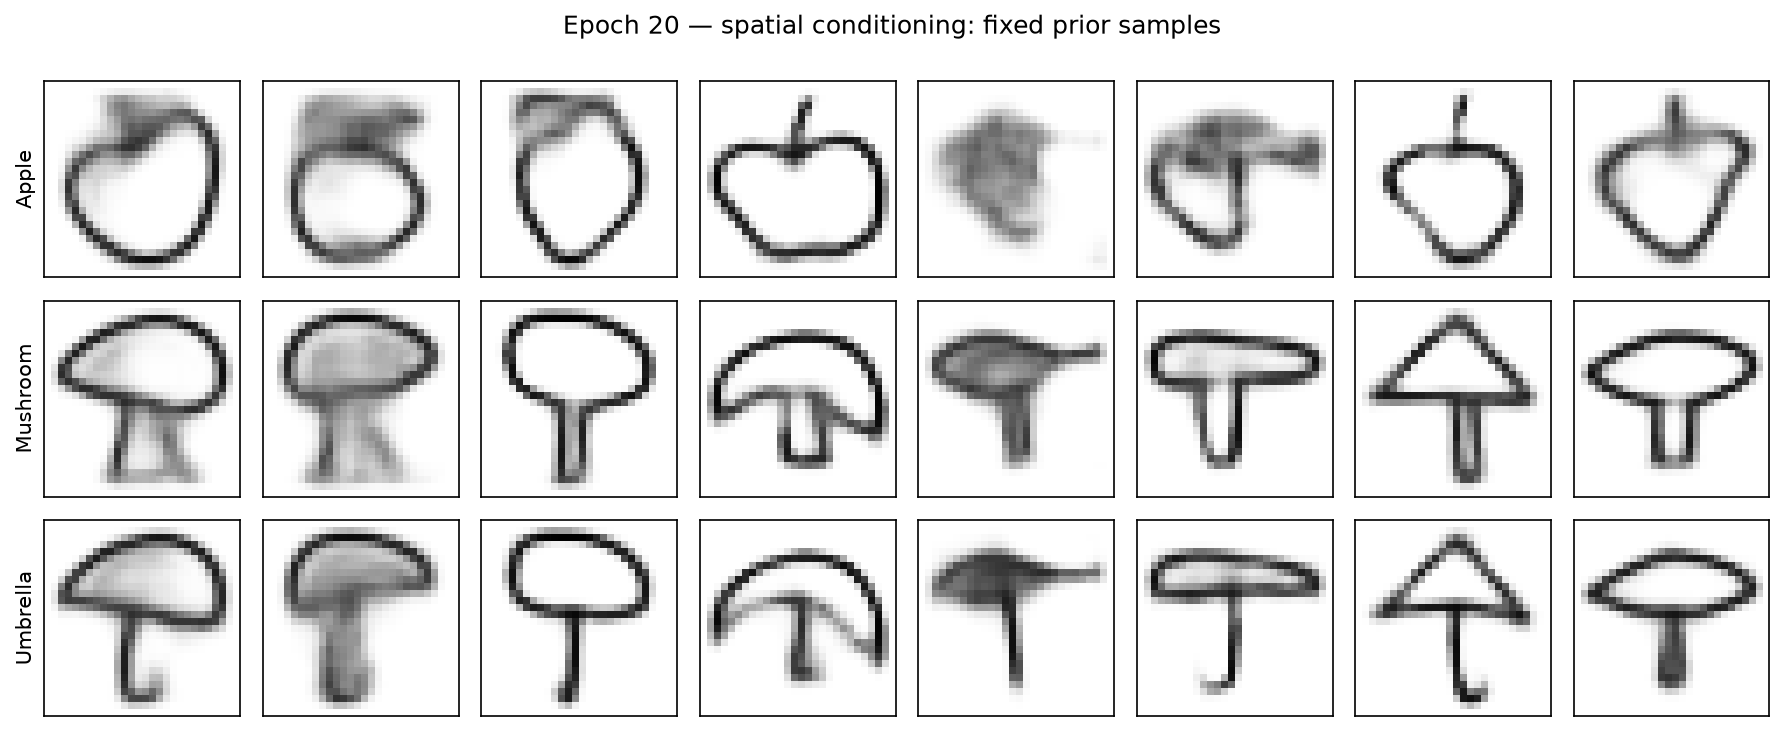

Best spatial epoch: 20
Best spatial validation loss: 164.25


In [34]:
from IPython.display import Image, display

image_path = spatial_run_dir / "figures" / "generations_20.png"
print("Spatial run image:", image_path)
display(Image(filename=str(image_path)))

spatial_history_df = pd.DataFrame(spatial_history)
best_spatial = spatial_history_df.loc[
    spatial_history_df["validation_total"].idxmin()
]

print("Best spatial epoch:", int(best_spatial["epoch"]))
print(f"Best spatial validation loss: {best_spatial['validation_total']:.2f}")

### Spatial-conditioning experiment results

Repeated category conditioning achieved a best validation loss of 164.25
at epoch 20, compared with 162.41 at epoch 18 for the original
16-dimensional conditional VAE.

The inspected prior samples continued to exhibit blurred strokes,
malformed outlines, and mushroom–umbrella ambiguity. This experiment
provided no clear evidence of improvement, so the original conditional
VAE remains the leading model.

The comparison uses one training seed and a limited visual sample.
The test set remains unused.